### **NAMA : FIRZANI NUR**
### **NIM : H061241026**
### **KELAS : C**
### **MATA KULIAH : KECERDASAN ARTIFISIAL**
---

# **Studi Kasus 1 - Geolistrik Schlumberger (VES): Akuifer Air Tanah Pesisir**

## 1. Prompt (struktur R-T-C-I-K-O-Q-V)

## Prompt 1 - Geolistrik: Eksplorasi Akuifer Air Tanah (Konfigurasi Schlumberger)

**Role:**
Kamu adalah seorang geofisikawan hidrogeologi senior yang berpengalaman menginterpretasi data geolistrik resistivitas 1D (VES) untuk eksplorasi air tanah di daerah pesisir.

**Task:**
Interpretasikan data sounding geolistrik konfigurasi Schlumberger pada satu titik VES untuk menentukan jumlah lapisan, resistivitas sebenarnya (ρ) dan ketebalan tiap lapisan, lalu tentukan lapisan mana yang berpotensi sebagai akuifer dan apakah ada indikasi intrusi air asin.

**Context:**
Lokasi studi adalah dataran aluvial pesisir dengan sedimen lempung, pasir, dan kerikil. Warga membutuhkan sumber air tawar untuk sumur bor dengan kedalaman maksimal sekitar 80 m. Nilai resistivitas air tanah tawar umumnya jauh lebih tinggi daripada air asin, sedangkan lempung memiliki resistivitas rendah yang dapat ambigu dengan zona asin (prinsip ekuivalensi).

**Input:**
Tabel data lapangan berisi kolom: AB/2 (m), MN/2 (m), arus I (mA), beda potensial ΔV (mV). Faktor geometri K dihitung dari AB/2 dan MN/2. Bila data belum dilampirkan, minta pengguna menempelkannya lebih dulu.

**Constraints:**
- Hitung resistivitas semu ρa = K·ΔV/I dan tampilkan rumus serta contoh perhitungan satu titik.
- Jangan mengarang nilai data yang tidak ada di tabel.
- Nyatakan secara eksplisit adanya ambiguitas ekuivalensi dan jangan menyimpulkan satu model tunggal sebagai pasti.
- Jangan mengklaim jenis batuan hanya dari resistivitas; gunakan kata "kemungkinan".
- Bila ada titik data yang tidak konsisten (lonjakan tajam pada pergantian MN), tandai dan jelaskan, jangan dihapus diam-diam.
- Failure behavior: jika data kurang dari 8 titik AB/2 atau tidak ada MN/2, hentikan analisis kuantitatif dan jelaskan data apa yang kurang.

**Output:**
Rencana output berupa narasi dan tabel teks (bukan gambar), terdiri dari dua artifact:
1. *Ringkasan interpretasi* (narasi): urutan lapisan dari atas ke bawah, rentang ρ dan ketebalan, lapisan akuifer yang diduga, serta kalimat rekomendasi kedalaman pengeboran dengan tingkat keyakinan.
2. *Tabel model lapisan* dalam format teks: lapisan ke-n, ρ (Ωm), ketebalan (m), kedalaman dasar (m), interpretasi litologi/fluida yang mungkin.

**Quality criteria:**
- Setiap angka pada tabel dapat ditelusuri ke data input.
- Ada minimal dua penjelasan alternatif untuk lapisan berresistivitas rendah (lempung vs air asin).
- Rekomendasi disertai tingkat keyakinan (rendah/sedang/tinggi) dan alasannya.
- Bahasa Indonesia baku dengan istilah teknis konsisten.

**Optional verification (V):**
Bila diperlukan, hitung ulang ρa untuk tiga titik data secara acak dan bandingkan dengan tabel, lalu laporkan selisihnya. Tuliskan juga satu uji kewajaran: apakah total ketebalan model masuk akal terhadap AB/2 maksimum (kedalaman penetrasi ≈ AB/2 ÷ 3 sampai AB/2 ÷ 2).

## 2. Kode dan hasil

Kode dipecah per tahap. Jalankan sel dari atas ke bawah.

### Persiapan: impor pustaka dan folder keluaran

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.special import j0
from scipy.optimize import least_squares

BASE = os.getcwd()          # folder tempat notebook ini disimpan
DATA = os.path.join(BASE, "data", "kasus1")
HASIL = os.path.join(BASE, "hasil", "kasus1")
os.makedirs(DATA, exist_ok=True)
os.makedirs(HASIL, exist_ok=True)
rng = np.random.default_rng(42)

### 1. FORWARD MODELLING VES SCHLUMBERGER (transformasi resistivitas Koefoed)

In [2]:
LAM = np.linspace(1e-5, 12.0, 6001)           # bilangan gelombang lambda (1/m)
_DLAM = LAM[1] - LAM[0]
_W = np.full(LAM.size, _DLAM)
_W[0] = _W[-1] = _DLAM / 2                    # bobot trapesium
_CACHE = {}


def transform_T1(rho, h, lam=LAM):
    """Resistivity transform T1(lambda) lewat rekursi Pekeris/Koefoed dari lapisan bawah."""
    n = len(rho)
    T = np.full_like(lam, rho[-1])
    for i in range(n - 2, -1, -1):
        th = np.tanh(lam * h[i])
        T = (T + rho[i] * th) / (1.0 + T * th / rho[i])
    return T


def potensial_f(r, rho, h):
    """f(r) = integral T1(l) J0(l r) dl ; bagian rho1/r dipisah agar integral stabil.
    Matriks J0 dihitung sekali per himpunan jarak r (cache) agar inversi cepat."""
    key = r.tobytes()
    if key not in _CACHE:
        _CACHE[key] = j0(np.outer(r, LAM)) * _W
    T1 = transform_T1(rho, h)
    return rho[0] / r + _CACHE[key] @ (T1 - rho[0])


def rho_semu(ab2, mn2, rho, h):
    """rho_a Schlumberger dengan MN berhingga: (s^2-m^2)/(2m) [f(s-m) - f(s+m)]."""
    ab2 = np.asarray(ab2, float)
    mn2 = np.asarray(mn2, float)
    fa = potensial_f(ab2 - mn2, rho, h)
    fb = potensial_f(ab2 + mn2, rho, h)
    return (ab2**2 - mn2**2) / (2 * mn2) * (fa - fb)

### 2. DATA (SINTETIK) : membuat tabel lapangan

In [3]:
rho_benar = np.array([80.0, 15.0, 50.0, 3.0])   # Ohm.m (tanah kering, lempung, pasir-air tawar, zona asin)
h_benar = np.array([1.5, 5.0, 30.0])            # m (lapisan terakhir = setengah ruang)

ab2 = np.array([1.5, 2, 3, 4, 6, 8, 10, 15, 20, 30, 40, 60, 80, 100, 130, 160.0])
mn2 = np.where(ab2 <= 10, 0.5, np.where(ab2 <= 40, 2.0, 5.0))

rho_a_teori = rho_semu(ab2, mn2, rho_benar, h_benar)
K = np.pi * (ab2**2 - mn2**2) / (2 * mn2)                  # faktor geometri Schlumberger
I_mA = np.array([300, 300, 300, 250, 250, 200, 200, 150, 150, 120, 100, 100, 80, 80, 60, 60.0])
dV_mV_bersih = rho_a_teori * (I_mA / 1000) / K * 1000      # dV = rho_a*I/K
dV_mV = dV_mV_bersih * (1 + 0.03 * rng.standard_normal(len(ab2)))   # noise acak 3 %
i_outlier = 10                                              # sisipkan 1 titik tidak konsisten (+30 %)
dV_mV[i_outlier] *= 1.30

tabel = pd.DataFrame({"AB/2 (m)": ab2, "MN/2 (m)": mn2, "I (mA)": I_mA, "dV (mV)": dV_mV.round(4)})
tabel.to_csv(os.path.join(DATA, "data_lapangan_VES_sintetik.csv"), index=False)

### 3. Pengolahan Seperti Data Lapangan

In [4]:
tabel["K (m)"] = K
tabel["rho_a (Ohm.m)"] = K * (tabel["dV (mV)"] / tabel["I (mA)"])    # mV/mA = ohm

# Contoh perhitungan satu titik (ditulis eksplisit, memenuhi syarat Constraints)
j = 5
contoh = (f"Contoh titik ke-{j+1}: AB/2={ab2[j]} m, MN/2={mn2[j]} m -> "
          f"K = pi(AB/2^2 - MN/2^2)/(2*MN/2) = {K[j]:.3f} m ; "
          f"rho_a = K*dV/I = {K[j]:.3f} x {dV_mV[j]:.4f} mV / {I_mA[j]:.0f} mA = "
          f"{tabel['rho_a (Ohm.m)'][j]:.2f} Ohm.m")
print(contoh)

# Deteksi titik tidak konsisten: residu terhadap interpolasi dua tetangga (log-log), robust (MAD)
la, lr = np.log10(ab2), np.log10(tabel["rho_a (Ohm.m)"].values)
resid = np.zeros(len(la))
for k in range(1, len(la) - 1):
    w = (la[k] - la[k - 1]) / (la[k + 1] - la[k - 1])
    pred = lr[k - 1] + w * (lr[k + 1] - lr[k - 1])
    resid[k] = lr[k] - pred
mad = np.median(np.abs(resid[1:-1] - np.median(resid[1:-1]))) * 1.4826
tabel["z-robust"] = resid / mad
tabel["Bendera"] = np.where(np.abs(tabel["z-robust"]) > 3.5, "TIDAK KONSISTEN", "")
print("Titik ditandai:", tabel.loc[tabel["Bendera"] != "", ["AB/2 (m)", "z-robust"]].values.tolist())

Contoh titik ke-6: AB/2=8.0 m, MN/2=0.5 m -> K = pi(AB/2^2 - MN/2^2)/(2*MN/2) = 200.277 m ; rho_a = K*dV/I = 200.277 x 20.5525 mV / 200 mA = 20.58 Ohm.m
Titik ditandai: [[40.0, 7.192191950366352]]


### 4. INVERSI 1D (least-squares di ruang log, loss robust)

In [5]:
rho_obs = tabel["rho_a (Ohm.m)"].values
sigma = 0.03                       # asumsi ketidakpastian relatif 3 %


def model_dari_param(p, n):
    return 10 ** p[:n], 10 ** p[n:]


def residual(p, n):
    rho, h = model_dari_param(p, n)
    return (np.log(rho_semu(ab2, mn2, rho, h)) - np.log(rho_obs)) / sigma


def batas(n):
    lb = np.r_[np.full(n, np.log10(0.5)), np.full(n - 1, np.log10(0.5))]
    ub = np.r_[np.full(n, np.log10(2000)), np.full(n - 1, np.log10(120))]
    return lb, ub


def inversi(n, seed=0, n_mulai=6):
    r = np.random.default_rng(seed)
    lb, ub = batas(n)
    terbaik = None
    for _ in range(n_mulai):
        p0 = np.r_[r.uniform(np.log10(2), np.log10(300), n), r.uniform(np.log10(1.0), np.log10(40), n - 1)]
        try:
            s = least_squares(residual, p0, args=(n,), bounds=(lb, ub), loss="soft_l1", f_scale=2.0,
                              max_nfev=50)
        except Exception:
            continue
        if terbaik is None or s.cost < terbaik.cost:
            terbaik = s
    return terbaik


def rms_persen(p, n, abaikan=None):
    rho, h = model_dari_param(p, n)
    d = np.log(rho_semu(ab2, mn2, rho, h)) - np.log(rho_obs)
    if abaikan is not None:
        d = d[~abaikan]
    return 100 * np.sqrt(np.mean(d**2))


mask_outlier = (tabel["Bendera"] != "").values
ringkas, solusi = [], {}
for n in (2, 3, 4, 5):
    s = inversi(n, seed=n)
    solusi[n] = s
    ringkas.append((n, rms_persen(s.x, n, mask_outlier), len(s.x)))
    print(f"Inversi {n} lapisan : RMS (tanpa outlier) = {ringkas[-1][1]:.2f} %")

Nobs = (~mask_outlier).sum()
bic = [Nobs * np.log((r / 100) ** 2) + k * np.log(Nobs) for _, r, k in ringkas]
n_terbaik = ringkas[int(np.argmin(bic))][0]
print("BIC:", dict(zip([r[0] for r in ringkas], np.round(bic, 1))), "-> dipilih", n_terbaik, "lapisan")
pd.DataFrame({"jumlah_lapisan": [r[0] for r in ringkas], "RMS_%": [round(r[1], 2) for r in ringkas],
              "jumlah_parameter": [r[2] for r in ringkas], "BIC": np.round(bic, 2)}
             ).to_csv(os.path.join(HASIL, "perbandingan_jumlah_lapisan.csv"), index=False)

p_best = solusi[n_terbaik].x
rho_est, h_est = model_dari_param(p_best, n_terbaik)
z_dasar = np.cumsum(h_est)

Inversi 2 lapisan : RMS (tanpa outlier) = 34.79 %
Inversi 3 lapisan : RMS (tanpa outlier) = 17.65 %
Inversi 4 lapisan : RMS (tanpa outlier) = 2.11 %
Inversi 5 lapisan : RMS (tanpa outlier) = 2.09 %
BIC: {2: np.float64(-23.6), 3: np.float64(-38.5), 4: np.float64(-96.8), 5: np.float64(-91.7)} -> dipilih 4 lapisan


### 5. ANALISIS EKUIVALENSI : kumpulan model yang cocok (RMS <= 1.3 x terbaik)

In [6]:
rms_best = rms_persen(p_best, n_terbaik, mask_outlier)
AMBANG_RMS = 3.5       # % ; model diterima bila cocok data setingkat noise (3 %) + margin kecil
print(f"RMS terbaik = {rms_best:.2f} % ; ambang penerimaan model ekuivalen = {AMBANG_RMS:.1f} %")
lb, ub = batas(n_terbaik)
r = np.random.default_rng(7)
cur = p_best.copy()
ens = []
n_coba = 40000
langkah = 0.02
terima = 0
for it in range(n_coba):
    kand = np.clip(cur + r.normal(0, langkah, len(cur)), lb, ub)
    if rms_persen(kand, n_terbaik, mask_outlier) <= AMBANG_RMS:
        cur = kand
        terima += 1
    if it % 40 == 0:
        ens.append(cur.copy())
ens = np.array(ens)
print(f"Random walk: {terima}/{n_coba} langkah diterima ; model ekuivalen tersimpan = {len(ens)}")
rho_e = 10 ** ens[:, :n_terbaik]
h_e = 10 ** ens[:, n_terbaik:]
rentang = pd.DataFrame({
    "parameter": [f"rho{i+1} (Ohm.m)" for i in range(n_terbaik)] + [f"h{i+1} (m)" for i in range(n_terbaik - 1)],
    "terbaik": np.r_[rho_est, h_est],
    "min": np.r_[rho_e.min(0), h_e.min(0)],
    "maks": np.r_[rho_e.max(0), h_e.max(0)],
}).round(2)
rentang.to_csv(os.path.join(HASIL, "rentang_ekuivalensi.csv"), index=False)
print(rentang.to_string(index=False))

RMS terbaik = 2.11 % ; ambang penerimaan model ekuivalen = 3.5 %
Random walk: 2385/40000 langkah diterima ; model ekuivalen tersimpan = 1000
   parameter  terbaik   min  maks
rho1 (Ohm.m)    78.30 71.22 86.85
rho2 (Ohm.m)    11.49  2.08 15.94
rho3 (Ohm.m)    51.16 36.39 56.32
rho4 (Ohm.m)     2.54  0.50  3.51
      h1 (m)     1.63  1.42  1.93
      h2 (m)     3.65  0.50  5.64
      h3 (m)    31.07 27.58 48.21


### 6. TABEL MODEL LAPISAN (artifact O-2) + interpretasi litologi/fluida "kemungkinan"

In [7]:
def tafsir(r, ztop=1.0):
    if ztop == 0:
        return "kemungkinan tanah penutup / zona tak jenuh (kering)"
    if r >= 150:
        return "kemungkinan tanah/pasir kering atau batuan resisten"
    if r >= 40:
        return "kemungkinan pasir/kerikil jenuh air tawar (potensi akuifer)"
    if r >= 10:
        return "kemungkinan lempung / lanau (resistivitas rendah)"
    if r >= 5:
        return "kemungkinan lempung jenuh atau pasir dengan air payau"
    return "kemungkinan sedimen jenuh air asin/payau ATAU lempung sangat konduktif (ambigu)"


tabel_model = pd.DataFrame({
    "Lapisan": np.arange(1, n_terbaik + 1),
    "rho (Ohm.m)": rho_est.round(1),
    "Tebal (m)": np.r_[h_est, np.nan].round(2),
    "Kedalaman dasar (m)": np.r_[z_dasar, np.nan].round(2),
    "Interpretasi (kemungkinan)": [tafsir(x, zt) for x, zt in zip(rho_est, np.r_[0, z_dasar])],
})
tabel_model.to_csv(os.path.join(HASIL, "tabel_model_lapisan.csv"), index=False)
print(tabel_model.to_string(index=False))

 Lapisan  rho (Ohm.m)  Tebal (m)  Kedalaman dasar (m)                                                      Interpretasi (kemungkinan)
       1         78.3       1.63                 1.63                             kemungkinan tanah penutup / zona tak jenuh (kering)
       2         11.5       3.65                 5.29                               kemungkinan lempung / lanau (resistivitas rendah)
       3         51.2      31.07                36.36                     kemungkinan pasir/kerikil jenuh air tawar (potensi akuifer)
       4          2.5        NaN                  NaN kemungkinan sedimen jenuh air asin/payau ATAU lempung sangat konduktif (ambigu)


### 7. Verifikasi (V)

In [8]:
idx = np.random.default_rng(3).choice(len(ab2), 3, replace=False)
ver = []
for k in idx:
    ulang = np.pi * (ab2[k]**2 - mn2[k]**2) / (2 * mn2[k]) * dV_mV[k] / I_mA[k]
    ver.append((ab2[k], tabel["rho_a (Ohm.m)"][k], ulang, abs(ulang - tabel["rho_a (Ohm.m)"][k])))
ver = pd.DataFrame(ver, columns=["AB/2", "rho_a tabel", "rho_a hitung ulang", "selisih"])
ver.to_csv(os.path.join(HASIL, "verifikasi_hitung_ulang.csv"), index=False)
print(ver.to_string(index=False))
pen_min, pen_maks = ab2.max() / 3, ab2.max() / 2
print(f"Kedalaman penetrasi kira-kira {pen_min:.0f}-{pen_maks:.0f} m ; "
      f"dasar lapisan terdalam yang tertentu = {z_dasar[-1]:.1f} m")

# Perbandingan dengan model benar (hanya evaluasi, bukan bagian interpretasi lapangan)
if n_terbaik == 4:
    pd.DataFrame({"param": ["rho1", "rho2", "rho3", "rho4", "h1", "h2", "h3"],
                  "benar": np.r_[rho_benar, h_benar],
                  "inversi": np.r_[rho_est, h_est]}).round(2).to_csv(
        os.path.join(HASIL, "evaluasi_vs_model_benar.csv"), index=False)

tabel.to_csv(os.path.join(HASIL, "tabel_rho_semu.csv"), index=False)

 AB/2  rho_a tabel  rho_a hitung ulang  selisih
  2.0    62.625234           62.625233 0.000001
  3.0    49.150400           49.150404 0.000004
 60.0    30.580294           30.579806 0.000488
Kedalaman penetrasi kira-kira 53-80 m ; dasar lapisan terdalam yang tertentu = 36.4 m


### 8. Gambar

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_33680\3379480736.py:47: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(os.path.join(HASIL, "gambar_1_kurva_dan_model_VES.png"), dpi=140)


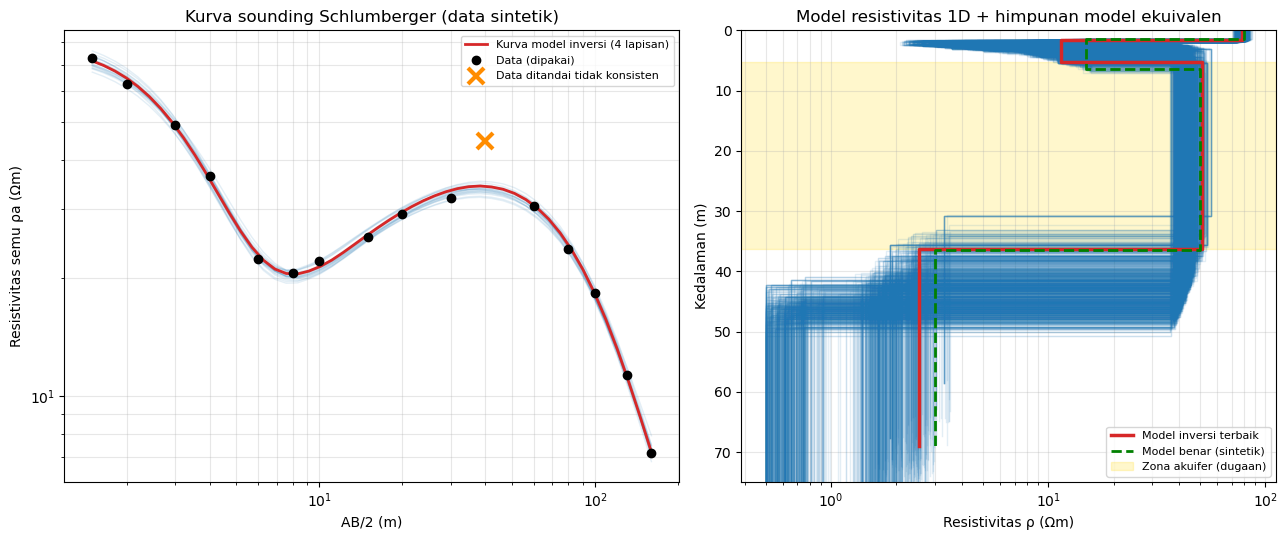

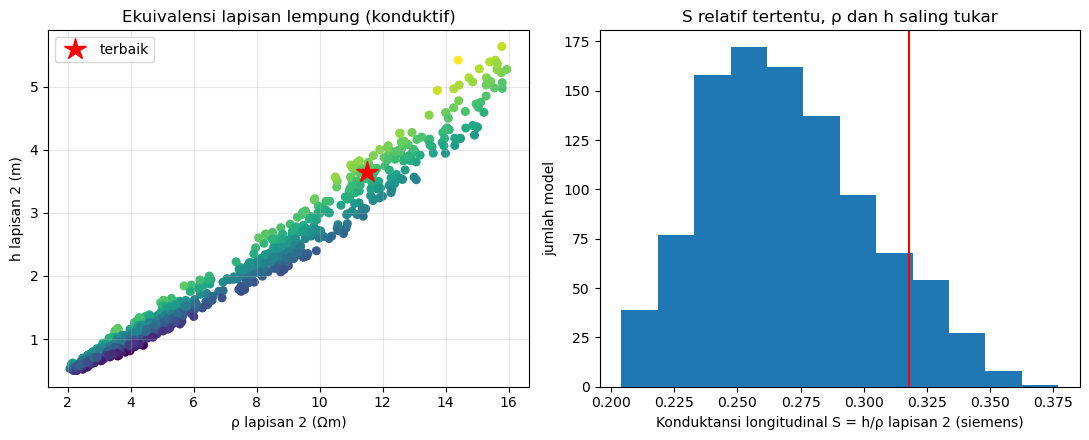

Selesai studi kasus 1.


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.15, 1]})
a = ax[0]
ab_halus = np.logspace(np.log10(1.5), np.log10(160), 50)
mn_halus = np.where(ab_halus <= 10, 0.5, np.where(ab_halus <= 40, 2.0, 5.0))
for k in range(min(len(ens), 20)):
    a.plot(ab_halus, rho_semu(ab_halus, mn_halus, 10 ** ens[k, :n_terbaik], 10 ** ens[k, n_terbaik:]),
           color="tab:blue", alpha=0.12, lw=1)
a.plot(ab_halus, rho_semu(ab_halus, mn_halus, rho_est, h_est), color="tab:red", lw=2,
       label=f"Kurva model inversi ({n_terbaik} lapisan)")
ok = ~mask_outlier
a.plot(ab2[ok], rho_obs[ok], "ko", label="Data (dipakai)")
a.plot(ab2[~ok], rho_obs[~ok], "x", color="darkorange", ms=12, mew=3, label="Data ditandai tidak konsisten")
a.set_xscale("log")
a.set_yscale("log")
a.set_xlabel("AB/2 (m)")
a.set_ylabel("Resistivitas semu ρa (Ωm)")
a.set_title("Kurva sounding Schlumberger (data sintetik)")
a.grid(True, which="both", alpha=0.3)
a.legend(fontsize=8)

b = ax[1]


def tangga(rho, h, **kw):
    z = np.r_[0, np.cumsum(h), np.cumsum(h)[-1] * 1.9]
    xs, zs = [], []
    for i in range(len(rho)):
        xs += [rho[i], rho[i]]
        zs += [z[i], z[i + 1]]
    b.plot(xs, zs, **kw)


for k in range(len(ens)):
    tangga(10 ** ens[k, :n_terbaik], 10 ** ens[k, n_terbaik:], color="tab:blue", alpha=0.12, lw=1)
tangga(rho_est, h_est, color="tab:red", lw=2.5, label="Model inversi terbaik")
tangga(rho_benar, h_benar, color="green", lw=2, ls="--", label="Model benar (sintetik)")
b.set_xscale("log")
b.set_ylim(75, 0)
b.set_xlabel("Resistivitas ρ (Ωm)")
b.set_ylabel("Kedalaman (m)")
if n_terbaik >= 3:
    b.axhspan(z_dasar[n_terbaik - 3], z_dasar[n_terbaik - 2], color="gold", alpha=0.2, label="Zona akuifer (dugaan)")
b.set_title("Model resistivitas 1D + himpunan model ekuivalen")
b.grid(True, which="both", alpha=0.3)
b.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(HASIL, "gambar_1_kurva_dan_model_VES.png"), dpi=140)
plt.show()

# gambar ekuivalensi : lapisan konduktif ke-2
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(rho_e[:, 1], h_e[:, 1], c=np.log10(h_e[:, 1] / rho_e[:, 1]), cmap="viridis", s=30)
ax[0].plot(rho_est[1], h_est[1], "r*", ms=16, label="terbaik")
ax[0].set_xlabel("ρ lapisan 2 (Ωm)")
ax[0].set_ylabel("h lapisan 2 (m)")
ax[0].set_title("Ekuivalensi lapisan lempung (konduktif)")
ax[0].grid(alpha=0.3)
ax[0].legend()
S2 = h_e[:, 1] / rho_e[:, 1]
ax[1].hist(S2, bins=12, color="tab:blue")
ax[1].axvline(h_est[1] / rho_est[1], color="r")
ax[1].set_xlabel("Konduktansi longitudinal S = h/ρ lapisan 2 (siemens)")
ax[1].set_ylabel("jumlah model")
ax[1].set_title("S relatif tertentu, ρ dan h saling tukar")
plt.tight_layout()
plt.savefig(os.path.join(HASIL, "gambar_2_ekuivalensi.png"), dpi=140)
plt.show()

with open(os.path.join(HASIL, "ringkasan_angka.txt"), "w", encoding="utf-8") as f:
    f.write(contoh + "\n\n")
    f.write(tabel_model.to_string(index=False) + "\n\n")
    f.write(rentang.to_string(index=False) + "\n\n")
    f.write(f"S lapisan 2: terbaik={h_est[1]/rho_est[1]:.3f}, rentang={S2.min():.3f}-{S2.max():.3f}\n")
    f.write(f"Penetrasi ~{pen_min:.0f}-{pen_maks:.0f} m\n")
print("Selesai studi kasus 1.")

---
## 3. Interpretasi

*Ditulis berdasarkan angka dan gambar yang dihasilkan sel-sel di atas (seed tetap, sehingga hasil dapat direproduksi).*

### 1. Pengolahan data (Input → ρa)

Faktor geometri Schlumberger dan resistivitas semu dihitung dari tabel:

`K = π (AB/2² − MN/2²) / (2·MN/2)` dan `ρa = K · ΔV / I`

Contoh perhitungan satu titik (titik ke-6): AB/2 = 8 m, MN/2 = 0,5 m → K = 200,277 m; ρa = 200,277 × 20,5525 mV / 200 mA = **20,58 Ωm**.

**Titik tidak konsisten.** Residu tiap titik terhadap interpolasi dua tetangganya (log–log) dinilai dengan skor robust (MAD). Titik **AB/2 = 40 m** mendapat skor z = 7,2 (batas 3,5), sehingga **ditandai tidak konsisten**. Titik ini tidak dihapus dari tabel (`hasil/kasus1/tabel_rho_semu.csv` memuat kolom `Bendera`), hanya dikeluarkan dari perhitungan RMS dan diberi bobot kecil oleh *loss* robust pada inversi.

### 2. Hasil inversi

![Kurva sounding dan model](hasil/kasus1/gambar_1_kurva_dan_model_VES.png)

Pemilihan jumlah lapisan (RMS tanpa outlier, kriteria BIC):

| Jumlah lapisan | RMS (%) | Parameter | BIC |
|---|---|---|---|
| 2 | 34,79 | 3 | −23,6 |
| 3 | 17,65 | 5 | −38,5 |
| **4** | **2,11** | 7 | **−96,8** |
| 5 | 2,09 | 9 | −91,7 |

Model 4 lapisan menurunkan RMS dari 17,7 % menjadi 2,1 % (lebih kecil dari noise 3 %), sedangkan lapisan ke-5 tidak memperbaiki apa pun (RMS 2,09 %) dan BIC justru memburuk. Maka **4 lapisan dipilih**.

**Tabel model lapisan (artefak keluaran ke-2)**

| Lapisan | ρ (Ωm) | Tebal (m) | Dasar (m) | Interpretasi (kemungkinan) |
|---|---|---|---|---|
| 1 | 78,3 | 1,63 | 1,63 | tanah penutup / zona tak jenuh (kering) |
| 2 | 11,5 | 3,65 | 5,29 | lempung / lanau |
| 3 | 51,2 | 31,07 | 36,36 | pasir/kerikil jenuh air tawar — **kandidat akuifer** |
| 4 | 2,5 | – | – | sedimen jenuh air asin/payau **atau** lempung sangat konduktif (ambigu) |

### 3. Interpretasi saya

**Struktur bawah permukaan.** Kurva ρa turun tajam dari ±80 Ωm ke ±20 Ωm di AB/2 ≈ 8 m, naik lagi ke maksimum ±34 Ωm di AB/2 ≈ 40 m, lalu jatuh ke ±7 Ωm pada AB/2 160 m. Bentuk "turun–naik–turun" (tipe KH) memang menuntut tiga kontras: lapisan konduktif tipis di dekat permukaan, lapisan resistif menengah, lalu zona sangat konduktif di bawah.

**Lapisan 3 (51 Ωm, ±5–36 m) sebagai akuifer.** Resistivitas 40–60 Ωm pada sedimen aluvial pesisir lazim untuk pasir/kerikil yang jenuh air tawar, dan ketebalannya (±31 m) cukup untuk sumur bor. Ini kesimpulan yang paling kokoh dari data: ρ3 hanya bergerak 36–56 Ωm di seluruh model yang cocok dengan data.

**Lapisan 4 (2,5 Ωm) dan risiko intrusi air asin.** Kontras dari 51 Ωm ke 2,5 Ωm adalah faktor ±20, terlalu besar untuk sekadar perubahan butiran. Ada dua penjelasan yang sama-sama masuk akal dan **tidak bisa dibedakan hanya dari resistivitas**:
1. **Pasir jenuh air asin/payau** (intrusi baji air laut) — didukung oleh setting pesisir dan oleh dasar akuifer yang tajam.
2. **Lempung marin yang sangat konduktif** — didukung oleh kenyataan bahwa lempung juga menghasilkan ρ < 5 Ωm.

Untuk membedakannya diperlukan data pendukung: log bor/cutting, atau konduktivitas listrik (DHL) air dari sumur terdekat.

**Ekuivalensi (hal yang paling sering terlupa).**

![Ekuivalensi lapisan lempung](hasil/kasus1/gambar_2_ekuivalensi.png)

Dari ±1000 model yang cocok dengan data sampai RMS ≤ 3,5 %, rentang parameternya cukup lebar:

| Parameter | Terbaik | Rentang model cocok |
|---|---|---|
| ρ2 (Ωm) | 11,5 | 2,1 – 15,9 |
| h2 (m) | 3,65 | 0,5 – 5,6 |
| ρ3 (Ωm) | 51,2 | 36,4 – 56,3 |
| h3 (m) | 31,1 | 27,6 – 48,2 |
| ρ4 (Ωm) | 2,5 | 0,5 – 3,5 |

Lapisan lempung tipis ke-2 adalah penyebabnya: yang tertentu hanyalah **konduktansi longitudinal S = h/ρ** (0,20–0,38 S; terbaik 0,318 S), bukan ρ2 dan h2 secara terpisah. Konsekuensi praktis: **kedalaman puncak akuifer (≈ 2–7 m) dan dasarnya tidak pasti sampai beberapa meter**, dan hal ini harus tertulis dalam laporan.

### 4. Rekomendasi (dengan tingkat keyakinan)

- **Keberadaan akuifer air tawar pada kedalaman ±5–36 m:** keyakinan **sedang–tinggi**.
- **Kedalaman pengeboran:** bor hingga ±25–30 m, **jangan menembus ke dasar model (±36 m)** karena di bawahnya terdapat zona konduktif yang mungkin air asin. Keyakinan **sedang**; dasar akuifer bisa lebih dalam (h3 hingga 48 m) tetapi tidak ada alasan mengambil risiko.
- **Sifat lapisan 4:** keyakinan **rendah** (ambigu); pantau DHL air saat pengeboran.

### 5. Verifikasi (V)

- Hitung ulang ρa pada tiga titik acak (AB/2 = 2, 3, 60 m): selisih terhadap tabel ≤ 0,0005 Ωm.
- Uji kewajaran kedalaman: AB/2 maksimum 160 m → penetrasi kira-kira 53–80 m, sedangkan dasar lapisan terdalam yang ditentukan hanya 36 m → model berada dalam kapasitas penetrasi.

**Evaluasi terhadap model benar (hanya untuk sintetik):** ρ 78,3/11,5/51,2/2,5 vs 80/15/50/3 Ωm; tebal 1,63/3,65/31,07 vs 1,5/5/30 m. Perbedaan terbesar ada pada lapisan 2, persis di lapisan yang diperkirakan terkena ekuivalensi.

### 6. Keterbatasan

Hanya satu titik VES (asumsi berlapis datar 1D), tanpa kalibrasi sumur; ambang litologi dari resistivitas bersifat umum, bukan pasti; data sintetik tidak mengandung efek lateral, anisotropi, atau kontak elektroda yang buruk.

---

# **Studi Kasus 2 - Seismik Refraksi: Kedalaman Batuan Dasar untuk Fondasi**

## 1. Prompt (struktur R-T-C-I-K-O-Q-V)

## Prompt 2 - Seismik Refraksi: Kedalaman Batuan Dasar untuk Fondasi Bangunan

**Role:**
Kamu adalah seorang geofisikawan rekayasa (engineering geophysicist) yang berpengalaman dalam interpretasi seismik refraksi dangkal untuk investigasi geoteknik.

**Task:**
Analisis data waktu tempuh gelombang P (first arrival) dari survei seismik refraksi untuk menentukan kecepatan lapisan lapuk dan batuan dasar, kedalaman batuan dasar (bedrock), serta menilai kelayakan lokasi untuk fondasi gedung bertingkat.

**Context:**
Lokasi adalah calon pembangunan gedung pada lereng landai dengan tanah residual di atas batuan beku lapuk. Fondasi dangkal hanya layak jika batuan dasar dengan Vp tinggi berada dalam kedalaman tertentu. Survei menggunakan satu lintasan dengan tembakan maju (forward) dan tembakan balik (reverse).

**Input:**
Tabel: posisi geophone (m), waktu tiba tembakan maju (ms), waktu tiba tembakan balik (ms), dan posisi sumber. Jika belum ada, minta pengguna melampirkannya.

**Constraints:**
- Gunakan metode *intercept time* dan tuliskan rumus kedalaman yang dipakai.
- Asumsikan model dua lapis hanya jika data mendukung; bila ada lebih dari satu kemiringan pada kurva jarak-waktu, sebutkan kemungkinan tiga lapis.
- Jangan mengasumsikan bidang batas datar bila tembakan maju dan balik menunjukkan Vp semu berbeda; gunakan koreksi kemiringan.
- Jangan menetapkan kapasitas dukung tanah; hanya berikan indikasi kelayakan awal.
- Failure behavior: jika waktu tiba tidak monoton meningkat terhadap offset, laporkan anomali dan minta verifikasi *picking* sebelum lanjut.

**Output:**
Rencana output berupa narasi dan tabel teks (tanpa grafik):
1. *Narasi interpretasi*: alur analisis dari penentuan crossover distance sampai kedalaman bedrock di bawah sumber maju dan sumber balik, plus penjelasan kemiringan bidang batas.
2. *Tabel hasil*: V1, V2, waktu intersep, kedalaman ke bedrock (m) di setiap ujung lintasan, dan catatan kelayakan fondasi.

**Quality criteria:**
- Satuan konsisten (m, ms, m/s).
- Perbedaan kedalaman maju vs balik dijelaskan secara fisis, bukan diabaikan.
- Kelayakan fondasi dinyatakan sebagai indikasi awal dengan rekomendasi uji lanjutan (mis. bor inti atau sondir).
- Tidak ada angka kecepatan atau kedalaman tanpa turunan perhitungan.

**Optional verification (V):**
Bila diperlukan, cek *reciprocal time*: waktu tempuh dari sumber maju ke ujung balik harus mendekati waktu dari sumber balik ke ujung maju. Laporkan selisihnya dan nyatakan apakah masih dalam toleransi wajar.

## 2. Kode dan hasil

Kode dipecah per tahap. Jalankan sel dari atas ke bawah.

### Persiapan: impor pustaka dan folder keluaran

In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = os.getcwd()          # folder tempat notebook ini disimpan
DATA = os.path.join(BASE, "data", "kasus2")
HASIL = os.path.join(BASE, "hasil", "kasus2")
os.makedirs(DATA, exist_ok=True)
os.makedirs(HASIL, exist_ok=True)
rng = np.random.default_rng(11)

### 1. MODEL BENAR (hanya untuk membangkitkan data sintetik)

In [11]:
V1_b, V2_b = 450.0, 2400.0        # m/s
dip_b = np.deg2rad(5.0)           # kemiringan bidang batas (makin dalam ke arah B)
hA_b = 6.0                        # jarak TEGAK LURUS bidang batas dari shot A (m)
L = 115.0                         # panjang lintasan (m)
hB_b = hA_b + L * np.sin(dip_b)   # jarak tegak lurus di shot B
theta_c_b = np.arcsin(V1_b / V2_b)

x = np.arange(0, L + 0.1, 5.0)    # 24 geophone, jarak 5 m
# waktu bias (refraksi) arah maju (shot A, x=0, menembak ke bawah-miring) dan balik (shot B, x=L)
t_ref_f = x * np.sin(theta_c_b + dip_b) / V1_b + 2 * hA_b * np.cos(theta_c_b) / V1_b
t_ref_r = (L - x) * np.sin(theta_c_b - dip_b) / V1_b + 2 * hB_b * np.cos(theta_c_b) / V1_b
t_dir_f = x / V1_b
t_dir_r = (L - x) / V1_b
t_f = np.minimum(t_dir_f, t_ref_f) * 1000          # ms (first arrival)
t_r = np.minimum(t_dir_r, t_ref_r) * 1000
t_f = t_f + rng.normal(0, 0.5, len(x))             # noise picking 0.5 ms
t_r = t_r + rng.normal(0, 0.5, len(x))
t_f[x == 0] = np.nan                               # geophone di titik tembak tidak dipakai
t_r[x == L] = np.nan

tab = pd.DataFrame({"x (m)": x, "t_maju_shotA (ms)": t_f.round(2), "t_balik_shotB (ms)": t_r.round(2)})
tab.to_csv(os.path.join(DATA, "data_first_arrival_sintetik.csv"), index=False)

### 2. PEMERIKSAAN KUALITAS DATA (Constraint: failure behavior)

In [12]:
def cek_monotonik(xx, tt):
    m = ~np.isnan(tt)
    xs, ts = xx[m], tt[m]
    o = np.argsort(xs)
    return np.all(np.diff(ts[o]) > -1.0)     # toleransi 1 ms (>= 2x noise picking)

ok_f = cek_monotonik(x, t_f)                 # maju: t harus naik terhadap jarak dari shot A
ok_r = cek_monotonik(L - x, t_r)             # balik: t harus naik terhadap jarak dari shot B
print(f"Cek monotonik: maju = {ok_f} ; balik = {ok_r}")
if not (ok_f and ok_r):
    raise SystemExit("Waktu tiba tidak monoton -> hentikan analisis, periksa picking.")

Cek monotonik: maju = True ; balik = True


### 3. PEMISAHAN SEGMEN (gelombang langsung vs refraksi) dengan regresi dua segmen

In [13]:
def dua_segmen(d, t):
    """d = jarak dari sumber, t = waktu (ms). Cari titik patah terbaik (SSE minimum)."""
    m = ~np.isnan(t) & (d > 0)
    d, t = d[m], t[m]
    o = np.argsort(d)
    d, t = d[o], t[o]
    terbaik = None
    for k in range(2, len(d) - 3):                  # minimal 2 titik langsung & 3 titik refraksi
        p1 = np.polyfit(d[:k], t[:k], 1)
        p2 = np.polyfit(d[k:], t[k:], 1)
        sse = np.sum((np.polyval(p1, d[:k]) - t[:k])**2) + np.sum((np.polyval(p2, d[k:]) - t[k:])**2)
        if terbaik is None or sse < terbaik[0]:
            terbaik = (sse, k, p1, p2)
    sse, k, p1, p2 = terbaik
    return dict(sse=sse, k=k, p1=p1, p2=p2, d=d, t=t, rms=np.sqrt(sse / len(d)))

d_f = x                     # jarak dari shot A
d_r = L - x                 # jarak dari shot B
Sf = dua_segmen(d_f, t_f)
Sr = dua_segmen(d_r, t_r)

# V1 dari lereng gelombang langsung, V2 semu dari lereng refraksi
V1_maju = 1000.0 / Sf["p1"][0]
V1_balik = 1000.0 / Sr["p1"][0]
V1 = 0.5 * (V1_maju + V1_balik)
Vd = 1000.0 / Sf["p2"][0]      # kecepatan semu down-dip (arah maju)
Vu = 1000.0 / Sr["p2"][0]      # kecepatan semu up-dip  (arah balik)
ti_f = Sf["p2"][1]             # waktu intersep (ms)
ti_r = Sr["p2"][1]
xc_f = Sf["d"][Sf["k"] - 1:Sf["k"] + 1].mean()
xc_r = Sr["d"][Sr["k"] - 1:Sr["k"] + 1].mean()

print(f"V1 maju={V1_maju:.0f}  V1 balik={V1_balik:.0f}  -> V1 rata-rata = {V1:.0f} m/s")
print(f"Vd (semu, arah maju) = {Vd:.0f} m/s ; Vu (semu, arah balik) = {Vu:.0f} m/s")
print(f"Intersep maju = {ti_f:.2f} ms ; balik = {ti_r:.2f} ms ; crossover maju ~{xc_f:.1f} m, balik ~{xc_r:.1f} m")

V1 maju=470  V1 balik=441  -> V1 rata-rata = 456 m/s
Vd (semu, arah maju) = 1658 m/s ; Vu (semu, arah balik) = 4638 m/s
Intersep maju = 26.31 ms ; balik = 70.52 ms ; crossover maju ~17.5 m, balik ~32.5 m


### 4. INTERPRETASI INTERCEPT TIME DENGAN KOREKSI KEMIRINGAN sin(theta_c + dip) = V1/Vd ; sin(theta_c - dip) = V1/Vu

In [14]:
a1 = np.arcsin(np.clip(V1 / Vd, -1, 1))
a2 = np.arcsin(np.clip(V1 / Vu, -1, 1))
theta_c = 0.5 * (a1 + a2)
dip = 0.5 * (a1 - a2)
V2 = V1 / np.sin(theta_c)
h_f = (ti_f / 1000.0) * V1 / (2 * np.cos(theta_c))      # tegak lurus bidang, di bawah shot A
h_r = (ti_r / 1000.0) * V1 / (2 * np.cos(theta_c))      # tegak lurus bidang, di bawah shot B
z_f = h_f / np.cos(dip)                                 # kedalaman vertikal
z_r = h_r / np.cos(dip)
print(f"theta_c = {np.rad2deg(theta_c):.2f} deg ; dip = {np.rad2deg(dip):.2f} deg ; V2 = {V2:.0f} m/s")
print(f"Kedalaman vertikal bedrock: bawah shot A = {z_f:.2f} m ; bawah shot B = {z_r:.2f} m")

# Pembanding SALAH (abaikan kemiringan): V2 = rata-rata Vd dan Vu seolah bidang datar
V2_datar_naif = 0.5 * (Vd + Vu)
h_naif_f = (ti_f / 1000) * V1 * V2_datar_naif / (2 * np.sqrt(V2_datar_naif**2 - V1**2))
h_naif_r = (ti_r / 1000) * V1 * V2_datar_naif / (2 * np.sqrt(V2_datar_naif**2 - V1**2))

theta_c = 10.80 deg ; dip = 5.16 deg ; V2 = 2432 m/s
Kedalaman vertikal bedrock: bawah shot A = 6.13 m ; bawah shot B = 16.42 m


### 5. UJI MODEL 2 LAPIS vs 3 LAPIS (BIC pada cabang refraksi)

In [15]:
def bic_cabang(d, t, k_awal):
    dd, tt = d[k_awal:], t[k_awal:]
    n = len(dd)
    p1 = np.polyfit(dd, tt, 1)
    s1 = np.sum((np.polyval(p1, dd) - tt)**2)
    bic1 = n * np.log(s1 / n + 1e-9) + 2 * np.log(n)
    terbaik = None
    for k in range(3, n - 3):
        pa, pb = np.polyfit(dd[:k], tt[:k], 1), np.polyfit(dd[k:], tt[k:], 1)
        s2 = np.sum((np.polyval(pa, dd[:k]) - tt[:k])**2) + np.sum((np.polyval(pb, dd[k:]) - tt[k:])**2)
        if terbaik is None or s2 < terbaik:
            terbaik = s2
    bic2 = n * np.log(terbaik / n + 1e-9) + 4 * np.log(n)
    return bic1, bic2

bf = bic_cabang(Sf["d"], Sf["t"], Sf["k"])
br = bic_cabang(Sr["d"], Sr["t"], Sr["k"])
print(f"BIC cabang refraksi (1 garis vs 2 garis): maju {bf[0]:.1f} vs {bf[1]:.1f} ; balik {br[0]:.1f} vs {br[1]:.1f}")
tiga_lapis = (bf[1] < bf[0] - 6) or (br[1] < br[0] - 6)
print("Indikasi lapisan ketiga:", "YA" if tiga_lapis else "TIDAK (model 2 lapis cukup)")

BIC cabang refraksi (1 garis vs 2 garis): maju -31.1 vs -29.9 ; balik -30.7 vs -32.1
Indikasi lapisan ketiga: TIDAK (model 2 lapis cukup)


### 6. VERIFIKASI : RECIPROCAL TIME t(A -> geophone di B) harus sama dengan t(B -> geophone di A) nilai maju di x=L ; nilai balik di x=0

In [16]:
tAB = t_f[x == L][0]
tBA = t_r[x == 0][0]
selisih_rec = abs(tAB - tBA)
print(f"Reciprocal: t(A->B) = {tAB:.2f} ms ; t(B->A) = {tBA:.2f} ms ; selisih = {selisih_rec:.2f} ms")

Reciprocal: t(A->B) = 95.47 ms ; t(B->A) = 94.85 ms ; selisih = 0.62 ms


### 7. Tabel Hasil & Kelayakan

In [17]:
tabel_hasil = pd.DataFrame({
    "Parameter": ["V1 (m/s)", "V2 (m/s)", "Kemiringan bidang batas (deg)", "theta kritis (deg)",
                  "Intersep maju (ms)", "Intersep balik (ms)",
                  "Kedalaman bedrock di bawah shot A (m)", "Kedalaman bedrock di bawah shot B (m)"],
    "Nilai": [round(V1), round(V2), round(np.rad2deg(dip), 2), round(np.rad2deg(theta_c), 2),
              round(ti_f, 2), round(ti_r, 2), round(z_f, 2), round(z_r, 2)],
    "Nilai benar (sintetik)": [V1_b, V2_b, 5.0, round(np.rad2deg(theta_c_b), 2), "-", "-",
                               round(hA_b / np.cos(dip_b), 2), round(hB_b / np.cos(dip_b), 2)],
})
tabel_hasil.to_csv(os.path.join(HASIL, "tabel_hasil_refraksi.csv"), index=False)
print(tabel_hasil.to_string(index=False))

# Kedalaman sepanjang lintasan (kedalaman vertikal bidang batas di tiap geophone)
z_x = z_f + x * np.tan(dip)
tabel_profil = pd.DataFrame({"x (m)": x, "Kedalaman bedrock (m)": z_x.round(2),
                             "Estimasi untuk fondasi dangkal": np.where(z_x <= 8, "relatif dangkal (<=8 m)",
                                                              np.where(z_x <= 12, "menengah (8-12 m)", "dalam (>12 m)"))})
tabel_profil.to_csv(os.path.join(HASIL, "profil_kedalaman_bedrock.csv"), index=False)

perbandingan = pd.DataFrame({
    "Metode": ["Dengan koreksi kemiringan (dipakai)", "Bidang datar naif (SALAH)", "Model benar (sintetik)"],
    "V2 (m/s)": [round(V2), round(V2_datar_naif), V2_b],
    "z di bawah A (m)": [round(z_f, 2), round(h_naif_f, 2), round(hA_b / np.cos(dip_b), 2)],
    "z di bawah B (m)": [round(z_r, 2), round(h_naif_r, 2), round(hB_b / np.cos(dip_b), 2)],
})
perbandingan.to_csv(os.path.join(HASIL, "perbandingan_metode.csv"), index=False)
print(perbandingan.to_string(index=False))

                            Parameter   Nilai Nilai benar (sintetik)
                             V1 (m/s)  456.00                  450.0
                             V2 (m/s) 2432.00                 2400.0
        Kemiringan bidang batas (deg)    5.16                    5.0
                   theta kritis (deg)   10.80                  10.81
                   Intersep maju (ms)   26.31                      -
                  Intersep balik (ms)   70.52                      -
Kedalaman bedrock di bawah shot A (m)    6.13                   6.02
Kedalaman bedrock di bawah shot B (m)   16.42                  16.08
                             Metode  V2 (m/s)  z di bawah A (m)  z di bawah B (m)
Dengan koreksi kemiringan (dipakai)    2432.0              6.13             16.42
          Bidang datar naif (SALAH)    3148.0              6.06             16.23
             Model benar (sintetik)    2400.0              6.02             16.08


### 8. Gambar

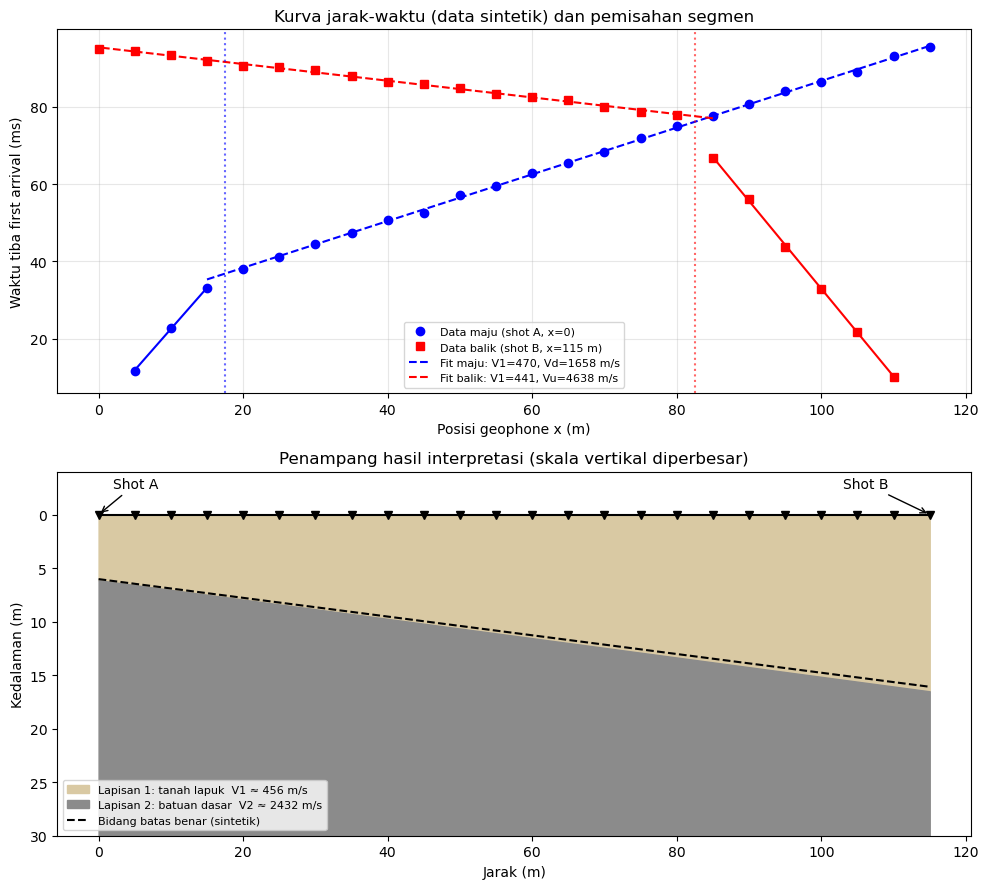

Selesai studi kasus 2.


In [18]:
fig, ax = plt.subplots(2, 1, figsize=(10, 9))
a = ax[0]
a.plot(x, t_f, "bo", label="Data maju (shot A, x=0)")
a.plot(x, t_r, "rs", label="Data balik (shot B, x=115 m)")
xx = np.linspace(0, L, 200)
# garis fit
kf, kr = Sf["k"], Sr["k"]
a.plot(Sf["d"][:kf], np.polyval(Sf["p1"], Sf["d"][:kf]), "b-", lw=1.5)
a.plot(Sf["d"][kf - 1:], np.polyval(Sf["p2"], Sf["d"][kf - 1:]), "b--", lw=1.5, label=f"Fit maju: V1={V1_maju:.0f}, Vd={Vd:.0f} m/s")
a.plot(L - Sr["d"][:kr], np.polyval(Sr["p1"], Sr["d"][:kr]), "r-", lw=1.5)
a.plot(L - Sr["d"][kr - 1:], np.polyval(Sr["p2"], Sr["d"][kr - 1:]), "r--", lw=1.5, label=f"Fit balik: V1={V1_balik:.0f}, Vu={Vu:.0f} m/s")
a.axvline(xc_f, color="b", ls=":", alpha=0.6)
a.axvline(L - xc_r, color="r", ls=":", alpha=0.6)
a.set_xlabel("Posisi geophone x (m)")
a.set_ylabel("Waktu tiba first arrival (ms)")
a.set_title("Kurva jarak-waktu (data sintetik) dan pemisahan segmen")
a.grid(alpha=0.3)
a.legend(fontsize=8)

b = ax[1]
b.fill_between(x, 0, z_x, color="#d9c9a3", label=f"Lapisan 1: tanah lapuk  V1 ≈ {V1:.0f} m/s")
b.fill_between(x, z_x, 30, color="#8b8b8b", label=f"Lapisan 2: batuan dasar  V2 ≈ {V2:.0f} m/s")
b.plot(x, hA_b / np.cos(dip_b) + x * np.tan(dip_b), "k--", lw=1.5, label="Bidang batas benar (sintetik)")
b.plot([0, L], [0, 0], "k-")
b.plot(x, np.zeros_like(x), "kv", ms=6)
b.annotate("Shot A", (0, 0), xytext=(2, -2.5), arrowprops=dict(arrowstyle="->"))
b.annotate("Shot B", (L, 0), xytext=(L - 12, -2.5), arrowprops=dict(arrowstyle="->"))
b.set_ylim(30, -4)
b.set_xlabel("Jarak (m)")
b.set_ylabel("Kedalaman (m)")
b.set_title("Penampang hasil interpretasi (skala vertikal diperbesar)")
b.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig(os.path.join(HASIL, "gambar_1_jarak_waktu_dan_penampang.png"), dpi=140)
plt.show()

with open(os.path.join(HASIL, "ringkasan_angka.txt"), "w", encoding="utf-8") as f:
    f.write(tabel_hasil.to_string(index=False) + "\n\n")
    f.write(perbandingan.to_string(index=False) + "\n\n")
    f.write(f"Reciprocal: A->B {tAB:.2f} ms ; B->A {tBA:.2f} ms ; selisih {selisih_rec:.2f} ms\n")
    f.write(f"BIC maju (1 vs 2 garis): {bf[0]:.1f} vs {bf[1]:.1f}; balik: {br[0]:.1f} vs {br[1]:.1f}\n")
    f.write(f"RMS fit dua segmen: maju {Sf['rms']:.2f} ms ; balik {Sr['rms']:.2f} ms\n")
print("Selesai studi kasus 2.")

---
## 3. Interpretasi

*Ditulis berdasarkan angka dan gambar yang dihasilkan sel-sel di atas (seed tetap, sehingga hasil dapat direproduksi).*

### 1. Pemeriksaan data (aturan *failure behavior*)

Waktu tiba harus meningkat terhadap jarak dari sumber. Pemeriksaan monotonik (toleransi 1 ms) **lolos** untuk arah maju maupun balik, sehingga analisis dilanjutkan.

### 2. Hasil analisis

![Kurva jarak-waktu dan penampang](hasil/kasus2/gambar_1_jarak_waktu_dan_penampang.png)

Regresi dua segmen dengan titik patah yang dicari otomatis (SSE minimum) memisahkan gelombang langsung dan gelombang refraksi:

| Besaran | Maju (shot A) | Balik (shot B) |
|---|---|---|
| V1 dari gelombang langsung | 470 m/s | 441 m/s |
| Kecepatan semu refraksi | Vd = 1658 m/s (*down-dip*) | Vu = 4638 m/s (*up-dip*) |
| Waktu intersep | 26,31 ms | 70,52 ms |
| *Crossover distance* | ±17,5 m | ±32,5 m |
| RMS fit dua segmen | 0,38 ms | 0,33 ms |

Perbedaan besar antara Vd dan Vu **bukan** perbedaan material, melainkan akibat kemiringan bidang batas. Dengan koreksi kemiringan (`sin(θc+δ) = V1/Vd`, `sin(θc−δ) = V1/Vu`):

| Parameter | Hasil | Benar (sintetik) |
|---|---|---|
| V1 | 456 m/s | 450 |
| **V2** | **2432 m/s** | 2400 |
| Sudut kritis θc | 10,80° | 10,81° |
| **Kemiringan bidang batas** | **5,16°** | 5,0° |
| **Kedalaman bedrock di bawah shot A** | **6,13 m** | 6,02 |
| **Kedalaman bedrock di bawah shot B** | **16,42 m** | 16,08 |

### 3. Interpretasi saya

**Mengapa kedalaman maju dan balik berbeda?** Selisihnya 16,42 − 6,13 = **10,3 m**, hampir sama dengan L·tan(δ) = 115 × tan(5,16°) = 10,4 m. Jadi perbedaan itu fisis: bidang batas turun ke arah timur (shot B), bukan kesalahan pengukuran. Menganggap bidang datar akan menyesatkan.

**Pentingnya koreksi kemiringan.** Bila Vd dan Vu dirata-ratakan seolah bidang datar, V2 menjadi 3148 m/s (**±31 % terlalu tinggi**), padahal V2 sebenarnya ±2400 m/s. Kedalaman kebetulan masih mendekati (6,06 dan 16,23 m), tetapi V2 yang salah akan mengubah klasifikasi material (lapuk-keras vs batuan segar) dan penilaian *rippability*.

**Apakah ada lapisan ketiga?** Uji BIC pada cabang refraksi (1 garis vs 2 garis): maju −31,1 vs −29,9, balik −30,7 vs −32,1. Perbaikan terbaik hanya 1,4 poin BIC, jauh di bawah ambang 6 yang saya pakai. **Model dua lapis cukup**; tidak ada bukti lapisan tersembunyi.

**Tafsir material.** V1 ≈ 450 m/s menunjukkan tanah residual/pelapukan yang gembur. V2 ≈ 2400 m/s lebih rendah daripada batuan beku segar (umumnya > 4000 m/s), jadi lapisan bawah paling masuk akal ditafsirkan sebagai **batuan lapuk keras / batuan lapuk menengah**, bukan batuan segar. Istilah "batuan dasar" di sini bersifat geoteknik: lapisan dengan kecepatan jauh lebih tinggi.

**Profil kedalaman sepanjang lintasan** (`hasil/kasus2/profil_kedalaman_bedrock.csv`):

| Jarak x (m) | Kedalaman (m) | Kategori |
|---|---|---|
| 0 | 6,1 | dangkal |
| 20 | 7,9 | dangkal (≤ 8 m) |
| 40 | 9,7 | menengah (8–12 m) |
| 60 | 11,5 | menengah |
| 80 | 13,4 | dalam (> 12 m) |
| 100 | 15,2 | dalam |

### 4. Indikasi kelayakan fondasi (indikasi awal, bukan daya dukung)

- **Sisi barat (x ≲ 20 m):** bedrock lapuk di kedalaman ±6–8 m, **relatif menguntungkan** untuk fondasi dangkal/telapak yang bertumpu pada lapisan keras.
- **Bagian tengah (x ≈ 20–65 m):** kedalaman 8–12 m; fondasi dangkal kurang efisien, tiang pendek mungkin dipertimbangkan.
- **Sisi timur (x ≳ 65 m):** bedrock > 12 m dan terus mendalam hingga ±16 m; kemungkinan perlu **fondasi tiang** atau perbaikan tanah.

Ini adalah **indikasi awal**. Kapasitas dukung tidak bisa disimpulkan dari kecepatan gelombang P. Lanjutkan dengan **bor inti dan SPT/sondir** di minimal tiga titik (x ≈ 10, 55, 105 m), terutama untuk memastikan batas lapuk-segar.

### 5. Verifikasi (V): *reciprocal time*

Waktu A→B = 95,47 ms dan B→A = 94,85 ms, selisih **0,62 ms**. Nilai ini sebanding dengan noise *picking* (σ = 0,5 ms per bacaan, jadi ±0,7 ms untuk selisih dua bacaan), sehingga data konsisten dan *picking* dapat dipercaya.

### 6. Keterbatasan

Hanya dua tembakan ujung sehingga tidak ada pengamatan kecepatan lateral; gelombang langsung hanya tertangkap pada ±3–7 geophone sehingga V1 punya ketidakpastian (441–470 m/s); bidang batas diasumsikan planar; lapisan tersembunyi (*hidden layer*) dan zona kecepatan terbalik tidak bisa dideteksi oleh refraksi.

---

# **Studi Kasus 3 - Gayaberat: Anomali Bouguer untuk Patahan dan Cekungan**

## 1. Prompt (struktur R-T-C-I-K-O-Q-V)

## Prompt 3 - Gravitasi: Anomali Bouguer untuk Mendeteksi Struktur Patahan dan Cekungan

**Role:**
Kamu adalah seorang geofisikawan regional yang ahli dalam pengolahan dan interpretasi data gayaberat (gravity) untuk pemetaan struktur bawah permukaan.

**Task:**
Susun rencana dan narasi interpretasi pengolahan data gayaberat dari pembacaan gravimeter menjadi anomali Bouguer lengkap, lalu pisahkan anomali regional dan residual untuk mengidentifikasi indikasi patahan dan cekungan sedimen.

**Context:**
Area studi berupa graben di zona tektonik aktif dengan dugaan cekungan sedimen tebal yang dibatasi sesar normal. Kontras densitas antara sedimen (rendah) dan batuan dasar (tinggi) diharapkan menghasilkan anomali Bouguer rendah di atas cekungan dan gradien horizontal tinggi di sepanjang sesar.

**Input:**
Tabel titik pengukuran: ID stasiun, koordinat (lintang, bujur), elevasi (m), pembacaan gravimeter (mGal), waktu pengukuran, serta data base station untuk koreksi drift. Jika belum tersedia, minta pengguna melampirkannya.

**Constraints:**
- Urutkan koreksi secara eksplisit: drift dan pasang surut, lintang, udara bebas, Bouguer, dan (bila ada data DEM) koreksi medan.
- Tuliskan densitas reduksi yang dipakai dan alasannya; jangan memakai 2,67 g/cm³ tanpa justifikasi.
- Pemisahan regional–residual harus menyebut metodenya (mis. polinomial orde-n, upward continuation) beserta parameternya.
- Jangan menarik kesimpulan kedalaman cekungan tanpa asumsi kontras densitas yang dinyatakan; solusi gravitasi bersifat tidak unik.
- Failure behavior: jika sebaran stasiun tidak cukup untuk membuat kontur (kurang dari sekitar 30 titik atau sangat tidak merata), nyatakan keterbatasan dan hanya berikan interpretasi kualitatif.

**Output:**
Rencana output berupa narasi dan tabel teks (tanpa peta atau gambar):
1. *Narasi alur pengolahan* dari data mentah hingga anomali residual, termasuk hasil perkiraan yang diharapkan pada tiap tahap.
2. *Narasi interpretasi*: lokasi kemungkinan sesar (berdasarkan gradien horizontal), sebaran anomali rendah sebagai indikasi cekungan, dan estimasi kedalaman kasar dengan rentang ketidakpastian.
Ditambah tabel teks ringkas: tahap koreksi, rumus, parameter, dan dampak terhadap nilai anomali.

**Quality criteria:**
- Urutan dan rumus koreksi benar serta konsisten satuannya (mGal, m, g/cm³).
- Ketidakpastian dan non-unik dinyatakan secara jelas.
- Interpretasi patahan didukung minimal dua indikator (gradien horizontal dan pola kontur anomali).
- Hasil dapat direproduksi oleh pembaca dari parameter yang tertulis.

**Optional verification (V):**
Bila diperlukan, uji sensitivitas: jelaskan bagaimana perubahan densitas reduksi (mis. 2,4 vs 2,67 g/cm³) akan mengubah anomali Bouguer dan apakah kesimpulan struktur berubah.

## 2. Kode dan hasil

Kode dipecah per tahap. Jalankan sel dari atas ke bawah.

### Persiapan: impor pustaka dan folder keluaran

In [19]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.interpolate import RBFInterpolator
from scipy.optimize import least_squares
from scipy.signal import find_peaks

BASE = os.getcwd()          # folder tempat notebook ini disimpan
DATA = os.path.join(BASE, "data", "kasus3")
HASIL = os.path.join(BASE, "hasil", "kasus3")
os.makedirs(DATA, exist_ok=True)
os.makedirs(HASIL, exist_ok=True)
rng = np.random.default_rng(2024)
G = 6.674e-11

### A. Model Benar + Pembangkit Data Sintetik

In [20]:
RHO_TOPO_BENAR = 2.40            # g/cm3 : densitas batuan permukaan sebenarnya (disembunyikan dari pengolahan)
DRHO_BENAR = -400.0              # kg/m3 : kontras densitas sedimen-batuan dasar (-0.40 g/cm3)
UKURAN = 20000.0                 # m, daerah 20 x 20 km
LAT0, LON0 = -3.20, 119.80       # titik asal lokal (area hipotetis)


def profil_cekungan_km(xk):
    """Kedalaman cekungan (km) sepanjang x (km): sesar normal barat di x~8, sesar timur di x~13.75."""
    return np.interp(xk, [0, 7.5, 8.5, 11.0, 13.0, 13.5, 14.0, 20.0], [0, 0, 1.6, 2.5, 1.5, 1.2, 0, 0])


def taper_y(yk):
    return 1.0 - 0.45 * ((yk - 10.0) / 10.0) ** 2


def prisma_gz(xo, yo, x1, x2, y1, y2, z1, z2, rho):
    """gz (mGal) prisma persegi (Nagy). Koordinat m, z positif ke bawah, rho kg/m3.
    xo, yo : titik amat (n,1) ; x1..z2 : sisi prisma (1,m)."""
    tot = 0.0
    for i, xc in enumerate((x1, x2)):
        for j, yc in enumerate((y1, y2)):
            for k, zc in enumerate((z1, z2)):
                X = xc - xo
                Y = yc - yo
                Z = zc
                R = np.sqrt(X**2 + Y**2 + Z**2)
                mu = (-1) ** (i + j + k + 1)
                tot = tot + mu * (Z * np.arctan2(X * Y, Z * R) - X * np.log(Y + R) - Y * np.log(X + R))
    return G * rho * tot * 1e5


# kolom prisma cekungan 0.5 km
sel = 500.0
ce = np.arange(0, UKURAN + 1, sel)
cx = 0.5 * (ce[:-1] + ce[1:])
CX, CY = np.meshgrid(cx, cx)
dep = profil_cekungan_km(CX / 1000.0) * taper_y(CY / 1000.0) * 1000.0      # m
msk = dep > 1.0
px1, px2 = (CX - sel / 2)[msk][None, :], (CX + sel / 2)[msk][None, :]
py1, py2 = (CY - sel / 2)[msk][None, :], (CY + sel / 2)[msk][None, :]
pz1, pz2 = np.zeros_like(px1), dep[msk][None, :]


def gz_cekungan(xm, ym):
    xm = np.asarray(xm, float).reshape(-1, 1) + 1e-3
    ym = np.asarray(ym, float).reshape(-1, 1) + 1e-3
    return prisma_gz(xm, ym, px1, px2, py1, py2, pz1, pz2, DRHO_BENAR).sum(axis=1)


# stasiun : grid 12 x 12 dengan jitter -> 144 titik
n1 = 12
gx, gy = np.meshgrid((np.arange(n1) + 0.5) * UKURAN / n1, (np.arange(n1) + 0.5) * UKURAN / n1)
xs = np.clip(gx.ravel() + rng.uniform(-0.35, 0.35, gx.size) * UKURAN / n1, 100, UKURAN - 100)
ys = np.clip(gy.ravel() + rng.uniform(-0.35, 0.35, gy.size) * UKURAN / n1, 100, UKURAN - 100)
# urutan kunjungan : serpentine per baris (mensimulasikan jalur lapangan)
ordr = np.lexsort((np.where((np.floor(ys / (UKURAN / n1)) % 2) == 0, xs, -xs), np.floor(ys / (UKURAN / n1))))
xs, ys = xs[ordr], ys[ordr]
Ns = xs.size
# topografi (m) : relief sedang, tidak dikaitkan dengan cekungan
topo = (120 + 70 * np.sin(2 * np.pi * xs / 14000 + 1.0) * np.cos(2 * np.pi * ys / 17000 + 0.5)
        + 45 * np.sin(2 * np.pi * (xs + 1.7 * ys) / 6500) + rng.normal(0, 8, Ns))
topo = np.clip(topo, 5, 330)
lat = LAT0 + ys / 111190.0
lon = LON0 + xs / (111190.0 * np.cos(np.deg2rad(LAT0)))


def gamma_lintang(phi_deg):
    s2 = np.sin(np.deg2rad(phi_deg)) ** 2
    return 978031.846 * (1 + 0.005278895 * s2 + 0.000023462 * s2**2)     # mGal (GRS67)


def regional_benar(xm, ym):
    return -12.0 - 0.35 * xm / 1000.0 + 0.20 * ym / 1000.0                 # mGal (tren planar)


basin_true = gz_cekungan(xs, ys)
cba_true = regional_benar(xs, ys) + basin_true
g_true = gamma_lintang(lat) - 0.3086 * topo + 0.04193 * RHO_TOPO_BENAR * topo + cba_true + rng.normal(0, 0.05, Ns)

# stasiun basis
xb, yb, hb = 1000.0, 1000.0, 20.0
lat_b = LAT0 + yb / 111190.0
g_base_abs = (gamma_lintang(lat_b) - 0.3086 * hb + 0.04193 * RHO_TOPO_BENAR * hb
              + regional_benar(xb, yb) + gz_cekungan([xb], [yb])[0])

# waktu pengukuran, drift, pasang surut
t_stn = 0.15 + np.arange(Ns) * (7.7 / Ns)                  # jam sejak mulai
t_base = np.array([0.0, 2.7, 5.4, 8.0])


def drift_benar(t):
    return 0.05 * t + 0.0020 * t**2


def tide_model(t):
    return 0.080 * np.sin(2 * np.pi * t / 12.42 + 0.7) + 0.050 * np.sin(2 * np.pi * t / 12.00 + 2.1)


R0 = 3000.0
R_stn = R0 + (g_true - g_base_abs) + drift_benar(t_stn) + tide_model(t_stn) + rng.normal(0, 0.03, Ns)
R_base = R0 + drift_benar(t_base) + tide_model(t_base) + rng.normal(0, 0.02, len(t_base))

raw = pd.DataFrame({"stasiun": [f"S{i+1:03d}" for i in range(Ns)], "lintang": lat.round(6), "bujur": lon.round(6),
                    "elevasi_m": topo.round(1), "waktu_jam": t_stn.round(3), "bacaan_mGal": R_stn.round(3)})
raw.to_csv(os.path.join(DATA, "data_gravimeter_mentah_sintetik.csv"), index=False)
pd.DataFrame({"waktu_jam": t_base, "bacaan_basis_mGal": R_base.round(3), "elevasi_basis_m": hb,
              "g_absolut_basis_mGal": round(g_base_abs, 3)}).to_csv(
    os.path.join(DATA, "data_basis_sintetik.csv"), index=False)

### B. PENGOLAHAN (seperti data lapangan)

In [21]:
# B1. koreksi pasang surut + drift (interpolasi linier bacaan basis)
R_stn_t = R_stn - tide_model(t_stn)
R_base_t = R_base - tide_model(t_base)
drift_hit = np.interp(t_stn, t_base, R_base_t - R_base_t[0])
R_koreksi = R_stn_t - drift_hit
g_obs = g_base_abs + (R_koreksi - R_base_t[0])
galat_g = g_obs - g_true
print(f"B1 koreksi drift/pasut : galat g_obs terhadap kebenaran RMS = {galat_g.std():.3f} mGal")
print(f"   efek pasang surut maks = {np.abs(tide_model(t_stn)).max():.3f} mGal ; drift maks = {drift_hit.max():.3f} mGal")

# B2. lintang, udara bebas
gam = gamma_lintang(lat)
koreksi_lintang_range = gam.max() - gam.min()
FAA = g_obs - gam + 0.3086 * topo
print(f"B2 koreksi lintang : rentang {koreksi_lintang_range:.2f} mGal ; koreksi udara bebas maks = {0.3086*topo.max():.1f} mGal")

# B3. estimasi densitas Bouguer (Nettleton / regresi) memakai stasiun di LUAR cekungan
flank = (xs < 6500) | (xs > 15500)
A = np.c_[np.ones(flank.sum()), xs[flank] / 1000, ys[flank] / 1000, topo[flank]]
koef, *_ = np.linalg.lstsq(A, FAA[flank], rcond=None)
sigma2 = np.sum((A @ koef - FAA[flank]) ** 2) / (flank.sum() - 4)
cov = sigma2 * np.linalg.inv(A.T @ A)
rho_N = koef[3] / 0.04193
rho_N_se = np.sqrt(cov[3, 3]) / 0.04193
print(f"B3 densitas Bouguer (regresi FAA ~ 1 + x + y + h, stasiun flank n={flank.sum()}) = {rho_N:.3f} +- {rho_N_se:.3f} g/cm3")
RHO_PAKAI = round(rho_N, 2)

rho_scan = np.arange(1.8, 3.01, 0.05)
slope_scan = []
for r_ in rho_scan:
    cba_ = FAA - 0.04193 * r_ * topo
    Aa = np.c_[np.ones(flank.sum()), xs[flank] / 1000, ys[flank] / 1000, topo[flank]]
    kk, *_ = np.linalg.lstsq(Aa, cba_[flank], rcond=None)
    slope_scan.append(kk[3])
slope_scan = np.array(slope_scan)

# B4. anomali Bouguer sederhana (tanpa koreksi medan)
CBA = FAA - 0.04193 * RHO_PAKAI * topo
CBA_267 = FAA - 0.04193 * 2.67 * topo
print(f"B4 anomali Bouguer (rho={RHO_PAKAI}) : min {CBA.min():.1f}, maks {CBA.max():.1f} mGal ; koreksi Bouguer maks = {0.04193*RHO_PAKAI*topo.max():.1f} mGal")

B1 koreksi drift/pasut : galat g_obs terhadap kebenaran RMS = 0.036 mGal
   efek pasang surut maks = 0.101 mGal ; drift maks = 0.508 mGal
B2 koreksi lintang : rentang 1.67 mGal ; koreksi udara bebas maks = 67.1 mGal
B3 densitas Bouguer (regresi FAA ~ 1 + x + y + h, stasiun flank n=81) = 2.421 +- 0.034 g/cm3
B4 anomali Bouguer (rho=2.42) : min -39.6, maks -8.5 mGal ; koreksi Bouguer maks = 22.1 mGal


### C. Pemisahan Regional - Residual

In [22]:
def plane_fit(mask, val):
    Ap = np.c_[np.ones(mask.sum()), xs[mask] / 1000, ys[mask] / 1000]
    c, *_ = np.linalg.lstsq(Ap, val[mask], rcond=None)
    return c, (lambda x, y: c[0] + c[1] * x / 1000 + c[2] * y / 1000)


c_flank, f_flank = plane_fit(flank, CBA)
c_all, f_all = plane_fit(np.ones(Ns, bool), CBA)
reg_flank = f_flank(xs, ys)
res_flank = CBA - reg_flank
res_all = CBA - f_all(xs, ys)
print(f"C  regional (bidang, stasiun flank) : {c_flank.round(3)} (benar: -12, -0.35, +0.20)")
print(f"   regional (bidang, semua stasiun) : {c_all.round(3)}  -> bias karena anomali cekungan ikut terhitung")
rms_flank = np.sqrt(np.mean((res_flank - basin_true) ** 2))
rms_all = np.sqrt(np.mean((res_all - basin_true) ** 2))
print(f"   galat residual vs efek cekungan benar : flank RMS = {rms_flank:.2f} mGal ; semua-stasiun RMS = {rms_all:.2f} mGal")

# grid & upward continuation sebagai pembanding
ng = 81
gxk = np.linspace(0, UKURAN, ng)
GX, GY = np.meshgrid(gxk, gxk)
rbf = RBFInterpolator(np.c_[xs, ys] / 1000, CBA, kernel="thin_plate_spline", smoothing=0.5)
CBA_g = rbf(np.c_[GX.ravel(), GY.ravel()] / 1000).reshape(GX.shape)
rbf_res = RBFInterpolator(np.c_[xs, ys] / 1000, res_flank, kernel="thin_plate_spline", smoothing=0.5)
RES_g = rbf_res(np.c_[GX.ravel(), GY.ravel()] / 1000).reshape(GX.shape)
REG_g = f_flank(GX, GY)


def upward(grid, dx, h):
    pad = 40
    gp = np.pad(grid, pad, mode="reflect")
    ny_, nx_ = gp.shape
    kx = 2 * np.pi * np.fft.fftfreq(nx_, dx)
    ky = 2 * np.pi * np.fft.fftfreq(ny_, dx)
    KX, KY = np.meshgrid(kx, ky)
    out = np.real(np.fft.ifft2(np.fft.fft2(gp) * np.exp(-np.sqrt(KX**2 + KY**2) * h)))
    return out[pad:-pad, pad:-pad]


dxg = gxk[1] - gxk[0]
UC5 = upward(CBA_g, dxg, 5000.0)
RES_uc = CBA_g - UC5

# gradien horizontal residual (mGal/km)
dRdy, dRdx = np.gradient(RES_g, dxg / 1000.0)
HGM = np.hypot(dRdx, dRdy)
iy = np.argmin(np.abs(gxk - 10000.0))
HGM_prof = HGM[iy - 2:iy + 3, :].mean(0)
pk, _ = find_peaks(HGM_prof, prominence=0.2 * HGM_prof.max(), distance=8)
pk = pk[(gxk[pk] > 3000) & (gxk[pk] < 17000)]
print("   puncak gradien horizontal (y~10 km) di x =", (gxk[pk] / 1000).round(2), "km ; gradien =", HGM_prof[pk].round(2), "mGal/km")
fault_true_x = [8.0, 13.75]
print("   posisi sesar benar (tengah zona curam) di x =", fault_true_x, "km")

C  regional (bidang, stasiun flank) : [-12.849  -0.366   0.204] (benar: -12, -0.35, +0.20)
   regional (bidang, semua stasiun) : [-17.3    -0.525   0.203]  -> bias karena anomali cekungan ikut terhitung
   galat residual vs efek cekungan benar : flank RMS = 0.87 mGal ; semua-stasiun RMS = 6.97 mGal
   puncak gradien horizontal (y~10 km) di x = [ 8.   13.75] km ; gradien = [8.03 8.21] mGal/km
   posisi sesar benar (tengah zona curam) di x = [8.0, 13.75] km


### D. INVERSI PROFIL 2D (kedalaman kolom, regularisasi kehalusan)

In [23]:
def I2d(x, z):
    x = np.asarray(x, float)
    z = np.asarray(z, float)
    return 0.5 * (x * np.log(x**2 + z**2 + 1e-12) - 2 * x + 2 * z * np.arctan2(x, z + 1e-12 * 0))


def g2d(xo, edges, depths, drho):
    xo = xo[:, None]
    x1 = edges[None, :-1] - xo
    x2 = edges[None, 1:] - xo
    z1 = 0.0
    z2 = depths[None, :]
    val = I2d(x2, z2) - I2d(x1, z2) - I2d(x2, z1 * np.ones_like(z2)) + I2d(x1, z1 * np.ones_like(z2))
    return (2 * G * drho * val).sum(1) * 1e5


# uji kebenaran: lapisan lebar -> slab
_e = np.linspace(-1e6, 1e6, 3)
print("   uji g2d slab:", g2d(np.array([0.0]), _e, np.array([1000.0, 1000.0]), -400.0)[0].round(3),
      " teori:", round(-2 * np.pi * G * 400 * 1000 * 1e5, 3))

xp = gxk[(gxk >= 1000) & (gxk <= 19000)]
dp = RES_g[iy, (gxk >= 1000) & (gxk <= 19000)]
edges = np.arange(0, UKURAN + 1, 500.0)
ncol = len(edges) - 1


def jalankan_inversi(drho, lam):
    def res(p):
        gm = g2d(xp, edges, p * 1000.0, drho)
        return np.r_[(gm - dp) / 0.3, lam * np.diff(p)]
    s = least_squares(res, np.full(ncol, 0.3), bounds=(0, 6.0), max_nfev=80)
    gm = g2d(xp, edges, s.x * 1000.0, drho)
    return s.x, gm, np.sqrt(np.mean((gm - dp) ** 2))


hasil_inv = {}
for drho in (-300.0, -400.0, -500.0):
    d_, gm_, r_ = jalankan_inversi(drho, lam=1.2)
    hasil_inv[drho] = (d_, gm_, r_)
    print(f"D  inversi 2D drho={drho:.0f} kg/m3 : kedalaman maks = {d_.max():.2f} km ; RMS misfit = {r_:.2f} mGal")

# taksiran slab Bouguer (batas bawah)
dg_max = abs(RES_g[iy].min())
slab = {abs(dr): dg_max / (0.04193 * abs(dr) / 1000.0) for dr in (-300.0, -400.0, -500.0)}
print(f"   amplitudo residual maks = {dg_max:.1f} mGal ; slab Bouguer (batas bawah) kedalaman = " +
      ", ".join(f"{k:.0f}: {v/1000:.2f} km" for k, v in slab.items()))
true_depth_prof = profil_cekungan_km(0.5 * (edges[:-1] + edges[1:]) / 1000.0) * taper_y(10.0)

   uji g2d slab: -16.768  teori: -16.774
D  inversi 2D drho=-300 kg/m3 : kedalaman maks = 3.25 km ; RMS misfit = 1.17 mGal
D  inversi 2D drho=-400 kg/m3 : kedalaman maks = 2.22 km ; RMS misfit = 0.70 mGal
D  inversi 2D drho=-500 kg/m3 : kedalaman maks = 1.58 km ; RMS misfit = 0.50 mGal
   amplitudo residual maks = 25.0 mGal ; slab Bouguer (batas bawah) kedalaman = 300: 1.99 km, 400: 1.49 km, 500: 1.19 km


### E. VERIFIKASI : SENSITIVITAS DENSITAS REDUKSI (2.40 vs 2.67)

In [24]:
c267, f267 = plane_fit(flank, CBA_267)
res267 = CBA_267 - f267(xs, ys)
rbf267 = RBFInterpolator(np.c_[xs, ys] / 1000, res267, kernel="thin_plate_spline", smoothing=0.5)
RES267 = rbf267(np.c_[GX.ravel(), GY.ravel()] / 1000).reshape(GX.shape)
dRdy2, dRdx2 = np.gradient(RES267, dxg / 1000.0)
HGM267 = np.hypot(dRdx2, dRdy2)
Hp267 = HGM267[iy - 2:iy + 3, :].mean(0)
pk267, _ = find_peaks(Hp267, prominence=0.2 * Hp267.max(), distance=8)
pk267 = pk267[(gxk[pk267] > 3000) & (gxk[pk267] < 17000)]
sens = pd.DataFrame({
    "Skenario": [f"rho = {RHO_PAKAI} g/cm3 (hasil regresi)", "rho = 2.67 g/cm3 (standar, tanpa justifikasi)"],
    "Min residual (mGal)": [RES_g[iy].min().round(2), RES267[iy].min().round(2)],
    "Galat RMS vs benar (mGal)": [rms_flank.round(2), np.sqrt(np.mean((res267 - basin_true) ** 2)).round(2)],
    "Puncak HGM x (km)": [str((gxk[pk] / 1000).round(2).tolist()), str((gxk[pk267] / 1000).round(2).tolist())],
    "Korelasi residual~elevasi (flank)": [np.corrcoef(res_flank[flank], topo[flank])[0, 1].round(3),
                                         np.corrcoef(res267[flank], topo[flank])[0, 1].round(3)],
})
sens.to_csv(os.path.join(HASIL, "sensitivitas_densitas.csv"), index=False)
print(sens.to_string(index=False))

                                     Skenario  Min residual (mGal)  Galat RMS vs benar (mGal) Puncak HGM x (km)  Korelasi residual~elevasi (flank)
             rho = 2.42 g/cm3 (hasil regresi)               -25.03                       0.87      [8.0, 13.75]                              0.003
rho = 2.67 g/cm3 (standar, tanpa justifikasi)               -25.20                       1.01      [8.0, 13.75]                             -0.628


### F. Tabel & Keluaran Teks

In [25]:
tahap = pd.DataFrame({
    "Tahap": ["1 Pasang surut", "2 Drift instrumen", "3 Lintang (GRS67)", "4 Udara bebas", "5 Bouguer (slab)", "6 Terrain"],
    "Rumus": ["g - gtide(t) (model)", "interpolasi linier bacaan basis",
              "978031.846(1+0.005278895 sin2φ+0.000023462 sin4φ)", "+0.3086 h", "-0.04193 ρ h", "tidak dilakukan (tanpa DEM)"],
    "Parameter": ["amplitudo ~0.13 mGal", "4 bacaan basis (0; 2.7; 5.4; 8.0 jam)", f"φ = {lat.min():.3f}° s/d {lat.max():.3f}°",
                  "h = %.0f-%.0f m" % (topo.min(), topo.max()), f"ρ = {RHO_PAKAI} g/cm3", "-"],
    "Dampak (mGal)": [f"±{np.abs(tide_model(t_stn)).max():.2f}", f"hingga {drift_hit.max():.2f}",
                      f"rentang {koreksi_lintang_range:.2f}", f"hingga {0.3086*topo.max():.1f}",
                      f"hingga {0.04193*RHO_PAKAI*topo.max():.1f}", "tidak diketahui (keterbatasan)"],
})
tahap.to_csv(os.path.join(HASIL, "tabel_tahap_koreksi.csv"), index=False)

out = pd.DataFrame({"stasiun": raw["stasiun"], "x_km": (xs / 1000).round(3), "y_km": (ys / 1000).round(3),
                    "elev_m": topo.round(1), "g_obs_mGal": g_obs.round(3), "gamma_mGal": gam.round(3),
                    "FAA_mGal": FAA.round(3), "CBA_mGal": CBA.round(3), "regional_mGal": reg_flank.round(3),
                    "residual_mGal": res_flank.round(3)})
out.to_csv(os.path.join(HASIL, "tabel_stasiun_hasil.csv"), index=False)

dm = np.array([d_.max() for d_, _, _ in hasil_inv.values()])
tab_dep = pd.DataFrame({
    "Asumsi kontras densitas (kg/m3)": [-300, -400, -500],
    "Kedalaman maks inversi 2D (km)": dm.round(2),
    "RMS misfit (mGal)": [round(v[2], 2) for v in hasil_inv.values()],
    "Slab Bouguer / batas bawah (km)": [round(slab[k] / 1000, 2) for k in (300, 400, 500)],
})
tab_dep.to_csv(os.path.join(HASIL, "tabel_kedalaman_cekungan.csv"), index=False)
print(tab_dep.to_string(index=False))
print("Kedalaman maks BENAR di profil y=10 km = %.2f km" % true_depth_prof.max())

 Asumsi kontras densitas (kg/m3)  Kedalaman maks inversi 2D (km)  RMS misfit (mGal)  Slab Bouguer / batas bawah (km)
                            -300                            3.25               1.17                             1.99
                            -400                            2.22               0.70                             1.49
                            -500                            1.58               0.50                             1.19
Kedalaman maks BENAR di profil y=10 km = 2.41 km


### G. Gambar

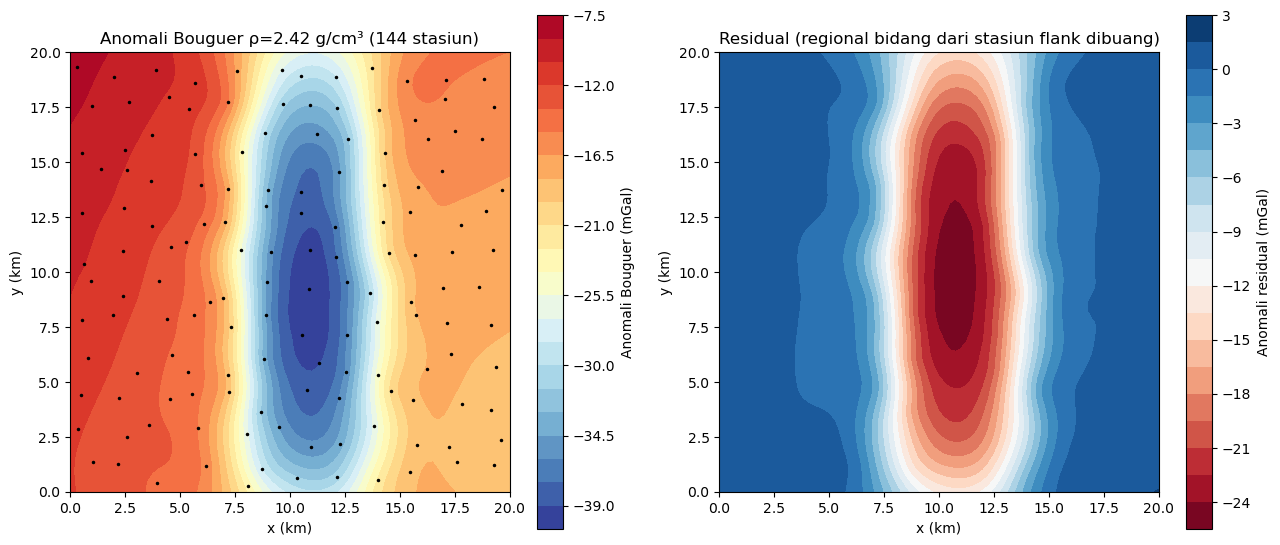

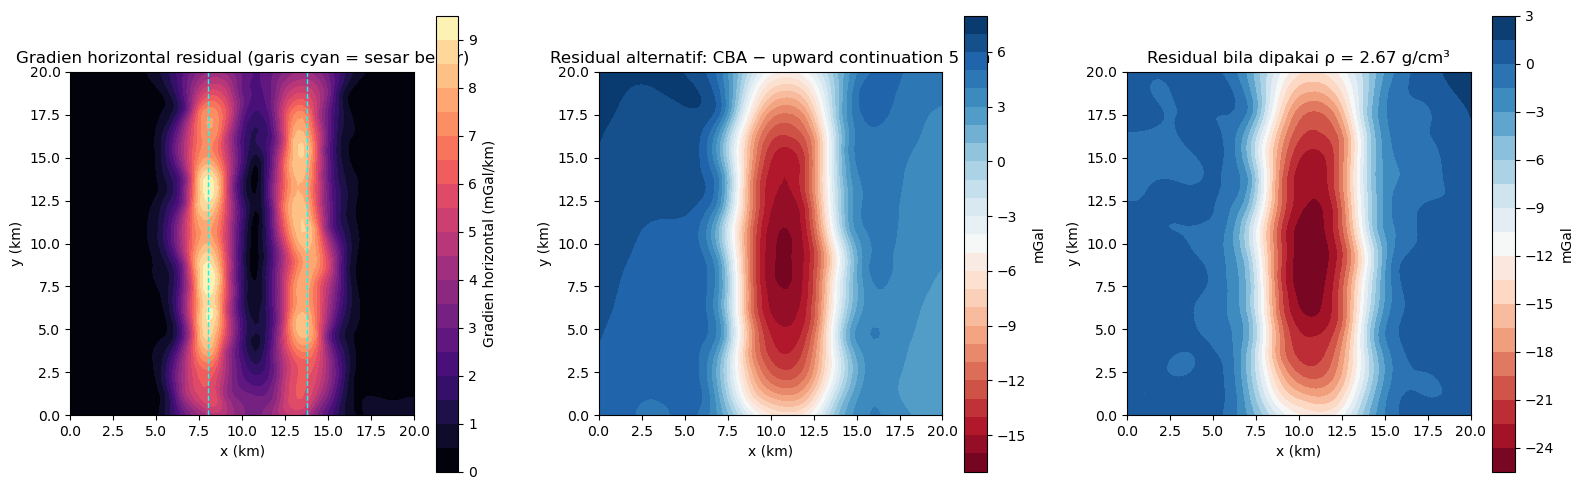

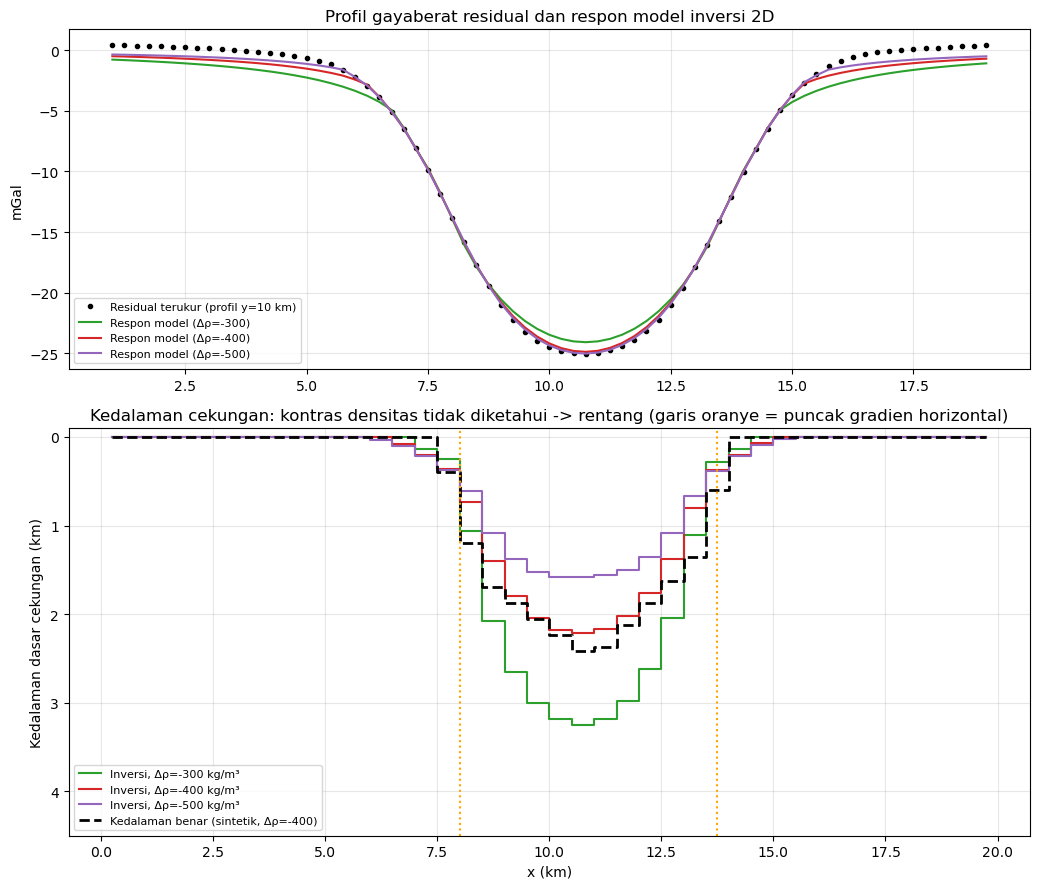

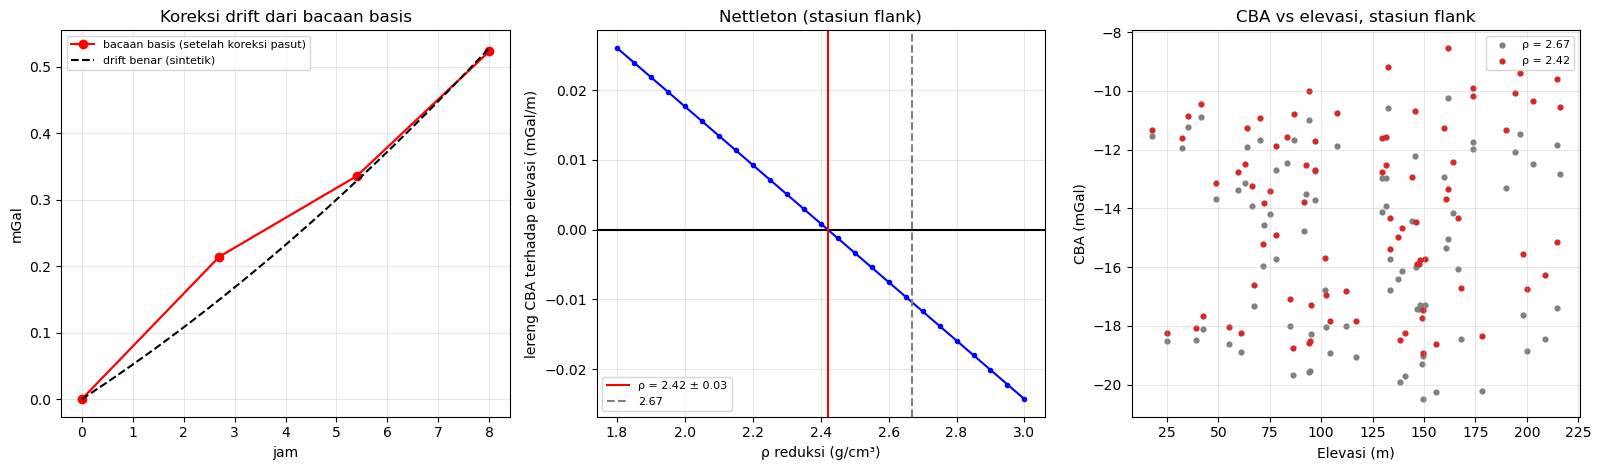

Selesai studi kasus 3.


In [26]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.6))
c = ax[0].contourf(GX / 1000, GY / 1000, CBA_g, 24, cmap="RdYlBu_r")
plt.colorbar(c, ax=ax[0], label="Anomali Bouguer (mGal)")
ax[0].plot(xs / 1000, ys / 1000, "k.", ms=3)
ax[0].set_title(f"Anomali Bouguer ρ={RHO_PAKAI} g/cm³ ({Ns} stasiun)")
c2 = ax[1].contourf(GX / 1000, GY / 1000, RES_g, 24, cmap="RdBu")
plt.colorbar(c2, ax=ax[1], label="Anomali residual (mGal)")
ax[1].set_title("Residual (regional bidang dari stasiun flank dibuang)")
for a in ax:
    a.set_xlabel("x (km)")
    a.set_ylabel("y (km)")
    a.set_aspect("equal")
plt.tight_layout()
plt.savefig(os.path.join(HASIL, "gambar_1_peta_bouguer_residual.png"), dpi=140)
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 5))
cc = ax[0].contourf(GX / 1000, GY / 1000, HGM, 20, cmap="magma")
plt.colorbar(cc, ax=ax[0], label="Gradien horizontal (mGal/km)")
for fx in fault_true_x:
    ax[0].axvline(fx, color="cyan", ls="--", lw=1)
ax[0].set_title("Gradien horizontal residual (garis cyan = sesar benar)")
c3 = ax[1].contourf(GX / 1000, GY / 1000, RES_uc, 24, cmap="RdBu")
plt.colorbar(c3, ax=ax[1], label="mGal")
ax[1].set_title("Residual alternatif: CBA − upward continuation 5 km")
c4 = ax[2].contourf(GX / 1000, GY / 1000, RES267, 24, cmap="RdBu")
plt.colorbar(c4, ax=ax[2], label="mGal")
ax[2].set_title("Residual bila dipakai ρ = 2.67 g/cm³")
for a in ax:
    a.set_xlabel("x (km)")
    a.set_ylabel("y (km)")
    a.set_aspect("equal")
plt.tight_layout()
plt.savefig(os.path.join(HASIL, "gambar_2_gradien_dan_alternatif.png"), dpi=140)
plt.show()

fig, ax = plt.subplots(2, 1, figsize=(10.5, 9), gridspec_kw={"height_ratios": [1, 1.2]})
ax[0].plot(xp / 1000, dp, "ko", ms=3, label="Residual terukur (profil y=10 km)")
for drho, col in zip(hasil_inv, ("tab:green", "tab:red", "tab:purple")):
    ax[0].plot(xp / 1000, hasil_inv[drho][1], color=col, label=f"Respon model (Δρ={drho:.0f})")
ax[0].set_ylabel("mGal")
ax[0].legend(fontsize=8)
ax[0].grid(alpha=0.3)
ax[0].set_title("Profil gayaberat residual dan respon model inversi 2D")
xc_ = 0.5 * (edges[:-1] + edges[1:]) / 1000.0
for (drho, (d_, _, _)), col in zip(hasil_inv.items(), ("tab:green", "tab:red", "tab:purple")):
    ax[1].step(xc_, d_, where="mid", color=col, label=f"Inversi, Δρ={drho:.0f} kg/m³")
ax[1].step(xc_, true_depth_prof, where="mid", color="k", ls="--", lw=2, label="Kedalaman benar (sintetik, Δρ=-400)")
for px_ in gxk[pk] / 1000:
    ax[1].axvline(px_, color="orange", ls=":")
ax[1].set_ylim(4.5, -0.1)
ax[1].set_xlabel("x (km)")
ax[1].set_ylabel("Kedalaman dasar cekungan (km)")
ax[1].legend(fontsize=8, loc="lower left")
ax[1].grid(alpha=0.3)
ax[1].set_title("Kedalaman cekungan: kontras densitas tidak diketahui -> rentang (garis oranye = puncak gradien horizontal)")
plt.tight_layout()
plt.savefig(os.path.join(HASIL, "gambar_3_profil_inversi_2D.png"), dpi=140)
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ax[0].plot(t_base, R_base_t - R_base_t[0], "ro-", label="bacaan basis (setelah koreksi pasut)")
tt = np.linspace(0, 8, 100)
ax[0].plot(tt, np.interp(tt, t_base, R_base_t - R_base_t[0]), "r-", alpha=0.4)
ax[0].plot(tt, drift_benar(tt) - drift_benar(0), "k--", label="drift benar (sintetik)")
ax[0].set_xlabel("jam")
ax[0].set_ylabel("mGal")
ax[0].set_title("Koreksi drift dari bacaan basis")
ax[0].legend(fontsize=8)
ax[0].grid(alpha=0.3)
ax[1].plot(rho_scan, slope_scan, "b.-")
ax[1].axhline(0, color="k")
ax[1].axvline(rho_N, color="r", label=f"ρ = {rho_N:.2f} ± {rho_N_se:.2f}")
ax[1].axvline(2.67, color="gray", ls="--", label="2.67")
ax[1].set_xlabel("ρ reduksi (g/cm³)")
ax[1].set_ylabel("lereng CBA terhadap elevasi (mGal/m)")
ax[1].set_title("Nettleton (stasiun flank)")
ax[1].legend(fontsize=8)
ax[1].grid(alpha=0.3)
ax[2].scatter(topo[flank], CBA_267[flank], s=12, c="gray", label="ρ = 2.67")
ax[2].scatter(topo[flank], CBA[flank], s=12, c="tab:red", label=f"ρ = {RHO_PAKAI}")
ax[2].set_xlabel("Elevasi (m)")
ax[2].set_ylabel("CBA (mGal)")
ax[2].set_title("CBA vs elevasi, stasiun flank")
ax[2].legend(fontsize=8)
ax[2].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(HASIL, "gambar_4_drift_dan_densitas.png"), dpi=140)
plt.show()

with open(os.path.join(HASIL, "ringkasan_angka.txt"), "w", encoding="utf-8") as f:
    f.write(f"Jumlah stasiun: {Ns}\n")
    f.write(f"Galat g_obs setelah koreksi drift/pasut (RMS): {galat_g.std():.3f} mGal\n")
    f.write(f"Densitas Bouguer (regresi flank): {rho_N:.3f} +- {rho_N_se:.3f} g/cm3 (benar {RHO_TOPO_BENAR})\n")
    f.write(f"Regional flank: {c_flank.round(3)} ; semua stasiun: {c_all.round(3)}\n")
    f.write(f"Galat residual RMS: flank {rms_flank:.2f} ; semua {rms_all:.2f}\n")
    f.write(f"Puncak HGM x (km): {(gxk[pk]/1000).round(2)} ; sesar benar {fault_true_x}\n\n")
    f.write(tahap.to_string(index=False) + "\n\n" + tab_dep.to_string(index=False) + "\n\n" + sens.to_string(index=False) + "\n")
print("Selesai studi kasus 3.")

---
## 3. Interpretasi

*Ditulis berdasarkan angka dan gambar yang dihasilkan sel-sel di atas (seed tetap, sehingga hasil dapat direproduksi).*

### 1. Alur pengolahan dan dampak tiap tahap

Urutan koreksi (sesuai batasan prompt): pasang surut → drift → lintang → udara bebas → Bouguer.

| Tahap | Rumus | Parameter | Dampak (mGal) |
|---|---|---|---|
| 1 Pasang surut | g − g_tide(t) (model) | amplitudo ±0,10 di stasiun | ±0,10 |
| 2 Drift instrumen | interpolasi linier 4 bacaan basis | 0; 2,7; 5,4; 8,0 jam | hingga 0,51 |
| 3 Lintang (GRS67) | 978031,846(1 + 0,005279 sin²φ + 0,0000235 sin⁴φ) | φ = −3,198° s/d −3,026° | rentang 1,67 |
| 4 Udara bebas | +0,3086 h | h = 18–217 m | hingga 67,1 |
| 5 Bouguer (slab) | −0,04193 ρ h | **ρ = 2,42 g/cm³** | hingga 22,1 |
| 6 Terrain | – | tidak dilakukan | tidak diketahui |

Setelah koreksi drift dan pasang surut, galat g_obs terhadap nilai sebenarnya hanya **0,036 mGal (RMS)**, jadi tahap awal ini sudah akurat.

![Drift, Nettleton, dan CBA vs elevasi](hasil/kasus3/gambar_4_drift_dan_densitas.png)

**Densitas reduksi tidak boleh sekadar 2,67.** Densitas diestimasi lewat regresi `FAA ~ 1 + x + y + h` pada **stasiun di luar cekungan** (n = 81; x < 6,5 km atau x > 15,5 km), karena di sana pengaruh cekungan nyaris nol. Hasil: **ρ = 2,42 ± 0,03 g/cm³** (nilai sebenarnya 2,40). Jika regresi memakai semua stasiun, anomali cekungan (hingga −25 mGal) akan menjadi *noise* dan perkiraan kasar saya menunjukkan ketidakpastian ρ jauh lebih besar (orde ±0,3 g/cm³, tidak dihitung di skrip), karena itu stasiun flank dipakai.

### 2. Anomali Bouguer dan pemisahan regional–residual

![Peta Bouguer dan residual](hasil/kasus3/gambar_1_peta_bouguer_residual.png)

Anomali Bouguer berkisar **−39,6 hingga −8,5 mGal**, dengan lembah anomali di bagian tengah.

**Regional** diestimasi sebagai bidang orde-1 dari stasiun flank:

| Cara | Koefisien (konstanta; per km-x; per km-y) | Galat residual vs efek cekungan benar |
|---|---|---|
| **Bidang dari stasiun flank (dipakai)** | −12,85; −0,366; +0,204 | **0,87 mGal** |
| Bidang dari semua stasiun | −17,30; −0,525; +0,203 | 6,97 mGal |
| Benar (sintetik) | −12,0; −0,35; +0,20 | – |

Memasukkan stasiun di atas cekungan ke regresi regional "menarik" bidang ke bawah (konstanta bergeser 4,5 mGal) dan membuat residual salah ±7 mGal. Ini alasan mengapa pemisahan regional–residual harus **menyebut metodenya dan datanya**.

![Gradien horizontal dan residual alternatif](hasil/kasus3/gambar_2_gradien_dan_alternatif.png)

### 3. Interpretasi: patahan

Gradien horizontal (HGM) residual di sepanjang y ≈ 10 km memiliki dua puncak, di **x = 8,0 km** dan **x = 13,75 km**, masing-masing ±8 mGal/km. Posisi ini tepat berimpit dengan dua batas sesar normal pada model sebenarnya.

Dua indikator mendukung keberadaan sesar di kedua posisi itu: (1) puncak HGM yang tajam pada kedua sisi; (2) kontur anomali yang merapat di zona tersebut. Karena dua indikator konsisten, **keyakinan lokasi sesar tinggi**. Residual alternatif (CBA − *upward continuation* 5 km) menghasilkan pola yang sama, sehingga hasil tidak bergantung pada cara memisahkan regional.

Pola gradien yang serupa di kedua sisi menunjukkan **struktur graben dengan dua tepi curam**; bentuk lantai cekungan, yang miring dan lebih dalam ke arah barat-tengah, tampak dari inversi di bawah.

### 4. Interpretasi: kedalaman cekungan (tidak unik)

![Profil dan inversi 2D](hasil/kasus3/gambar_3_profil_inversi_2D.png)

Profil residual y = 10 km (minimum **−25,0 mGal**) diinversikan dengan kolom 2D berlebar 0,5 km dan regularisasi kehalusan. Karena kontras densitas tidak diketahui, saya jalankan tiga asumsi:

| Asumsi Δρ (kg/m³) | Kedalaman maks (km) | RMS misfit (mGal) | Slab Bouguer / batas bawah (km) |
|---|---|---|---|
| −300 | 3,25 | 1,17 | 1,99 |
| **−400** | **2,22** | 0,70 | 1,49 |
| −500 | 1,58 | 0,50 | 1,19 |

Ketiga model sama-sama cocok dengan data (RMS ≤ 1,2 mGal), tetapi kedalamannya berbeda hampir **dua kali lipat**. Ini wujud nyata ketidakunikan solusi gayaberat: **amplitudo anomali hanya menentukan hasil kali (ketebalan × kontras densitas)**. Kedalaman sebenarnya 2,4–2,5 km; asumsi −400 kg/m³ memulihkan 2,22 km (±8 % lebih dangkal, efek regularisasi), sedangkan asumsi yang salah (−300 atau −500) meleset ±35–40 %.

**Kesimpulan:** cekungan sedimen dalamnya ±1,6–3,3 km dengan titik terdalam di sekitar x ≈ 10–11 km; angka tunggal tidak boleh dilaporkan tanpa asumsi densitas. Slab Bouguer (1,2–2,0 km) hanya batas bawah karena cekungan tidak tak-hingga lebar.

### 5. Verifikasi (V): sensitivitas densitas reduksi

| Skenario | Min residual (mGal) | Galat RMS vs benar | Puncak HGM x (km) | Korelasi residual–elevasi (flank) |
|---|---|---|---|---|
| ρ = 2,42 (regresi) | −25,03 | 0,87 | 8,0 ; 13,75 | **0,003** |
| ρ = 2,67 (standar) | −25,20 | 1,01 | 8,0 ; 13,75 | **−0,628** |

Kesimpulan struktural (posisi sesar, amplitudo cekungan) **tidak berubah** bila ρ = 2,67 dipakai; hasil geologi kasar aman. Namun pada ρ = 2,67 residual berkorelasi kuat negatif (−0,63) dengan topografi: koreksi Bouguer berlebihan menanamkan "bayangan topografi" ke dalam peta. Untuk interpretasi detail (mis. sesar kecil), perbedaan ini penting.

### 6. Keterbatasan

Koreksi medan tidak dilakukan (dengan relief hingga ±200 m efeknya bisa signifikan di dekat lereng curam, besarnya tidak dapat dihitung tanpa DEM); jarak stasiun ±1,7 km membatasi resolusi struktur kecil; inversi 2D memperlakukan graben tak hingga panjang padahal model sebenarnya menyempit ke arah y = 0 dan 20 km; kontras densitas tunggal adalah penyederhanaan (sedimen sebenarnya bertambah rapat terhadap kedalaman).

---

# **Studi Kasus 4 - Magnetik: RTP untuk Eksplorasi Bijih Besi (Lintang Rendah)**

## 1. Prompt (struktur R-T-C-I-K-O-Q-V)

## Prompt 4 - Magnetik: Reduksi ke Kutub untuk Eksplorasi Mineral Bijih Besi

**Role:**
Kamu adalah seorang geofisikawan eksplorasi mineral yang berpengalaman dalam pengolahan dan interpretasi data magnetik total (TMI) untuk target bijih besi dan mineral magnetik.

**Task:**
Rancang dan jelaskan alur pengolahan data medan magnet total mulai dari koreksi variasi harian dan IGRF hingga reduksi ke kutub (RTP), lalu interpretasikan anomali magnetik untuk menentukan zona prospek bijih besi.

**Context:**
Area berada di zona lintang rendah (mendekati ekuator magnetik), tempat anomali dipolar sangat asimetris dan sulit dibaca langsung. Target adalah tubuh bijih magnetit yang memiliki suseptibilitas tinggi di dalam batuan samping bersuseptibilitas rendah.

**Input:**
Tabel titik ukur: koordinat, medan magnet total (nT), waktu ukur, data base station harian, serta parameter IGRF lokasi (deklinasi, inklinasi, intensitas). Jika belum tersedia, minta pengguna melampirkan.

**Constraints:**
- Jelaskan koreksi variasi harian dan pengurangan medan utama (IGRF) secara berurutan sebelum RTP.
- Sebutkan bahwa RTP di lintang rendah tidak stabil dan bagaimana cara menanganinya (mis. RTE atau sinyal analitik sebagai alternatif).
- Jangan mengasumsikan magnetisasi murni induksi bila ada kemungkinan remanen; nyatakan sebagai asumsi.
- Jangan menyebut cadangan atau kadar bijih; hanya tandai zona prospek.
- Failure behavior: jika data base station tidak tersedia, laporkan bahwa koreksi harian tidak dapat dilakukan dan kualitas hasil berkurang, lalu tanyakan cara pengganti sebelum lanjut.

**Output:**
Rencana output berupa narasi dan tabel teks (tanpa gambar):
1. *Narasi alur pengolahan* beserta alasan tiap tahap.
2. *Narasi interpretasi anomali*: posisi dan pola anomali tinggi/rendah setelah RTP, bentuk tubuh yang diduga (dyke, lensa, atau massif), serta prioritas zona untuk pengeboran eksplorasi.
Ditambah tabel teks daftar target: nama zona, karakter anomali, dugaan tubuh, tingkat prioritas, dan risiko interpretasi.

**Quality criteria:**
- Urutan koreksi benar dan istilah (TMI, IGRF, RTP, sinyal analitik) dipakai konsisten.
- Ada pembahasan keterbatasan RTP pada lintang rendah.
- Prioritas target didukung alasan geofisika, bukan hanya nilai anomali tertinggi.
- Asumsi induksi/remanen dinyatakan eksplisit.

**Optional verification (V):**
Bila diperlukan, bandingkan zona prospek hasil RTP dengan zona hasil sinyal analitik (yang tidak bergantung arah magnetisasi); nyatakan apakah lokasi puncaknya konsisten.

## 2. Kode dan hasil

Kode dipecah per tahap. Jalankan sel dari atas ke bawah.

### Persiapan: impor pustaka dan folder keluaran

In [27]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import ndimage

BASE = os.getcwd()          # folder tempat notebook ini disimpan
DATA = os.path.join(BASE, "data", "kasus4")
HASIL = os.path.join(BASE, "hasil", "kasus4")
os.makedirs(DATA, exist_ok=True)
os.makedirs(HASIL, exist_ok=True)
rng = np.random.default_rng(77)

### 0. Parameter Medan Induksi (Hipotetis)

In [28]:
F0 = 42000.0                 # nT
INC = -15.0                  # derajat (negatif = belahan bumi selatan; lintang magnetik rendah)
DEC = 1.0                    # derajat
MU0 = 4e-7 * np.pi
H0 = F0 * 1e-9 / MU0         # A/m


def arah(inc, dec):
    i, d = np.deg2rad(inc), np.deg2rad(dec)
    return np.array([np.cos(i) * np.cos(d), np.cos(i) * np.sin(d), np.sin(i)])    # (Utara, Timur, Bawah)


f_hat = arah(INC, DEC)

### 1. MODEL SUMBER -> ANOMALI dT (dipol kubus)

In [29]:
def kubus(x0, x1, y0, y1, z0, z1, s=10.0):
    xe = np.arange(x0 + s / 2, x1, s)
    ye = np.arange(y0 + s / 2, y1, s)
    ze = np.arange(z0 + s / 2, z1, s)
    X, Y, Z = np.meshgrid(xe, ye, ze, indexing="ij")
    return np.c_[Y.ravel(), X.ravel(), Z.ravel()], s**3          # (N, E, D)


def delta_T(xo, yo, zo, src, mvec, f, chunk=300):
    """Anomali medan total (nT) dari dipol-dipol; src (M,3)=(N,E,D), mvec (M,3) A.m2."""
    out = np.zeros(len(xo))
    mf = mvec @ f
    for a in range(0, len(xo), chunk):
        sl = slice(a, a + chunk)
        dN = yo[sl, None] - src[None, :, 0]
        dE = xo[sl, None] - src[None, :, 1]
        dD = zo - src[None, :, 2]
        r2 = dN**2 + dE**2 + dD**2
        r = np.sqrt(r2)
        mr = mvec[:, 0] * dN + mvec[:, 1] * dE + mvec[:, 2] * dD
        rf = f[0] * dN + f[1] * dE + f[2] * dD
        out[sl] = (1e-7 * (3 * mr * rf / r2 - mf[None, :]) / r**3).sum(1) * 1e9
    return out


# definisi benda (E: timur, N: utara, kedalaman z positif ke bawah, dalam meter)
benda = {
    "A": dict(box=(850, 1150, 1700, 1850, 40, 160), chi=0.15, remanen=None),
    "B": dict(box=(2000, 2100, 800, 900, 20, 70), chi=0.08, remanen=(1.5, 50.0, 190.0)),   # Q, Ir, Dr
    "C": dict(box=(500, 560, 450, 510, 50, 110), chi=0.02, remanen=None),
    "D": dict(box=(1680, 1720, 2480, 2520, 1, 6), chi=0.05, remanen=None, s=5.0),   # timbunan besi/slag dangkal
}


def kumpulkan(f_ind, sertakan=("A", "B", "C", "D"), remanen_aktif=True):
    S, M = [], []
    for nama, b in benda.items():
        if nama not in sertakan:
            continue
        pos, vol = kubus(*b["box"], s=b.get("s", 10.0))
        Mi = b["chi"] * H0 * f_ind
        if b["remanen"] is not None and remanen_aktif:
            Q, Ir, Dr = b["remanen"]
            Mi = Mi + Q * b["chi"] * H0 * arah(Ir, Dr)
        S.append(pos)
        M.append(np.tile(Mi * vol, (len(pos), 1)))
    return np.vstack(S), np.vstack(M)


# grid survei : 3 x 3 km, spasi 25 m
dx = 25.0
nx = ny = 120
xg = (np.arange(nx) + 0.5) * dx
yg = (np.arange(ny) + 0.5) * dx
XG, YG = np.meshgrid(xg, yg)                      # baris = utara, kolom = timur
xo, yo = XG.ravel(), YG.ravel()
Z_SENSOR = -2.0                                   # sensor 2 m di atas tanah

src, mv = kumpulkan(f_hat)
dT_anom = delta_T(xo, yo, Z_SENSOR, src, mv, f_hat)
print(f"Anomali sintetik dibangkitkan: {len(src)} dipol, rentang {dT_anom.min():.0f} s/d {dT_anom.max():.0f} nT")

# "kebenaran" di kutub (vertikal) untuk sumber induksi murni A dan C -> hanya untuk menguji RTP
f_pole = np.array([0.0, 0.0, 1.0])
srcP, mvP = kumpulkan(f_pole, sertakan=("A", "C"))
dT_pole_AC = delta_T(xo, yo, Z_SENSOR, srcP, mvP, f_pole).reshape(ny, nx)

Anomali sintetik dibangkitkan: 6180 dipol, rentang -995 s/d 522 nT


### 2. DATA "LAPANGAN" : IGRF + anomali + tren geologi + noise + variasi harian

In [30]:
def igrf_lokal(x, y):
    return F0 + 0.004 * (y - 1500.0) - 0.002 * (x - 1500.0)       # nT (gradien regional medan utama)


def harian(t):
    return 12 * np.sin(2 * np.pi * (t - 1.0) / 10.0) + 4 * np.sin(2 * np.pi * t / 1.7) + 8 * np.exp(-((t - 3.5) / 0.15) ** 2)


tren_geologi = 15.0 * XG / 3000 - 10.0 * YG / 3000
geo_noise = ndimage.gaussian_filter(rng.normal(0, 1, (ny, nx)), 3)
geo_noise *= 3.0 / geo_noise.std()
# urutan waktu : jalur utara-selatan zig-zag
t_pt = np.zeros((ny, nx))
dt = 6.0 / (nx * ny)
for i in range(nx):
    idx = np.arange(ny) if i % 2 == 0 else np.arange(ny)[::-1]
    t_pt[idx, i] = (i * ny + np.arange(ny)) * dt
TMI = (igrf_lokal(XG, YG) + dT_anom.reshape(ny, nx) + tren_geologi + geo_noise
       + harian(t_pt) + rng.normal(0, 1.0, (ny, nx)))

t_base = np.arange(0, 6.0, 1 / 60)
base_baca = igrf_lokal(100.0, 100.0) + harian(t_base) + rng.normal(0, 0.2, t_base.size)

pd.DataFrame({"x_E_m": XG.ravel(), "y_N_m": YG.ravel(), "waktu_jam": t_pt.ravel().round(4),
              "TMI_nT": TMI.ravel().round(2)}).to_csv(os.path.join(DATA, "data_TMI_sintetik.csv"), index=False)
pd.DataFrame({"waktu_jam": t_base.round(4), "base_nT": base_baca.round(2)}).to_csv(
    os.path.join(DATA, "data_base_station_sintetik.csv"), index=False)

### 3. Pengolahan

In [31]:
# 3a. koreksi variasi harian
variasi = np.interp(t_pt.ravel(), t_base, base_baca - base_baca.mean()).reshape(ny, nx)
TMI_h = TMI - variasi
print(f"3a variasi harian : rentang {variasi.min():.1f} s/d {variasi.max():.1f} nT ; "
      f"std data sebelum = {TMI.std():.1f}, sesudah = {TMI_h.std():.1f} nT")

# 3b. kurangi IGRF (medan utama diketahui) -> anomali + tren + noise
# (rata-rata base station dipakai untuk mengikat nilai absolut: base_baca.mean() ~ igrf + rata-rata harian)
anom = TMI_h - igrf_lokal(XG, YG)
anom -= np.median(anom)                                    # ikat ke median (offset konstan dibuang)

# 3c. tren bidang (regresi dengan pemangkasan sigma agar tidak ditarik oleh anomali)
mask = np.ones_like(anom, bool)
for _ in range(6):
    Ap = np.c_[np.ones(mask.sum()), XG[mask] / 1000, YG[mask] / 1000]
    c, *_ = np.linalg.lstsq(Ap, anom[mask], rcond=None)
    tren = c[0] + c[1] * XG / 1000 + c[2] * YG / 1000
    r = anom - tren
    mask = np.abs(r) < 3 * np.std(r[mask])
dT_proc = anom - tren
print(f"3c tren bidang : koefisien = {c.round(2)} nT (benar tren: +5 nT/km timur, -3.3 nT/km utara)")
galat_proc = dT_proc - dT_anom.reshape(ny, nx)
print(f"   galat anomali hasil olah vs anomali benar : RMS = {galat_proc.std():.2f} nT")

3a variasi harian : rentang -13.7 s/d 15.1 nT ; std data sebelum = 63.0, sesudah = 62.5 nT
3c tren bidang : koefisien = [-2.16  4.15 -3.25] nT (benar tren: +5 nT/km timur, -3.3 nT/km utara)
   galat anomali hasil olah vs anomali benar : RMS = 3.21 nT


### 4. RTP (domain frekuensi) : naif vs stabil di lintang rendah

In [32]:
def rtp(grid, dx_, inc, dec, inc_amp, tanda=+1, pad=40):
    gp = np.pad(grid, pad, mode="reflect")
    # taper kosinus pada tepi padding
    w = np.ones(gp.shape[0])
    tp = np.hanning(2 * pad)[:pad]
    w[:pad] = tp
    w[-pad:] = tp[::-1]
    gp = gp * np.outer(w, w)
    ny_, nx_ = gp.shape
    kx = 2 * np.pi * np.fft.fftfreq(nx_, dx_)
    ky = 2 * np.pi * np.fft.fftfreq(ny_, dx_)
    KX, KY = np.meshgrid(kx, ky)
    th = np.arctan2(KX, KY)                          # azimut bilangan gelombang dari utara
    i_, d_ = np.deg2rad(inc), np.deg2rad(dec)
    ia = np.deg2rad(inc_amp)
    denom = (np.sin(ia) + tanda * 1j * np.cos(i_) * np.cos(d_ - th)) ** 2
    L = 1.0 / denom
    out = np.real(np.fft.ifft2(np.fft.fft2(gp) * L))
    return out[pad:-pad, pad:-pad], np.abs(L).max()


# tentukan tanda konvensi i yang benar lewat uji terhadap model di kutub (hanya sumber induksi murni A & C)
dT_AC = delta_T(xo, yo, Z_SENSOR, *kumpulkan(f_hat, sertakan=("A", "C")), f_hat).reshape(ny, nx)
cand = {}
for tanda in (+1, -1):
    hasil_, amp_ = rtp(dT_AC, dx, INC, DEC, INC, tanda)
    cand[tanda] = np.corrcoef(hasil_.ravel(), dT_pole_AC.ravel())[0, 1]
TANDA = max(cand, key=cand.get)
print(f"4  uji konvensi RTP (korelasi dengan model kutub): +1 -> {cand[1]:.3f} ; -1 -> {cand[-1]:.3f} ; dipilih {TANDA:+d}")

quiet = (XG > 2300) & (YG > 2700)           # jendela tanpa sumber (utara-timur laut), untuk mengukur penguatan noise
print(f"   RMS anomali hasil olah di jendela tenang = {dT_proc[quiet].std():.2f} nT (galat vs benar {galat_proc[quiet].std():.2f})")
scan = []
for imin in (15.0, 20.0, 25.0, 30.0, 35.0, 45.0):
    ia_ = np.sign(INC) * max(abs(INC), imin)
    g_, amp_ = rtp(dT_proc, dx, INC, DEC, ia_, TANDA)
    scan.append({"I_amp (deg)": ia_, "Amplifikasi maks filter (x)": round(amp_, 1),
                 "Korelasi dg model kutub A+C": round(np.corrcoef(g_.ravel(), dT_pole_AC.ravel())[0, 1], 3),
                 "RMS di jendela tenang (nT)": round(g_[quiet].std(), 2),
                 "Puncak maks (nT)": round(g_.max())})
scan = pd.DataFrame(scan)
scan.to_csv(os.path.join(HASIL, "uji_stabilisasi_RTP.csv"), index=False)
print(scan.to_string(index=False))

I_MIN = 25.0                                  # kompromi: bentuk anomali terjaga, noise stripping ditekan
inc_stabil = np.sign(INC) * max(abs(INC), I_MIN)
RTP_naif, amp_naif = rtp(dT_proc, dx, INC, DEC, INC, TANDA)
RTP_stab, amp_stab = rtp(dT_proc, dx, INC, DEC, inc_stabil, TANDA)
print(f"   dipilih I_amp = {inc_stabil:.0f} deg ; amplifikasi maks filter : naif = {amp_naif:.1f}x ; stabil = {amp_stab:.1f}x")
for nama, g_ in (("RTP naif", RTP_naif), ("RTP stabil", RTP_stab)):
    print(f"   {nama}: rentang {g_.min():.0f} s/d {g_.max():.0f} nT ; korelasi dg model kutub A+C = "
          f"{np.corrcoef(g_.ravel(), dT_pole_AC.ravel())[0,1]:.3f} ; RMS jendela tenang = {g_[quiet].std():.2f} nT")

4  uji konvensi RTP (korelasi dengan model kutub): +1 -> 0.998 ; -1 -> 0.197 ; dipilih +1
   RMS anomali hasil olah di jendela tenang = 2.49 nT (galat vs benar 2.49)
 I_amp (deg)  Amplifikasi maks filter (x)  Korelasi dg model kutub A+C  RMS di jendela tenang (nT)  Puncak maks (nT)
       -15.0                         14.9                        0.911                       13.38              1423
       -20.0                          8.5                        0.920                        8.54              1301
       -25.0                          5.6                        0.885                        6.26              1163
       -30.0                          4.0                        0.831                        4.90              1069
       -35.0                          3.0                        0.770                        4.00               973
       -45.0                          2.0                        0.649                        2.93               797
   dipilih I_am

### 5. SINYAL ANALITIK (tak bergantung arah magnetisasi) & turunan

In [33]:
def turunan(grid, dx_, pad=40):
    gp = np.pad(grid, pad, mode="reflect")
    tp = np.hanning(2 * pad)[:pad]
    w = np.ones(gp.shape[0])
    w[:pad] = tp
    w[-pad:] = tp[::-1]
    gp = gp * np.outer(w, w)
    ny_, nx_ = gp.shape
    kx = 2 * np.pi * np.fft.fftfreq(nx_, dx_)
    ky = 2 * np.pi * np.fft.fftfreq(ny_, dx_)
    KX, KY = np.meshgrid(kx, ky)
    Fg = np.fft.fft2(gp)
    # penyaring low-pass lembut (menekan noise 1 nT pada turunan)
    lp = np.exp(-(KX**2 + KY**2) * (1.5 * dx_) ** 2 / 2)
    sl = (slice(pad, -pad), slice(pad, -pad))
    Tx = np.real(np.fft.ifft2(1j * KX * Fg * lp))[sl]
    Ty = np.real(np.fft.ifft2(1j * KY * Fg * lp))[sl]
    Tz = np.real(np.fft.ifft2(np.sqrt(KX**2 + KY**2) * Fg * lp))[sl]       # turunan ke bawah
    Tf = np.real(np.fft.ifft2(Fg * lp))[sl]                                # data T dengan low-pass SAMA (wajib untuk Euler)
    return Tx, Ty, Tz, Tf


Tx, Ty, Tz, Tf = turunan(dT_proc, dx)
AS = np.sqrt(Tx**2 + Ty**2 + Tz**2)
print(f"5  sinyal analitik : maks = {AS.max():.2f} nT/m")

5  sinyal analitik : maks = 12.69 nT/m


### 6. TARGET : komponen terhubung pada sinyal analitik

In [34]:
sig_as = AS[quiet].std() if 'quiet' in globals() else AS.std()
ambang = 6 * AS[quiet].mean()
print(f"6  ambang deteksi sinyal analitik = {ambang:.2f} nT/m (AS rata-rata jendela tenang = {AS[quiet].mean():.3f})")
lab, nlab = ndimage.label(AS > ambang)
objs = []
for k in range(1, nlab + 1):
    m = lab == k
    if m.sum() < 3:
        continue
    iy, ix = np.unravel_index(np.argmax(np.where(m, AS, -1)), AS.shape)
    objs.append(dict(id=k, n_pix=int(m.sum()), area=float(m.sum() * dx * dx), ix=ix, iy=iy,
                     as_peak=float(AS[iy, ix]), x_as=float(xg[ix]), y_as=float(yg[iy]),
                     peak_rtp=float(RTP_stab[m].max()), min_rtp=float(RTP_stab[m].min()),
                     lebar=float(max(np.ptp(np.where(m)[1]), np.ptp(np.where(m)[0])) * dx + dx)))
objs = sorted(objs, key=lambda d: -d["as_peak"])[:6]
for o in objs:
    sel_ = (np.abs(XG - o["x_as"]) < 150) & (np.abs(YG - o["y_as"]) < 150)
    iy_, ix_ = np.unravel_index(np.argmax(np.where(sel_, RTP_stab, -1e9)), RTP_stab.shape)
    o["off_rtp_as"] = float(np.hypot(xg[ix_] - o["x_as"], yg[iy_] - o["y_as"]))

6  ambang deteksi sinyal analitik = 0.23 nT/m (AS rata-rata jendela tenang = 0.039)


### 7. EULER DEKONVOLUSI (jendela 9 x 9) di sekitar tiap target

In [35]:
def euler(ix0, iy0, N, half=4, rad=10):
    sols = []
    for iy in range(max(half, iy0 - rad), min(ny - half, iy0 + rad + 1)):
        for ix in range(max(half, ix0 - rad), min(nx - half, ix0 + rad + 1)):
            sl = (slice(iy - half, iy + half + 1), slice(ix - half, ix + half + 1))
            T = Tf[sl].ravel()
            Aa = np.c_[Tx[sl].ravel(), Ty[sl].ravel(), Tz[sl].ravel(), N * np.ones(T.size)]
            bb = XG[sl].ravel() * Tx[sl].ravel() + YG[sl].ravel() * Ty[sl].ravel() + N * T
            sol, res, rk, sv = np.linalg.lstsq(Aa, bb, rcond=None)
            r = bb - Aa @ sol
            s2 = r @ r / (T.size - 4)
            cov = s2 * np.linalg.inv(Aa.T @ Aa)
            se_z = np.sqrt(cov[2, 2])
            sols.append((sol[0], sol[1], sol[2], se_z))
    return np.array(sols)


euler_hasil = {}
euler_rows = []
for o in objs:
    kandidat = {}
    for half in (4, 6, 8):
        for N in (1, 2, 3):
            S = euler(o["ix"], o["iy"], N, half=half, rad=8)
            ok = (S[:, 2] > 1) & (S[:, 2] < 300) & (S[:, 3] < 0.25 * np.abs(S[:, 2]) + 3)
            if ok.sum() >= 5:
                kandidat[(half, N)] = float(np.median(S[ok, 2]))
                euler_rows.append({"target_id": o["id"], "jendela": f"{2*half+1}x{2*half+1}", "SI": N,
                                   "z_median (m)": round(float(np.median(S[ok, 2])), 1), "n_solusi": int(ok.sum())})
    euler_hasil[o["id"]] = kandidat
pd.DataFrame(euler_rows).to_csv(os.path.join(HASIL, "uji_euler_sensitivitas.csv"), index=False)

### 8. Pencocokan Dengan Sumber Benar & Tabel Prioritas

In [36]:
pusat_benar = {"A": (1000.0, 1775.0, 40.0), "B": (2050.0, 850.0, 20.0), "C": (530.0, 480.0, 50.0), "D": (1700.0, 2500.0, 1.0)}
baris = []
for o in objs:
    jarak = {k: np.hypot(o["x_as"] - v[0], o["y_as"] - v[1]) for k, v in pusat_benar.items()}
    kb = min(jarak, key=jarak.get)
    o["benar"] = kb if jarak[kb] < 150 else "-"
    e = list(euler_hasil[o["id"]].values())
    o["z_euler"] = float(np.median(e)) if len(e) else np.nan
    o["z_euler_min"] = float(np.min(e)) if len(e) else np.nan
    o["z_euler_max"] = float(np.max(e)) if len(e) else np.nan
    baris.append(o)

tab = pd.DataFrame([{
    "ID": f"T{i+1}", "x_E (m)": o["x_as"], "y_N (m)": o["y_as"],
    "Puncak sinyal analitik (nT/m)": round(o["as_peak"], 2),
    "Puncak RTP-stabil (nT)": round(o["peak_rtp"], 1),
    "Luas zona (m2)": round(o["area"]),
    "Offset RTP-AS (m)": round(o["off_rtp_as"]),
    "Lebar maks (m)": round(o["lebar"]),
    "Kedalaman Euler median (m)": None if np.isnan(o["z_euler"]) else round(o["z_euler"], 0),
    "Rentang Euler lintas pengaturan (m)": "-" if np.isnan(o["z_euler"]) else f"{o['z_euler_min']:.0f}-{o['z_euler_max']:.0f}",
    "Sumber benar (sintetik)": o["benar"],
} for i, o in enumerate(objs)])
print(tab.to_string(index=False))

# Penilaian prioritas berbasis alasan geofisika (bukan hanya amplitudo)
def beri_prioritas(row):
    luas, lebar = row["Luas zona (m2)"], row["Lebar maks (m)"]
    off = row["Offset RTP-AS (m)"]
    amp = row["Puncak RTP-stabil (nT)"]
    if lebar <= 150 and luas < 20000:
        return "RENDAH - zona kecil/lokal (<=150 m): bisa sumber dalam yang lemah ATAU sumber dangkal/kultural (tidak dapat dibedakan pada spasi 25 m); amplitudo tinggi BUKAN jaminan target bijih"
    if amp > 500 and luas > 100000:
        return "TINGGI - tubuh besar, anomali kuat, RTP dan sinyal analitik koheren (offset kecil)"
    if off > 75:
        return "SEDANG - anomali jelas tetapi RTP bergeser jauh dari sinyal analitik: indikasi remanen/asumsi induksi tidak berlaku; letakkan titik bor berdasar sinyal analitik"
    return "SEDANG - anomali jelas, perlu verifikasi"


tab["Prioritas & alasan"] = tab.apply(beri_prioritas, axis=1)
tab.to_csv(os.path.join(HASIL, "tabel_target_prospek.csv"), index=False)

ID  x_E (m)  y_N (m)  Puncak sinyal analitik (nT/m)  Puncak RTP-stabil (nT)  Luas zona (m2)  Offset RTP-AS (m)  Lebar maks (m)  Kedalaman Euler median (m) Rentang Euler lintas pengaturan (m) Sumber benar (sintetik)
T1   1012.5   1762.5                          12.69                  1162.7          654375                 35            1000                       127.0                              55-186                       A
T2   2062.5    887.5                           5.76                   142.1          121250                112             450                        75.0                              25-113                       B
T3   1687.5   2487.5                           0.87                   137.9           18750                 25             150                        59.0                               21-94                       D
T4    537.5    537.5                           0.26                    41.0            6875                 50             125              

### 9. VERIFIKASI : puncak RTP vs puncak sinyal analitik, dan perbandingan dengan pusat benar

In [37]:
ver = []
for o in objs:
    sel = (np.abs(XG - o["x_as"]) < 150) & (np.abs(YG - o["y_as"]) < 150)
    rt = np.where(sel, RTP_stab, -1e9)
    iy_, ix_ = np.unravel_index(np.argmax(rt), rt.shape)
    d_rtp_as = np.hypot(xg[ix_] - o["x_as"], yg[iy_] - o["y_as"])
    # puncak dT asli (sebelum RTP) = dipol : bergeser dari sumber
    ds = np.where(sel, dT_proc, -1e9)
    iy2, ix2 = np.unravel_index(np.argmax(ds), ds.shape)
    d_raw_as = np.hypot(xg[ix2] - o["x_as"], yg[iy2] - o["y_as"])
    kb = o["benar"]
    d_as_true = np.hypot(o["x_as"] - pusat_benar[kb][0], o["y_as"] - pusat_benar[kb][1]) if kb != "-" else np.nan
    d_rtp_true = np.hypot(xg[ix_] - pusat_benar[kb][0], yg[iy_] - pusat_benar[kb][1]) if kb != "-" else np.nan
    ver.append({"Sumber benar": kb, "Jarak puncak RTP-AS (m)": round(d_rtp_as, 0),
                "Jarak puncak dT-mentah-AS (m)": round(d_raw_as, 0),
                "Jarak AS-pusat benar (m)": None if np.isnan(d_as_true) else round(d_as_true, 0),
                "Jarak RTP-pusat benar (m)": None if np.isnan(d_rtp_true) else round(d_rtp_true, 0)})
ver = pd.DataFrame(ver)
ver.to_csv(os.path.join(HASIL, "verifikasi_RTP_vs_sinyal_analitik.csv"), index=False)
print(ver.to_string(index=False))

# efek tiap sumber benar secara terpisah (hanya evaluasi)
efek_sumber = {}
for nm in ("A", "B", "C", "D"):
    sA, mA = kumpulkan(f_hat, sertakan=(nm,))
    e_ = delta_T(xo, yo, Z_SENSOR, sA, mA, f_hat)
    efek_sumber[nm] = (e_.min(), e_.max())
print("Efek tiap sumber (min, maks nT):", {k: (round(v[0]), round(v[1])) for k, v in efek_sumber.items()})
terdeteksi = {o["benar"] for o in objs}
print("Sumber benar yang lolos ambang deteksi:", sorted(terdeteksi - {"-"}), "; tidak lolos:", sorted({"A", "B", "C", "D"} - terdeteksi))
pd.DataFrame([{"Sumber": k, "Min (nT)": round(v[0], 1), "Maks (nT)": round(v[1], 1), "Terdeteksi": k in terdeteksi}
              for k, v in efek_sumber.items()]).to_csv(os.path.join(HASIL, "evaluasi_deteksi_sumber.csv"), index=False)

pd.DataFrame({"Skenario": ["RTP naif (I_amp = I)", f"RTP stabil (I_amp = {inc_stabil:.0f})"],
              "Amplifikasi maks filter": [round(amp_naif, 1), round(amp_stab, 1)],
              "Korelasi dg model kutub A+C": [round(np.corrcoef(RTP_naif.ravel(), dT_pole_AC.ravel())[0, 1], 3),
                                              round(np.corrcoef(RTP_stab.ravel(), dT_pole_AC.ravel())[0, 1], 3)],
              "Min (nT)": [round(RTP_naif.min()), round(RTP_stab.min())],
              "Maks (nT)": [round(RTP_naif.max()), round(RTP_stab.max())]}).to_csv(
    os.path.join(HASIL, "perbandingan_RTP.csv"), index=False)

Sumber benar  Jarak puncak RTP-AS (m)  Jarak puncak dT-mentah-AS (m)  Jarak AS-pusat benar (m)  Jarak RTP-pusat benar (m)
           A                     35.0                          125.0                      18.0                       18.0
           B                    112.0                          100.0                      40.0                       88.0
           D                     25.0                           56.0                      18.0                       18.0
           C                     50.0                           35.0                      58.0                       11.0
Efek tiap sumber (min, maks nT): {'A': (-995, 522), 'B': (-446, 306), 'C': (-23, 11), 'D': (-162, 49)}
Sumber benar yang lolos ambang deteksi: ['A', 'B', 'C', 'D'] ; tidak lolos: []


### 10. Gambar

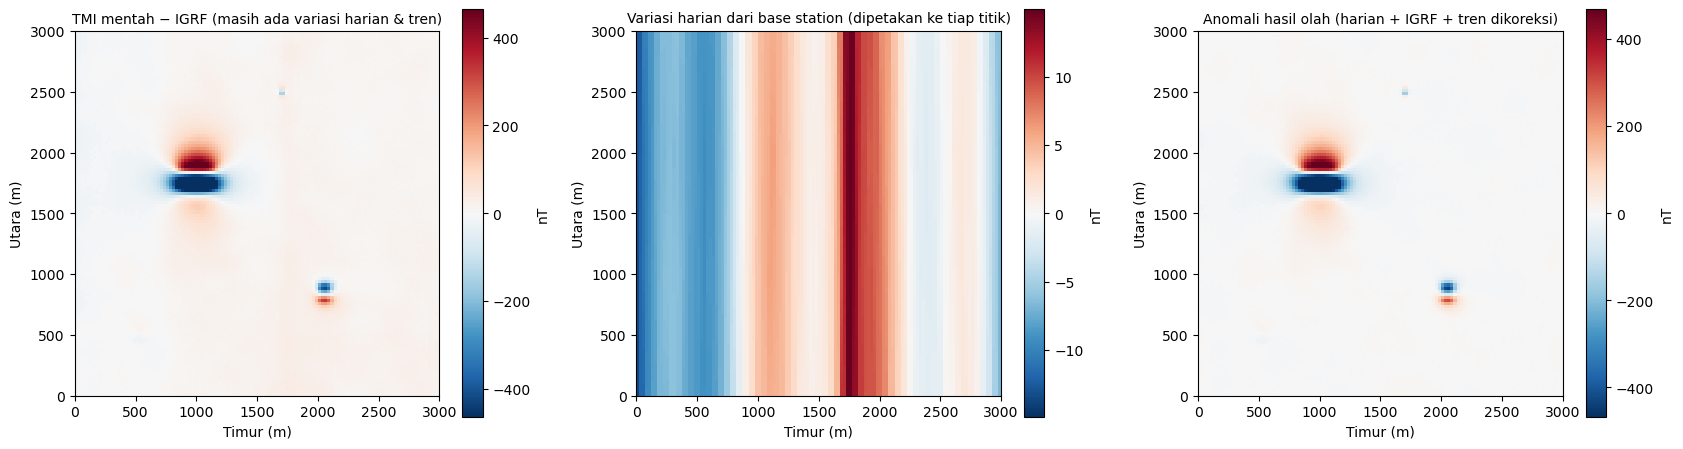

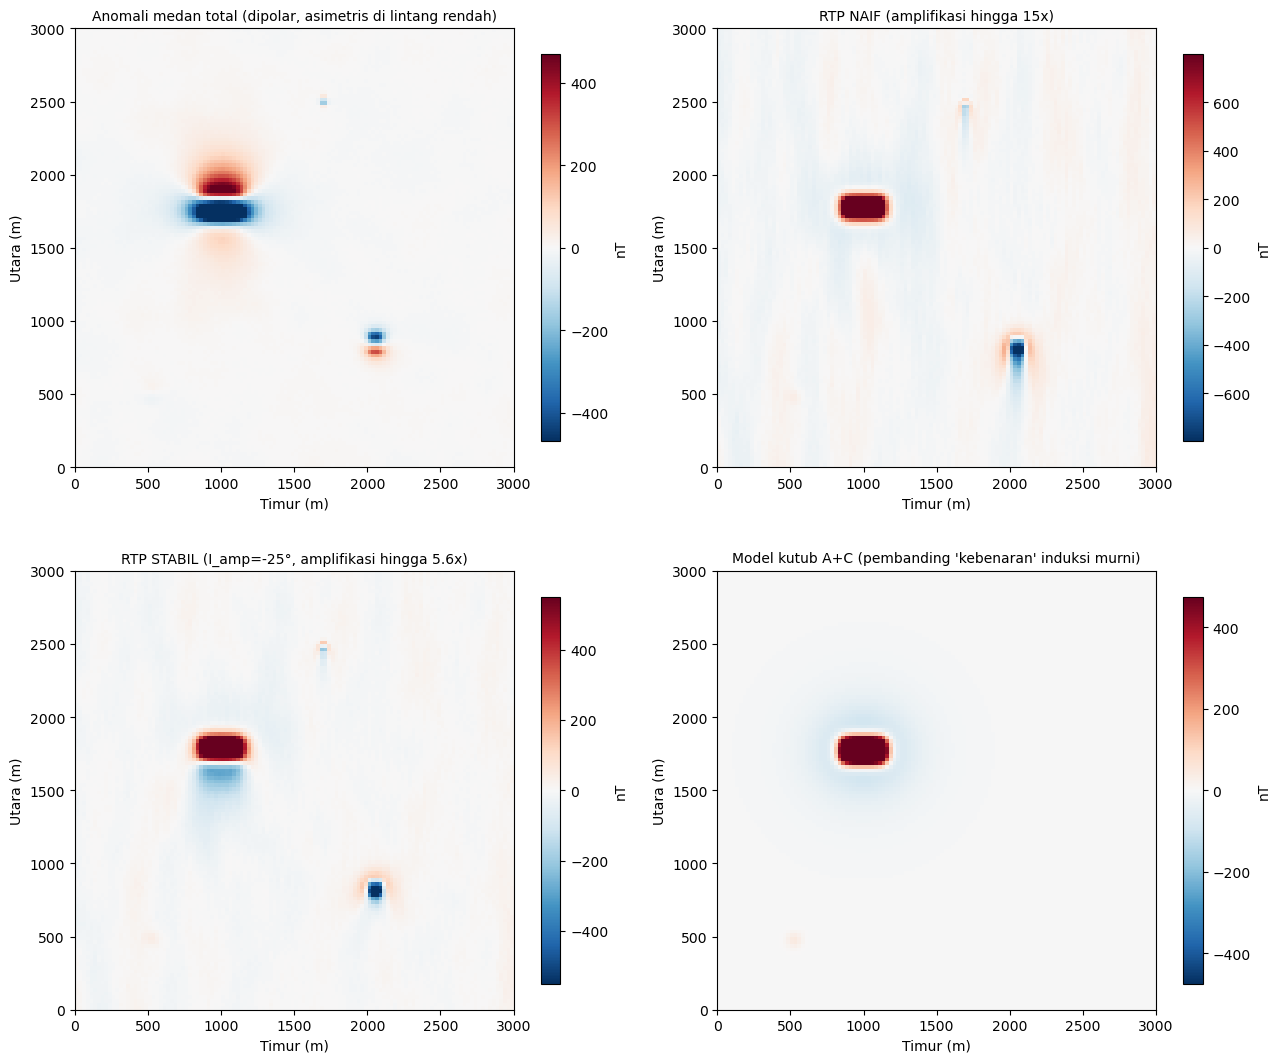

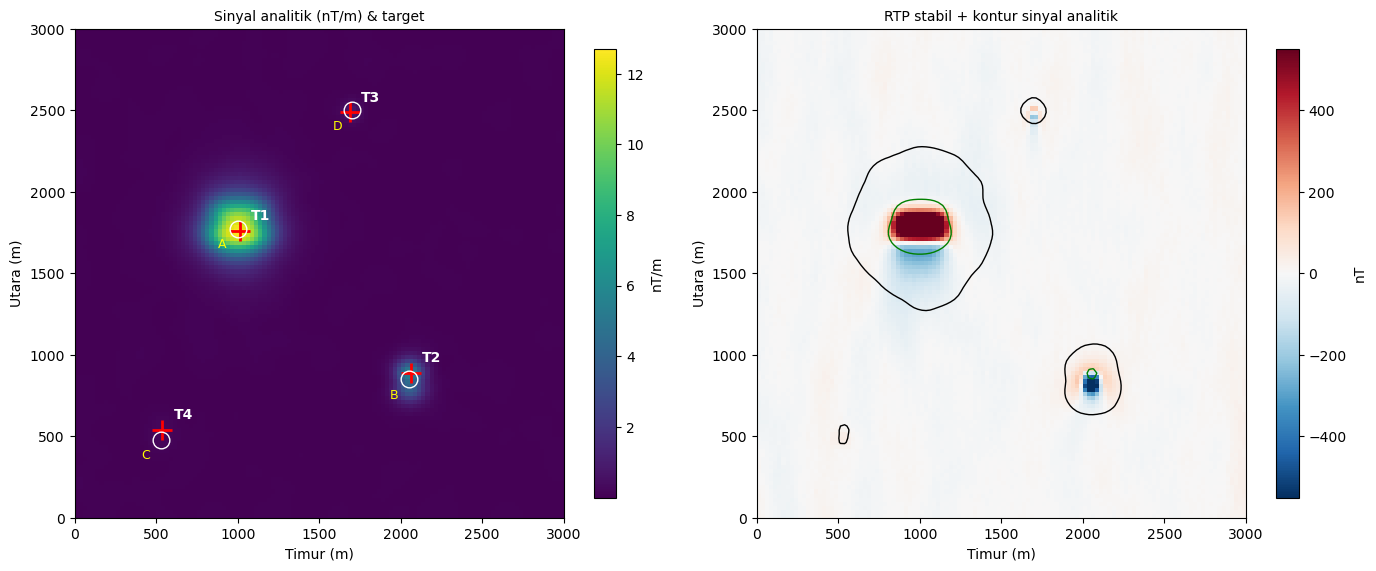

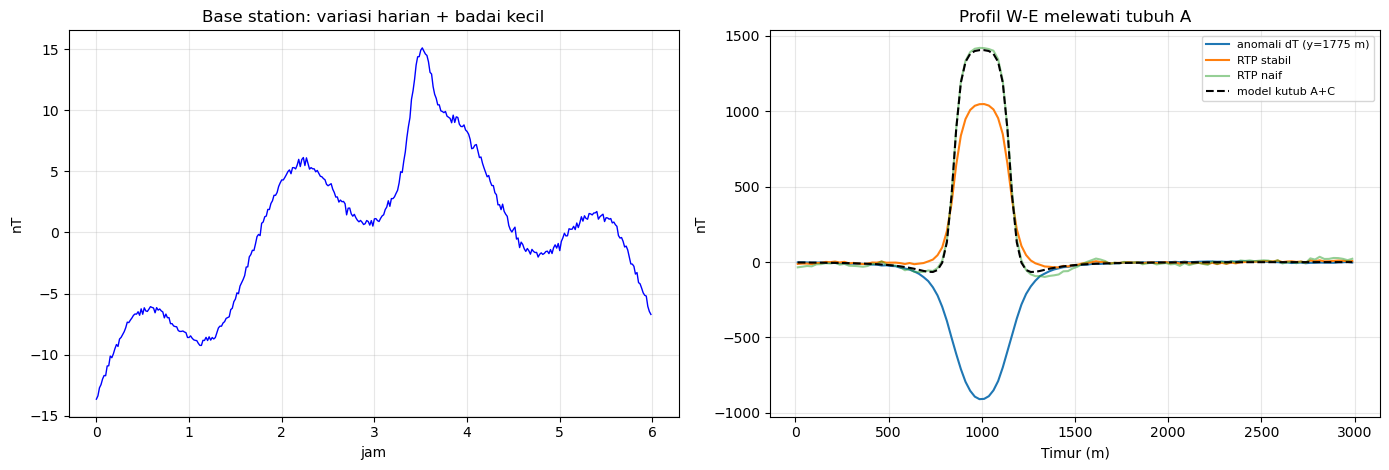

Selesai studi kasus 4.


In [38]:
ext = [0, nx * dx, 0, ny * dx]


def peta(ax_, grid, judul, cmap="RdBu_r", simetris=True, label="nT"):
    v = np.percentile(np.abs(grid), 99.5) if simetris else None
    im = ax_.imshow(grid, origin="lower", extent=ext, cmap=cmap,
                    vmin=-v if simetris else None, vmax=v if simetris else None)
    plt.colorbar(im, ax=ax_, label=label, shrink=0.8)
    ax_.set_title(judul, fontsize=10)
    ax_.set_xlabel("Timur (m)")
    ax_.set_ylabel("Utara (m)")


fig, ax = plt.subplots(1, 3, figsize=(17, 5.4))
peta(ax[0], TMI - igrf_lokal(XG, YG), "TMI mentah − IGRF (masih ada variasi harian & tren)")
peta(ax[1], variasi, "Variasi harian dari base station (dipetakan ke tiap titik)")
peta(ax[2], dT_proc, "Anomali hasil olah (harian + IGRF + tren dikoreksi)")
plt.tight_layout()
plt.savefig(os.path.join(HASIL, "gambar_1_pengolahan_dasar.png"), dpi=130)
plt.show()

fig, ax = plt.subplots(2, 2, figsize=(13, 11))
peta(ax[0, 0], dT_proc, "Anomali medan total (dipolar, asimetris di lintang rendah)")
peta(ax[0, 1], RTP_naif, f"RTP NAIF (amplifikasi hingga {amp_naif:.0f}x)")
peta(ax[1, 0], RTP_stab, f"RTP STABIL (I_amp={inc_stabil:.0f}°, amplifikasi hingga {amp_stab:.1f}x)")
peta(ax[1, 1], dT_pole_AC, "Model kutub A+C (pembanding 'kebenaran' induksi murni)")
plt.tight_layout()
plt.savefig(os.path.join(HASIL, "gambar_2_perbandingan_RTP.png"), dpi=130)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
peta(ax[0], AS, "Sinyal analitik (nT/m) & target", cmap="viridis", simetris=False, label="nT/m")
for i, o in enumerate(objs):
    ax[0].plot(o["x_as"], o["y_as"], "r+", ms=14, mew=2)
    ax[0].annotate(f"T{i+1}", (o["x_as"], o["y_as"]), xytext=(8, 8), textcoords="offset points", color="white", weight="bold")
for k, v in pusat_benar.items():
    ax[0].plot(v[0], v[1], "wo", mfc="none", ms=12)
    ax[0].annotate(k, (v[0], v[1]), xytext=(-14, -14), textcoords="offset points", color="yellow", fontsize=9)
peta(ax[1], RTP_stab, "RTP stabil + kontur sinyal analitik", label="nT")
ax[1].contour(XG, YG, AS, levels=[ambang, 0.4 * AS.max()], colors=["k", "g"], linewidths=1)
plt.tight_layout()
plt.savefig(os.path.join(HASIL, "gambar_3_sinyal_analitik_dan_target.png"), dpi=130)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].plot(t_base, base_baca - base_baca.mean(), "b-", lw=1)
ax[0].set_title("Base station: variasi harian + badai kecil")
ax[0].set_xlabel("jam")
ax[0].set_ylabel("nT")
ax[0].grid(alpha=0.3)
jy = int(np.argmin(np.abs(yg - 1775)))
ax[1].plot(xg, dT_proc[jy], label="anomali dT (y=1775 m)")
ax[1].plot(xg, RTP_stab[jy], label="RTP stabil")
ax[1].plot(xg, RTP_naif[jy], alpha=0.5, label="RTP naif")
ax[1].plot(xg, dT_pole_AC[jy], "k--", label="model kutub A+C")
ax[1].set_title("Profil W-E melewati tubuh A")
ax[1].set_xlabel("Timur (m)")
ax[1].set_ylabel("nT")
ax[1].legend(fontsize=8)
ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(HASIL, "gambar_4_base_dan_profil.png"), dpi=130)
plt.show()

with open(os.path.join(HASIL, "ringkasan_angka.txt"), "w", encoding="utf-8") as f:
    f.write(f"Medan hipotetis: F={F0} nT, I={INC}, D={DEC}\n")
    f.write(f"Variasi harian: {variasi.min():.1f} s/d {variasi.max():.1f} nT\n")
    f.write(f"Galat anomali hasil olah vs benar: RMS {galat_proc.std():.2f} nT\n")
    f.write(f"Amplifikasi filter: naif {amp_naif:.1f}x ; stabil {amp_stab:.1f}x\n\n")
    f.write(tab.to_string(index=False) + "\n\n" + ver.to_string(index=False) + "\n\n")
    f.write("Euler (median, Q1, Q3, n): " + str(euler_hasil) + "\n")
print("Selesai studi kasus 4.")

---
## 3. Interpretasi

*Ditulis berdasarkan angka dan gambar yang dihasilkan sel-sel di atas (seed tetap, sehingga hasil dapat direproduksi).*

### 1. Pengolahan dasar

![Pengolahan dasar](hasil/kasus4/gambar_1_pengolahan_dasar.png)

| Tahap | Hasil |
|---|---|
| Variasi harian (base station) | −13,7 hingga +15,1 nT, termasuk badai kecil pada t ≈ 3,5 jam; dikoreksi dengan interpolasi waktu |
| Kurangi IGRF | gradien medan utama (±4 nT/km) dibuang |
| Tren bidang (pemangkasan 3σ) | [−2,16 ; +4,15 nT/km ; −3,25 nT/km] (benar: +5 dan −3,3 nT/km) |
| Galat anomali hasil olah vs anomali benar | 3,21 nT RMS (2,49 nT di jendela tenang) |

Tren yang diestimasi sedikit lebih kecil dari yang sebenarnya (4,15 vs 5 nT/km) karena anomali besar ikut "menarik" bidang; ini galat kecil dibanding amplitudo target (ratusan nT).

### 2. RTP di lintang rendah: naif vs stabil

![Perbandingan RTP](hasil/kasus4/gambar_2_perbandingan_RTP.png)

Pada I = −15°, anomali medan total berbentuk dipol asimetris (panel kiri atas): kutub negatif besar di atas tubuh A, lobus positif di utara. RTP mengembalikan anomali menjadi satu puncak di atas tubuh (panel kanan bawah menunjukkan model kutub sebagai pembanding), **tetapi filternya tidak stabil**: penguatan maksimum **14,9×** pada arah bilangan gelombang yang tegak lurus deklinasi, sehingga noise dan variasi geologi halus berubah menjadi **goresan utara–selatan** (panel kanan atas).

Uji stabilisasi dengan mengganti inklinasi pada faktor amplitudo ("I_amp"):

| I_amp | Penguatan maks | Korelasi dengan model kutub (A+C) | RMS di jendela tenang (nT) |
|---|---|---|---|
| −15° (naif) | 14,9× | 0,911 | 13,38 |
| −20° | 8,5× | 0,920 | 8,54 |
| **−25° (dipilih)** | **5,6×** | **0,885** | **6,26** |
| −30° | 4,0× | 0,831 | 4,90 |
| −35° | 3,0× | 0,770 | 4,00 |
| −45° | 2,0× | 0,649 | 2,93 |

Noise di area tenang sebelum RTP adalah 2,49 nT. RTP naif memperbesarnya **5,4×** (13,4 nT), sedangkan I_amp = −25° hanya **2,5×** (6,3 nT) dengan penurunan korelasi bentuk yang kecil (0,911 → 0,885). Makin besar I_amp, noise makin kecil tetapi bentuk anomali makin terdistorsi (korelasi turun ke 0,65 pada −45°). Nilai −25° dipilih sebagai kompromi. Temuan ini bukan "stabil selalu lebih baik": pada data dengan S/N tinggi seperti ini, pilihan ringan (−20° s/d −25°) cukup.

**Konvensi tanda filter.** Tanda bagian imajiner filter diuji terhadap model kutub: tanda +1 menghasilkan korelasi 0,998, tanda −1 hanya 0,197. Pengujian semacam ini perlu dilakukan setiap kali memakai konvensi FFT yang berbeda.

### 3. Sinyal analitik, Euler, dan target

![Sinyal analitik dan target](hasil/kasus4/gambar_3_sinyal_analitik_dan_target.png)

Sinyal analitik (AS) tidak bergantung pada arah magnetisasi sehingga cocok untuk menentukan posisi sumber ketika asumsi induksi diragukan. Ambang deteksi = 6 × rata-rata AS di jendela tenang = 0,23 nT/m.

| ID | Sumber benar | x, y (m) | Puncak AS (nT/m) | Puncak RTP (nT) | Lebar (m) | Offset RTP–AS (m) | Euler (median; rentang) |
|---|---|---|---|---|---|---|---|
| T1 | A | 1012, 1762 | 12,69 | 1163 | 1000 | 35 | 127 m; 55–186 |
| T2 | B | 2062, 887 | 5,76 | 142 | 450 | **112** | 75 m; 25–113 |
| T3 | D | 1687, 2487 | 0,87 | 138 | 150 | 25 | 59 m; 21–94 |
| T4 | C | 537, 537 | 0,26 | 41 | 125 | 50 | 101 m; 48–154 |

> Lebar dan luas zona **bergantung pada ambang** (ambang rendah memperlebar halo AS), jadi dipakai hanya untuk membandingkan antar target, bukan sebagai ukuran tubuh sebenarnya.

### 4. Interpretasi dan prioritas (bukan hanya amplitudo tertinggi)

**T1 (tubuh A) — Prioritas TINGGI.** Anomali terkuat (RTP ±1160 nT; efek asli −995 s/d +522 nT), terluas, dan RTP serta AS koheren (offset 35 m, jauh lebih kecil dari lebar zona). Posisi AS hanya 18 m dari pusat sebenarnya. Ini target pengeboran utama.

**T2 (tubuh B) — Prioritas SEDANG, dengan peringatan remanen.** Pada RTP, tubuh ini muncul dengan lobus negatif (biru) dan positif yang tidak simetris, dan puncak RTP bergeser **112 m** dari puncak AS (benar: AS hanya 40 m dari pusat, RTP 88 m). Ini tanda khas bahwa **asumsi "induksi saja" tidak berlaku**; magnetisasi remanen memiringkan polaritas. Untuk menempatkan titik bor pada T2, gunakan posisi dari **sinyal analitik**, bukan puncak RTP.

**T3 dan T4 — Prioritas RENDAH.** Zona keduanya kecil (≤ 150 m). T3 punya amplitudo RTP 138 nT, hampir sama dengan T2, namun ukurannya hanya sepertiga dan sinyal analitiknya kecil. Pada spasi 25 m, **sumber dangkal/kultural dan sumber dalam yang lemah tidak dapat dibedakan**; di sistem sintetik ini T3 adalah timbunan besi dangkal dan T4 adalah tubuh dalam yang lemah (efek asli hanya −23 s/d +11 nT). Karena itu keduanya diberi prioritas rendah sampai ada pengecekan lapangan (kontaminasi besi di permukaan, suseptibilitas batuan). **Amplitudo tinggi bukan jaminan target bijih.**

**Tentang kedalaman Euler.** Kedalaman sangat bergantung pada indeks struktural dan ukuran jendela (T1: 55–186 m dan T2: 25–113 m untuk SI = 1 hingga 3 pada tiga ukuran jendela; lihat `hasil/kasus4/uji_euler_sensitivitas.csv`), jadi **tidak dipakai untuk memeringkat target**. Untuk T3 (benar: 1–6 m) Euler memberi 21–94 m: sumber yang lebih sempit dari spasi 25 m tidak dapat diselesaikan. Kedalaman puncak T1 sebenarnya 40 m dan pusatnya 100 m, jadi rentang Euler (55–186 m) wajar tetapi tidak presisi.

### 5. Verifikasi (V): RTP vs sinyal analitik

| Sumber | Jarak puncak RTP–AS (m) | AS–pusat benar (m) | RTP–pusat benar (m) |
|---|---|---|---|
| A | 35 | 18 | 18 |
| B | 112 | 40 | 88 |
| D | 25 | 18 | 18 |
| C | 50 | 58 | 11 |

Untuk sumber induksi murni (A, D) RTP dan AS sepakat dalam 35 m dan keduanya dekat pusat sebenarnya. Pada B (remanen) keduanya berselisih 112 m dan RTP lebih jauh dari kebenaran, persis seperti yang dipelajari: **ketidaksepakatan RTP–AS adalah detektor remanen yang berguna**.

![Base station dan profil](hasil/kasus4/gambar_4_base_dan_profil.png)

### 6. Keterbatasan

Pemodelan sumber dengan dipol kubus (10 m; 5 m untuk D) mengabaikan demagnetisasi diri, sehingga amplitudo tubuh dengan χ tinggi cenderung terlalu besar; tidak ada variasi ketinggian sensor atau topografi; IGRF hipotetis; spasi 25 m membatasi sumber dangkal; luas zona bergantung ambang; tidak ada data suseptibilitas batuan untuk memvalidasi tafsir "magnetit".

---

# **Studi Kasus 5 - Seismologi: Katalog Gempa, Mc, b-value, dan Tafsir Tegangan**

## 1. Prompt (struktur R-T-C-I-K-O-Q-V)

## Prompt 5 - Seismologi: Analisis Katalog Gempa dan b-value untuk Zona Sesar Aktif

**Role:**
Kamu adalah seorang seismolog analis bahaya gempa yang berpengalaman dalam analisis statistik katalog gempa dan evaluasi seismisitas regional.

**Task:**
Analisis katalog gempa di sekitar zona sesar aktif untuk menghitung kelengkapan magnitudo (Mc), nilai-b (b-value) dengan hukum Gutenberg–Richter, serta menafsirkan tingkat tegangan dan potensi bahaya seismik secara kualitatif.

**Context:**
Wilayah studi mencakup satu segmen sesar aktif di Sulawesi yang memiliki sejarah gempa menengah hingga besar. Perubahan b-value sering dikaitkan dengan kondisi tegangan (b rendah dapat mengindikasikan tegangan tinggi), tetapi hasilnya sensitif terhadap Mc dan ukuran sampel.

**Input:**
Katalog gempa berformat tabel: waktu kejadian, lintang, bujur, kedalaman (km), magnitudo, dan jenis magnitudo. Jika belum ada, minta pengguna melampirkan atau menyebut sumber katalog dan periode waktunya.

**Constraints:**
- Tentukan Mc dengan metode yang disebutkan (mis. *maximum curvature* atau *goodness-of-fit*) sebelum menghitung b-value.
- Hitung b dengan metode *maximum likelihood* (Aki–Utsu) dan sertakan galat standarnya.
- Jangan menghitung b-value bila jumlah kejadian di atas Mc kurang dari sekitar 50; laporkan bahwa sampel tidak memadai.
- Jangan memprediksi waktu atau lokasi gempa berikutnya; hanya gambarkan kondisi seismisitas dan bahaya secara kualitatif.
- Pisahkan gempa susulan (aftershock) bila memungkinkan atau nyatakan bahwa deklasterisasi belum dilakukan.
- Failure behavior: bila jenis magnitudo bercampur tanpa konversi, hentikan dan minta keputusan pengguna.

**Output:**
Rencana output berupa narasi dan tabel teks (tanpa grafik frekuensi-magnitudo):
1. *Narasi analisis*: gambaran seismisitas (sebaran kedalaman, klaster), penentuan Mc, nilai b beserta ketidakpastian, dan tafsir kondisi tegangan.
2. *Tabel ringkasan*: periode katalog, jumlah kejadian total, Mc, jumlah kejadian ≥ Mc, nilai a, nilai b ± galat, dan catatan keterbatasan.

**Quality criteria:**
- Nilai b disertai galat dan ketergantungannya terhadap Mc dijelaskan.
- Tafsir tegangan tidak berlebihan dan disertai kata kehati-hatian.
- Tidak ada klaim prediksi gempa.
- Semua langkah dapat direplikasi dari metode dan parameter yang ditulis.

**Optional verification (V):**
Bila diperlukan, hitung ulang b-value dengan Mc dinaikkan 0,2 satuan magnitudo dan laporkan apakah kesimpulan tegangan berubah (uji sensitivitas terhadap Mc).

## 2. Kode dan hasil

Kode dipecah per tahap. Jalankan sel dari atas ke bawah.

### Persiapan: impor pustaka dan folder keluaran

In [39]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import norm

BASE = os.getcwd()          # folder tempat notebook ini disimpan
DATA = os.path.join(BASE, "data", "kasus5")
HASIL = os.path.join(BASE, "hasil", "kasus5")
os.makedirs(DATA, exist_ok=True)
os.makedirs(HASIL, exist_ok=True)
rng = np.random.default_rng(2026)
LOG10E = np.log10(np.e)

### 1. Katalog Sintetik

In [40]:
T0, T1 = pd.Timestamp("2000-01-01"), pd.Timestamp("2025-12-31")
LAMA_HARI = (T1 - T0).days
LAT0, LON0 = -1.80, 119.85
M_MIN_GEN = 1.8


def sampel_gr(n, b, mmin, mmax):
    u = rng.uniform(0, 1, n)
    return mmin - np.log10(1 - u * (1 - 10 ** (-b * (mmax - mmin)))) / b


def deteksi(M):
    return rng.uniform(0, 1, len(M)) < norm.cdf((M - 2.6) / 0.25)


def kedalaman(n):
    return np.clip(rng.gamma(4.0, 3.2, n), 1.0, 30.0)


rows = []
# latar belakang (stasioner)
for nama, (s0, s1), b_benar, laju in (("selatan", (0, 75), 1.15, 350), ("utara", (75, 150), 0.80, 300)):
    n = rng.poisson(laju * 26)
    M = sampel_gr(n, b_benar, M_MIN_GEN, 6.5)
    t = T0 + pd.to_timedelta(rng.uniform(0, LAMA_HARI, n), unit="D")
    s = rng.uniform(s0, s1, n)
    off = rng.normal(0, 5.0, n)
    ok = deteksi(M)
    for i in np.where(ok)[0]:
        rows.append((t[i], s[i], off[i], kedalaman(1)[0], M[i], "latar"))

# gempa utama + susulan
t_main = pd.Timestamp("2018-09-28 10:02:00")
rows.append((t_main, 75.0, 0.0, 10.0, 6.8, "utama"))
n_as = 3200
Tn = (T1 - t_main).days
c_, p_ = 0.05, 1.05
u = rng.uniform(0, 1, n_as)
tt = (c_ ** (1 - p_) - u * (c_ ** (1 - p_) - (Tn + c_) ** (1 - p_))) ** (1 / (1 - p_)) - c_
Mas = sampel_gr(n_as, 1.0, M_MIN_GEN, 6.0)
t_as = t_main + pd.to_timedelta(tt, unit="D")
s_as = rng.normal(75, 12, n_as)
off_as = rng.normal(0, 4.0, n_as)
ok = deteksi(Mas)
for i in np.where(ok)[0]:
    rows.append((t_as[i], np.clip(s_as[i], 0, 150), off_as[i], kedalaman(1)[0], Mas[i], "susulan"))

kat = pd.DataFrame(rows, columns=["waktu", "s_km", "off_km", "kedalaman_km", "magnitudo", "jenis_benar"])
kat = kat.sort_values("waktu").reset_index(drop=True)
kat["magnitudo"] = (np.round(kat["magnitudo"] * 10) / 10).clip(lower=1.8)
kat["lintang"] = (LAT0 + kat["s_km"] / 111.19).round(4)
kat["bujur"] = (LON0 + kat["off_km"] / 111.19).round(4)
kat["tipe_mag"] = "Mw"
kat["kedalaman_km"] = kat["kedalaman_km"].round(1)
kat[["waktu", "lintang", "bujur", "kedalaman_km", "magnitudo", "tipe_mag"]].to_csv(
    os.path.join(DATA, "katalog_gempa_sintetik.csv"), index=False)
print(f"Katalog sintetik: {len(kat)} kejadian, {kat['waktu'].min().date()} s/d {kat['waktu'].max().date()}")

Katalog sintetik: 4044 kejadian, 2000-01-01 s/d 2025-12-27


### 2. PEMERIKSAAN KUALITAS KATALOG (Constraint: failure behavior)

In [41]:
tipe_unik = kat["tipe_mag"].unique()
assert len(tipe_unik) == 1, "Tipe magnitudo bercampur tanpa konversi -> berhenti dan minta keputusan pengguna."
dup = kat.duplicated(subset=["waktu", "lintang", "bujur"]).sum()
print(f"Cek kualitas : tipe magnitudo = {list(tipe_unik)} ; duplikat = {dup} ; "
      f"kedalaman {kat.kedalaman_km.min():.1f}-{kat.kedalaman_km.max():.1f} km ; M {kat.magnitudo.min():.1f}-{kat.magnitudo.max():.1f}")

M = kat["magnitudo"].values
DM = 0.1

Cek kualitas : tipe magnitudo = ['Mw'] ; duplikat = 0 ; kedalaman 1.0-30.0 km ; M 1.8-6.8


### 3. Fungsi Statistik

In [42]:
def b_aki_utsu(Mx, Mc, dM=DM):
    s = Mx[Mx >= Mc - 1e-9]
    n = len(s)
    if n < 50:
        return dict(n=n, b=np.nan, sb=np.nan, a=np.nan, ok=False)
    mean = s.mean()
    b = LOG10E / (mean - (Mc - dM / 2))
    sb = 2.30 * b**2 * np.sqrt(np.sum((s - mean) ** 2) / (n * (n - 1)))      # Shi & Bolt (1982)
    a = np.log10(n) + b * Mc
    return dict(n=n, b=b, sb=sb, a=a, ok=True)


def fmd(Mx, lo=1.5, hi=7.0):
    bins = np.round(np.arange(lo, hi + 1e-9, DM), 1)
    cnt = np.array([np.sum(np.isclose(Mx, b_)) for b_ in bins])
    kum = np.array([np.sum(Mx >= b_ - 1e-9) for b_ in bins])
    return bins, cnt, kum


def mc_maxc(Mx):
    bins, cnt, _ = fmd(Mx)
    return bins[np.argmax(cnt)]


def mc_gft(Mx, R_min=95.0):
    hasil = []
    for Mco in np.round(np.arange(1.8, 4.01, 0.1), 1):
        r = b_aki_utsu(Mx, Mco)
        if not r["ok"]:
            continue
        bins, cnt, kum = fmd(Mx, Mco, Mx.max())
        pred = 10 ** (r["a"] - r["b"] * (bins - 0.0))
        B = kum[kum > 0]
        S = pred[:len(B)]
        R = 100 - 100 * np.sum(np.abs(B - S)) / np.sum(B)
        hasil.append((Mco, R, r["b"], r["n"]))
    hasil = pd.DataFrame(hasil, columns=["Mco", "R", "b", "n"])
    kand = hasil[hasil["R"] >= R_min]
    return (kand["Mco"].iloc[0] if len(kand) else np.nan), hasil


# deklasterisasi Gardner-Knopoff (1974) : jendela waktu (hari) dan jarak (km)
def jendela_gk(m):
    T = 10 ** (0.032 * m + 2.7389) if m >= 6.5 else 10 ** (0.5409 * m - 0.5470)
    R = 10 ** (0.1238 * m + 0.9830)
    return T, R


def deklaster_gk(df, min_main=0.0):
    """min_main : hanya kejadian dengan M >= min_main yang boleh menjadi gempa utama (0 = GK penuh)."""
    d = df.reset_index(drop=True)
    t = (d["waktu"] - d["waktu"].min()).dt.total_seconds().values / 86400.0
    x = d["off_km"].values
    y = d["s_km"].values
    m = d["magnitudo"].values
    urut = np.argsort(-m)
    dependen = np.zeros(len(d), bool)
    for i in urut:
        if dependen[i]:
            continue
        if m[i] < min_main:
            break
        T, R = jendela_gk(m[i])
        dekat = (np.abs(t - t[i]) <= T) & (np.hypot(x - x[i], y - y[i]) <= R) & (m <= m[i])
        dekat[i] = False
        dependen |= dekat
    return d[~dependen].copy(), d[dependen].copy()

### 4. Mc

In [43]:
Mc_maxc = mc_maxc(M)
Mc_maxc_kor = round(Mc_maxc + 0.2, 1)
Mc_gft, tab_gft = mc_gft(M, 95.0)
Mc_gft90, _ = mc_gft(M, 90.0)
print(f"Mc : MAXC = {Mc_maxc:.1f} (+0.2 = {Mc_maxc_kor:.1f}) ; GFT 95 % = {Mc_gft} ; GFT 90 % = {Mc_gft90}")
MC = float(Mc_maxc_kor)      # MAXC + 0.2 ; divalidasi oleh plateau b terhadap Mc (lihat tabel_sensitivitas_Mc.csv)
MC_GFT = float(Mc_gft)       # hanya pembanding : cenderung terlalu rendah pada kurva deteksi landai
print(f"-> Mc yang dipakai = {MC:.1f} (MAXC+0.2) ; GFT 95 % = {MC_GFT:.1f} dipakai sebagai skenario pembanding")

Mc : MAXC = 2.8 (+0.2 = 3.0) ; GFT 95 % = 2.7 ; GFT 90 % = 2.6
-> Mc yang dipakai = 3.0 (MAXC+0.2) ; GFT 95 % = 2.7 dipakai sebagai skenario pembanding


### 5. Deklasterisasi

In [44]:
kat_full, kat_full_dep = deklaster_gk(kat, 0.0)        # GK penuh
kat_dc, kat_dep = deklaster_gk(kat, 5.0)                # GK terbatas : hanya M >= 5.0 sebagai kandidat gempa utama
print(f"Deklasterisasi GK PENUH     : {len(kat)} -> {len(kat_full)} independen "
      f"({(kat_full_dep['jenis_benar']=='latar').sum()} gempa latar ikut terhapus)")
print(f"Deklasterisasi GK TERBATAS  : {len(kat)} -> {len(kat_dc)} independen "
      f"({(kat_dep['jenis_benar']=='susulan').sum()} susulan terhapus, {(kat_dep['jenis_benar']=='latar').sum()} latar ikut terhapus ; "
      f"susulan tersisa {(kat_dc['jenis_benar']=='susulan').sum()})")
Mdc = kat_dc["magnitudo"].values
Mc_dc_maxc = mc_maxc(Mdc)
Mc_dc_gft, _ = mc_gft(Mdc, 95.0)
print(f"Mc katalog terdeklaster (terbatas) : MAXC={Mc_dc_maxc:.1f} (+0.2={Mc_dc_maxc+0.2:.1f}) ; GFT95={Mc_dc_gft}")
MC_DC = MC                    # jaringan sama -> Mc sama
latar = kat[kat["jenis_benar"] != "susulan"]            # hanya untuk EVALUASI (label benar sintetik)

Deklasterisasi GK PENUH     : 4044 -> 528 independen (2912 gempa latar ikut terhapus)
Deklasterisasi GK TERBATAS  : 4044 -> 1658 independen (576 susulan terhapus, 1810 latar ikut terhapus ; susulan tersisa 36)
Mc katalog terdeklaster (terbatas) : MAXC=2.8 (+0.2=3.0) ; GFT95=2.6


### 6. NILAI-b : berbagai skenario

In [45]:
def baris(nama, Mx, Mc_, ket=""):
    r = b_aki_utsu(Mx, Mc_)
    return {"Skenario": nama, "Mc": Mc_, "N >= Mc": r["n"],
            "b": round(r["b"], 3) if r["ok"] else np.nan, "galat b": round(r["sb"], 3) if r["ok"] else np.nan,
            "a (total periode)": round(r["a"], 2) if r["ok"] else np.nan,
            "Keterangan": ket if r["ok"] else "N < 50: TIDAK dihitung"}


skenario = []
skenario.append(baris("Semua kejadian (mentah)", M, MC, "mengandung susulan"))
skenario.append(baris("Semua kejadian, Mc dari GFT 95 %", M, MC_GFT, "Mc terlalu rendah -> b bias rendah"))
skenario.append(baris("Semua kejadian, Mc+0.2", M, round(MC + 0.2, 1), "uji sensitivitas Mc"))
skenario.append(baris("Terdeklaster GK PENUH", kat_full["magnitudo"].values, MC_DC, "terlalu agresif pada latar tinggi"))
skenario.append(baris("Terdeklaster GK terbatas (M>=5)", Mdc, MC_DC, "dipakai sebagai utama"))
skenario.append(baris("Terdeklaster terbatas, Mc+0.2", Mdc, round(MC_DC + 0.2, 1), "uji sensitivitas Mc"))
sel_S = kat_dc["s_km"] < 75
sel_U = ~sel_S
skenario.append(baris("Terdeklaster - segmen SELATAN (0-75 km)", kat_dc.loc[sel_S, "magnitudo"].values, MC_DC, "b benar 1.15"))
skenario.append(baris("Terdeklaster - segmen UTARA (75-150 km)", kat_dc.loc[sel_U, "magnitudo"].values, MC_DC, "b benar 0.80"))
pra = kat_dc["waktu"] < t_main
skenario.append(baris("Terdeklaster - sebelum 2018-09-28", kat_dc.loc[pra, "magnitudo"].values, MC_DC))
skenario.append(baris("Terdeklaster - sesudah 2018-09-28", kat_dc.loc[~pra, "magnitudo"].values, MC_DC))
pra_raw = kat["waktu"] < t_main
skenario.append(baris("Mentah - sebelum 2018-09-28", kat.loc[pra_raw, "magnitudo"].values, MC))
skenario.append(baris("Mentah - sesudah 2018-09-28 (didominasi susulan)", kat.loc[~pra_raw, "magnitudo"].values, MC))
for nm, kk in (("SELATAN", kat[kat["s_km"] < 75]), ("UTARA", kat[kat["s_km"] >= 75])):
    skenario.append(baris(f"Mentah - segmen {nm}", kk["magnitudo"].values, MC, "mengandung susulan"))
for nm, kk, bb in (("SELATAN", latar[latar["s_km"] < 75], "1.15"), ("UTARA", latar[latar["s_km"] >= 75], "0.80")):
    skenario.append(baris(f"EVALUASI latar (label benar) - {nm}", kk["magnitudo"].values, MC, f"b benar {bb}; hanya evaluasi"))
skenario.append(baris("Contoh sampel kecil: M >= 5.0 saja", M, 5.0, "sampel tidak memadai"))
tab_b = pd.DataFrame(skenario)
tab_b.to_csv(os.path.join(HASIL, "tabel_b_skenario.csv"), index=False)
print(tab_b.to_string(index=False))

bS, bU = b_aki_utsu(kat_dc.loc[sel_S, "magnitudo"].values, MC_DC), b_aki_utsu(kat_dc.loc[sel_U, "magnitudo"].values, MC_DC)
z_beda = (bS["b"] - bU["b"]) / np.sqrt(bS["sb"] ** 2 + bU["sb"] ** 2)
print(f"Beda b selatan-utara = {bS['b']-bU['b']:.3f} ; z = {z_beda:.1f}")

# ringkasan katalog (artifact O-2)
a_dc = b_aki_utsu(Mdc, MC_DC)
ring = pd.DataFrame({
    "Besaran": ["Periode katalog", "Jumlah kejadian total", "Tipe magnitudo", "Mc dipakai (MAXC+0.2)", "Mc GFT 95 % (pembanding, cenderung rendah)",
                "Jumlah kejadian >= Mc (mentah)", "Jumlah kejadian independen (GK)", "Mc katalog terdeklaster (GK terbatas)", "Jumlah independen >= Mc",
                "Nilai a (terdeklaster, total periode)", "Nilai b +- galat (terdeklaster)", "Catatan"],
    "Nilai": [f"{kat.waktu.min().date()} s/d {kat.waktu.max().date()}", len(kat), "Mw (seragam)", MC, MC_GFT,
              int((M >= MC - 1e-9).sum()), len(kat_dc), MC_DC, a_dc["n"], round(a_dc["a"], 2),
              f"{a_dc['b']:.2f} +- {a_dc['sb']:.2f}",
              "data sintetik; b benar utara 0.80 / selatan 1.15"],
})
ring.to_csv(os.path.join(HASIL, "tabel_ringkasan_katalog.csv"), index=False)

                                        Skenario  Mc  N >= Mc     b  galat b  a (total periode)                         Keterangan
                         Semua kejadian (mentah) 3.0     1591 0.873    0.021               5.82                 mengandung susulan
                Semua kejadian, Mc dari GFT 95 % 2.7     2741 0.829    0.015               5.68 Mc terlalu rendah -> b bias rendah
                          Semua kejadian, Mc+0.2 3.2     1074 0.885    0.027               5.86                uji sensitivitas Mc
                           Terdeklaster GK PENUH 3.0      266 0.656    0.041               4.39  terlalu agresif pada latar tinggi
                 Terdeklaster GK terbatas (M>=5) 3.0      615 0.855    0.036               5.35              dipakai sebagai utama
                   Terdeklaster terbatas, Mc+0.2 3.2      409 0.840    0.043               5.30                uji sensitivitas Mc
         Terdeklaster - segmen SELATAN (0-75 km) 3.0      300 1.102    0.064       

### 7. SENSITIVITAS Mc & b SEPANJANG SESAR

In [46]:
scan = []
for mc_ in np.round(np.arange(2.4, 3.9, 0.1), 1):
    r1, r2 = b_aki_utsu(M, mc_), b_aki_utsu(Mdc, mc_)
    scan.append({"Mc": mc_, "b mentah": r1["b"], "galat mentah": r1["sb"], "N mentah": r1["n"],
                 "b terdeklaster": r2["b"], "galat terdeklaster": r2["sb"], "N terdeklaster": r2["n"]})
scan = pd.DataFrame(scan).round(3)
scan.to_csv(os.path.join(HASIL, "tabel_sensitivitas_Mc.csv"), index=False)

tepi = np.arange(0, 151, 37.5)
sepanjang = []
for a0, a1 in zip(tepi[:-1], tepi[1:]):
    m_ = kat_dc.loc[(kat_dc["s_km"] >= a0) & (kat_dc["s_km"] < a1), "magnitudo"].values
    r = b_aki_utsu(m_, MC_DC)
    sepanjang.append({"Segmen (km)": f"{a0:g}-{a1:g}", "Tengah (km)": 0.5 * (a0 + a1), "N >= Mc": r["n"],
                      "b": round(r["b"], 3) if r["ok"] else np.nan, "galat": round(r["sb"], 3) if r["ok"] else np.nan})
sepanjang = pd.DataFrame(sepanjang)
sepanjang.to_csv(os.path.join(HASIL, "tabel_b_sepanjang_sesar.csv"), index=False)
print(sepanjang.to_string(index=False))

Segmen (km)  Tengah (km)  N >= Mc     b  galat
     0-37.5        18.75      165 1.138  0.091
    37.5-75        56.25      135 1.061  0.090
   75-112.5        93.75      161 0.695  0.052
  112.5-150       131.25      154 0.715  0.060


### 8. KONSISTENSI HUKUM GR vs JUMLAH GEMPA BESAR (deskriptif, BUKAN prediksi)

In [47]:
gr = []
for Mt in (4.0, 5.0, 6.0):
    obs = int((Mdc >= Mt - 1e-9).sum())
    harap = 10 ** (a_dc["a"] - a_dc["b"] * Mt)
    gr.append({"Ambang M >=": Mt, "Teramati (terdeklaster, 26 th)": obs,
               "Ekstrapolasi GR (b terdeklaster)": round(harap, 1)})
gr = pd.DataFrame(gr)
gr.to_csv(os.path.join(HASIL, "tabel_GR_vs_observasi.csv"), index=False)
print(gr.to_string(index=False))

 Ambang M >=  Teramati (terdeklaster, 26 th)  Ekstrapolasi GR (b terdeklaster)
         4.0                              82                              85.9
         5.0                              16                              12.0
         6.0                               4                               1.7


### 9. Gambar

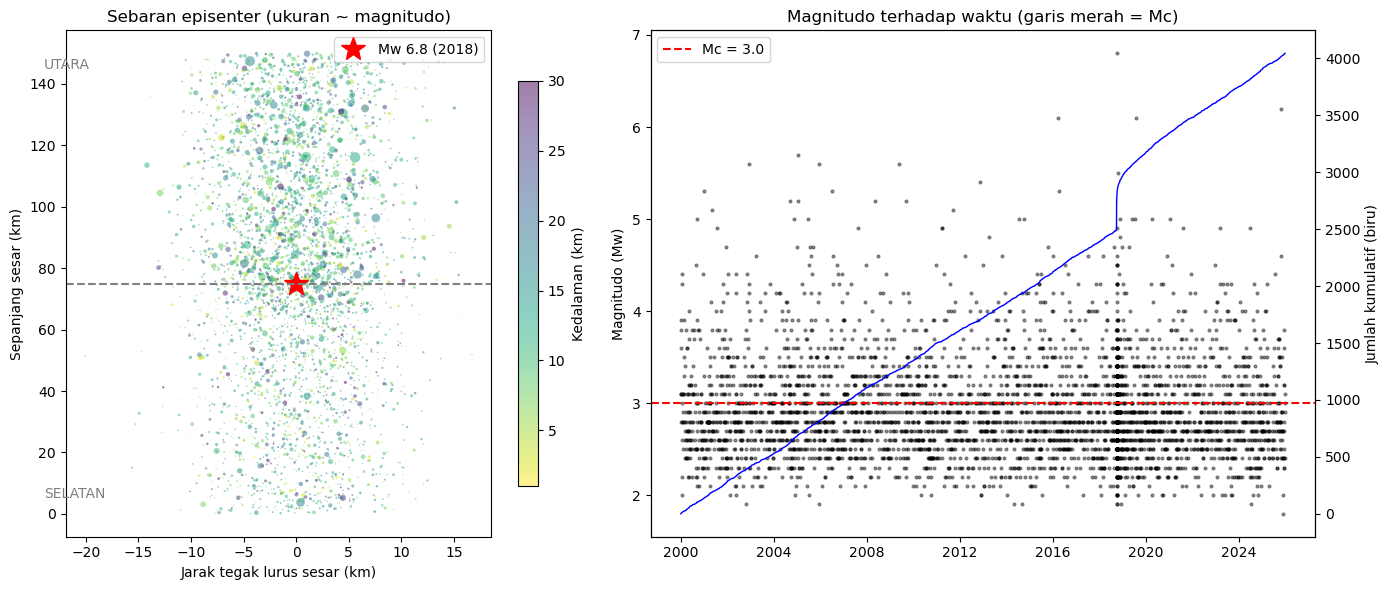

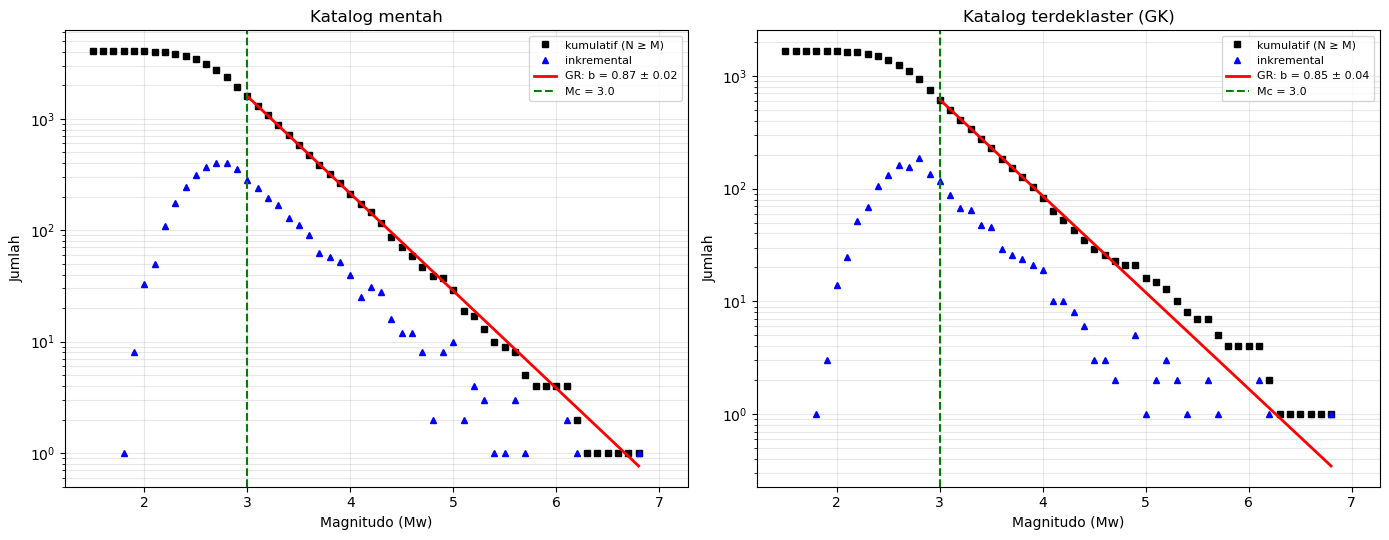

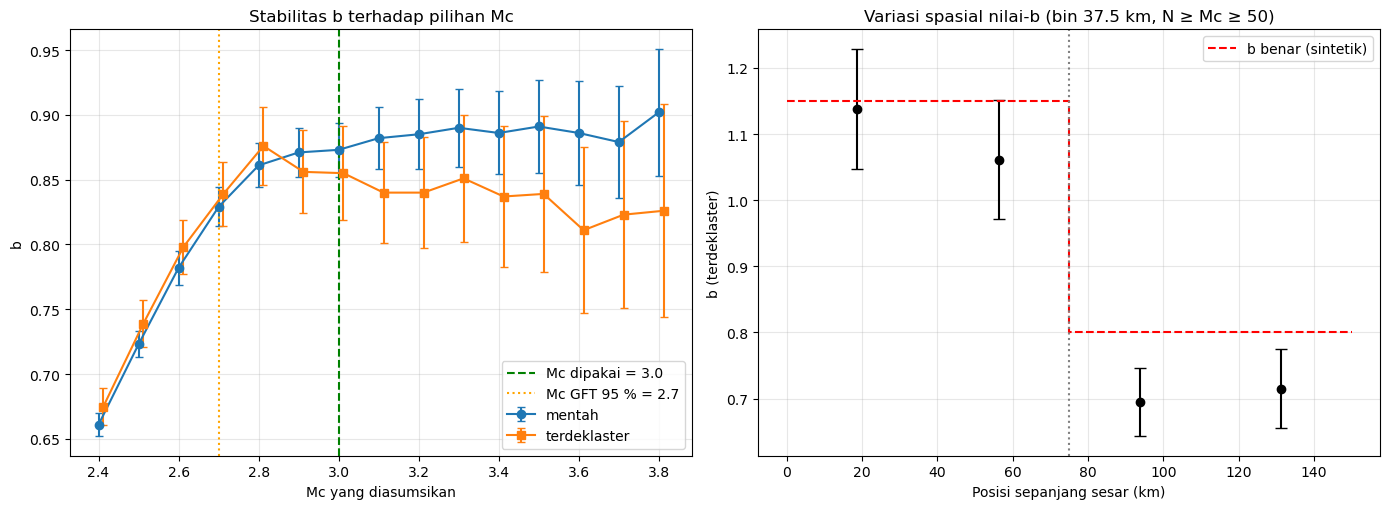

Selesai studi kasus 5.


In [48]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.25]})
sc = ax[0].scatter(kat["off_km"], kat["s_km"], s=(kat["magnitudo"] - 1.5) ** 2.6, c=kat["kedalaman_km"], cmap="viridis_r",
                   alpha=0.5, edgecolor="none")
plt.colorbar(sc, ax=ax[0], label="Kedalaman (km)", shrink=0.8)
ax[0].plot(0, 75, "r*", ms=18, label="Mw 6.8 (2018)")
ax[0].axhline(75, color="gray", ls="--")
ax[0].text(-24, 5, "SELATAN", color="gray")
ax[0].text(-24, 145, "UTARA", color="gray")
ax[0].set_xlabel("Jarak tegak lurus sesar (km)")
ax[0].set_ylabel("Sepanjang sesar (km)")
ax[0].set_title("Sebaran episenter (ukuran ~ magnitudo)")
ax[0].legend(loc="upper right")
ax[1].scatter(kat["waktu"], kat["magnitudo"], s=4, c="k", alpha=0.4)
ax[1].axhline(MC, color="r", ls="--", label=f"Mc = {MC:.1f}")
ax[1].set_ylabel("Magnitudo (Mw)")
ax[1].set_title("Magnitudo terhadap waktu (garis merah = Mc)")
ax2 = ax[1].twinx()
ax2.plot(kat["waktu"], np.arange(1, len(kat) + 1), "b-", lw=1)
ax2.set_ylabel("Jumlah kumulatif (biru)")
ax[1].legend(loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(HASIL, "gambar_1_peta_dan_waktu.png"), dpi=140)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a_, Mx, jud, Mc_ in ((ax[0], M, "Katalog mentah", MC), (ax[1], Mdc, "Katalog terdeklaster (GK)", MC_DC)):
    bins, cnt, kum = fmd(Mx)
    a_.semilogy(bins, kum, "ks", ms=4, label="kumulatif (N ≥ M)")
    a_.semilogy(bins, np.where(cnt > 0, cnt, np.nan), "b^", ms=4, label="inkremental")
    r = b_aki_utsu(Mx, Mc_)
    mm = np.linspace(Mc_, Mx.max(), 50)
    a_.semilogy(mm, 10 ** (r["a"] - r["b"] * mm), "r-", lw=2, label=f"GR: b = {r['b']:.2f} ± {r['sb']:.2f}")
    a_.axvline(Mc_, color="g", ls="--", label=f"Mc = {Mc_:.1f}")
    a_.set_xlabel("Magnitudo (Mw)")
    a_.set_ylabel("Jumlah")
    a_.set_title(jud)
    a_.grid(alpha=0.3, which="both")
    a_.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(HASIL, "gambar_2_FMD_Gutenberg_Richter.png"), dpi=140)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
ax[0].errorbar(scan["Mc"], scan["b mentah"], yerr=scan["galat mentah"], fmt="o-", capsize=3, label="mentah")
ax[0].errorbar(scan["Mc"] + 0.012, scan["b terdeklaster"], yerr=scan["galat terdeklaster"], fmt="s-", capsize=3, label="terdeklaster")
ax[0].axvline(MC, color="g", ls="--", label=f"Mc dipakai = {MC:.1f}")
ax[0].axvline(MC_GFT, color="orange", ls=":", label=f"Mc GFT 95 % = {MC_GFT:.1f}")
ax[0].set_xlabel("Mc yang diasumsikan")
ax[0].set_ylabel("b")
ax[0].set_title("Stabilitas b terhadap pilihan Mc")
ax[0].grid(alpha=0.3)
ax[0].legend()
ok = sepanjang["b"].notna()
ax[1].errorbar(sepanjang.loc[ok, "Tengah (km)"], sepanjang.loc[ok, "b"], yerr=sepanjang.loc[ok, "galat"], fmt="o", capsize=4, color="k")
ax[1].step([0, 75, 75, 150], [1.15, 1.15, 0.80, 0.80], "r--", label="b benar (sintetik)")
ax[1].axvline(75, color="gray", ls=":")
ax[1].set_xlabel("Posisi sepanjang sesar (km)")
ax[1].set_ylabel("b (terdeklaster)")
ax[1].set_title("Variasi spasial nilai-b (bin 37.5 km, N ≥ Mc ≥ 50)")
ax[1].grid(alpha=0.3)
ax[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(HASIL, "gambar_3_sensitivitas_Mc_dan_spasial.png"), dpi=140)
plt.show()

with open(os.path.join(HASIL, "ringkasan_angka.txt"), "w", encoding="utf-8") as f:
    f.write(ring.to_string(index=False) + "\n\n" + tab_b.to_string(index=False) + "\n\n")
    f.write(sepanjang.to_string(index=False) + "\n\n" + gr.to_string(index=False) + "\n")
    f.write(f"\nbeda b selatan-utara = {bS['b']-bU['b']:.3f}, z = {z_beda:.1f}\n")
print("Selesai studi kasus 5.")

---
## 3. Interpretasi

*Ditulis berdasarkan angka dan gambar yang dihasilkan sel-sel di atas (seed tetap, sehingga hasil dapat direproduksi).*

### 1. Kualitas katalog

Tipe magnitudo seragam (Mw), tanpa duplikat, kedalaman 1–30 km, magnitudo 1,8–6,8. Karena tipe seragam, tidak ada konversi yang diperlukan (jika bercampur, skrip berhenti dan meminta keputusan).

![Peta dan waktu](hasil/kasus5/gambar_1_peta_dan_waktu.png)

### 2. Magnitudo kelengkapan (Mc)

| Metode | Mc |
|---|---|
| *Maximum curvature* (MAXC) | 2,8 → **3,0** setelah koreksi +0,2 |
| *Goodness-of-fit* (GFT) 95 % | 2,7 |
| GFT 90 % | 2,6 |

Ketiganya berbeda, jadi saya menguji **stabilitas b terhadap Mc**:

![FMD](hasil/kasus5/gambar_2_FMD_Gutenberg_Richter.png)

![Sensitivitas Mc dan spasial](hasil/kasus5/gambar_3_sensitivitas_Mc_dan_spasial.png)

Nilai b naik dari 0,66 (Mc 2,4) ke 0,83 (Mc 2,7), lalu **mendatar di sekitar Mc ≈ 2,9–3,0** (b ≈ 0,87–0,89 pada katalog mentah). Plateau itu menandai kelengkapan sebenarnya. Maka **Mc = 3,0 dipakai** (cocok dengan MAXC + 0,2), sedangkan GFT 95 % (2,7) **terlalu optimistis** pada kurva deteksi yang landai dan membuat b bias rendah (0,829 vs 0,873). Pemilihan Mc yang terlalu rendah adalah sumber kesalahan paling umum pada analisis b-value.

### 3. Deklasterisasi: temuan yang tidak diduga

| Metode | Kejadian independen | Catatan |
|---|---|---|
| Gardner–Knopoff **penuh** | 528 | 2.912 gempa **latar** ikut terhapus; b = 0,656 ± 0,041 |
| Gardner–Knopoff **terbatas** (hanya M ≥ 5 jadi gempa utama) | 1.658 | 576 susulan terhapus, 36 tersisa; **b = 0,855 ± 0,036** |

Pada katalog berlatar tinggi (±650 kejadian/tahun di 150 km), jendela GK penuh menganggap hampir semua gempa kecil sebagai "susulan" dari gempa yang sedikit lebih besar dan menghapus terutama gempa kecil. Akibatnya b **turun palsu** ke 0,66 (benar ±0,9). Karena itu, varian terbatas dipakai sebagai analisis utama. Pilihan ini saya validasi memakai label sintetik; pada katalog nyata (tanpa label) gunakan beberapa metode deklasterisasi dan laporkan perbedaannya.

### 4. Nilai-b: hasil (Mc = 3,0)

| Skenario | N ≥ Mc | b ± galat |
|---|---|---|
| Semua kejadian (mentah) | 1.591 | 0,873 ± 0,021 |
| Terdeklaster (utama) | 615 | **0,855 ± 0,036** |
| Terdeklaster, Mc + 0,2 (3,2) | 409 | 0,840 ± 0,043 |
| **Segmen selatan** (terdeklaster) | 300 | **1,102 ± 0,064** |
| **Segmen utara** (terdeklaster) | 315 | **0,704 ± 0,039** |
| *Evaluasi: latar saja selatan / utara (label benar)* | 438 / 928 | 1,099 ± 0,052 / 0,775 ± 0,024 |
| Sebelum 2018-09-28 (terdeklaster) | 435 | 0,886 ± 0,045 |
| Sesudah 2018-09-28 (terdeklaster) | 180 | 0,787 ± 0,059 |
| Hanya M ≥ 5,0 | 29 | **tidak dihitung** (N < 50) |

Nilai a (terdeklaster, seluruh periode) = 5,35. Galat dihitung dengan rumus Shi & Bolt.

**Variasi sepanjang sesar** (bin 37,5 km, semua N ≥ 135):

| Segmen (km) | N | b ± galat |
|---|---|---|
| 0–37,5 | 165 | 1,14 ± 0,09 |
| 37,5–75 | 135 | 1,06 ± 0,09 |
| 75–112,5 | 161 | 0,70 ± 0,05 |
| 112,5–150 | 154 | 0,72 ± 0,06 |

### 5. Interpretasi saya

**Perbedaan b antar segmen nyata secara statistik.** Selisih b selatan–utara = 0,40 dengan galat gabungan ±0,075, yaitu z ≈ 5,3. Pola tangga di sepanjang sesar (1,14 → 1,06 → 0,70 → 0,72) mengonfirmasi perubahan mendadak di sekitar 75 km, persis seperti yang dibangkitkan. Metode memulihkan selatan dengan baik (1,10 vs 1,15 benar) tetapi menaksir utara sedikit rendah (0,70 vs 0,80), selisih yang sama dengan pengaruh deklasterisasi pada nilai 0,775 untuk gempa latar murni.

**Tafsir tegangan (kualitatif, dengan kehati-hatian).** Nilai-b rendah (±0,70) di utara sering dikaitkan dengan **proporsi gempa besar yang relatif tinggi dan tegangan diferensial yang relatif tinggi**, sedangkan b ≈ 1,1 di selatan menunjukkan dominasi gempa kecil, yang dikaitkan dengan tegangan lebih rendah atau batuan lebih heterogen/retak. Penafsiran ini punya ketidakpastian: b juga dipengaruhi tipe mekanisme, kedalaman, dan heterogenitas material, dan di sini perbedaan itu sengaja dibangkitkan, bukan diamati dari fisika. Maka segmen utara layak diberi **perhatian pemantauan lebih tinggi**, tetapi ini bukan prediksi gempa.

**Tidak ada bukti perubahan b setelah gempa utama 2018.** b turun dari 0,886 ke 0,787, tetapi selisih 0,10 hanya ±1,3σ (galat gabungan ±0,074), jadi **tidak signifikan**. Perubahan sebesar itu bisa saja karena fluktuasi sampel.

**Konsistensi dengan hukum Gutenberg–Richter (deskriptif):**

| Ambang M ≥ | Teramati (terdeklaster, 26 th) | Ekstrapolasi GR (b = 0,855) |
|---|---|---|
| 4,0 | 82 | 85,9 |
| 5,0 | 16 | 12,0 |
| 6,0 | 4 | 1,7 |

Hingga M ≥ 5, katalog sangat cocok dengan hukum GR. Untuk M ≥ 6, jumlah teramati (4) melebihi ekstrapolasi (1,7). Sampelnya sangat kecil, jadi tidak boleh ditafsirkan sebagai ketidakstasioneran. Perhatikan juga bahwa kedua segmen memiliki b berbeda sehingga satu garis GR untuk seluruh sesar hanya pendekatan kasar.

### 6. Verifikasi (V): sensitivitas

- **Mc + 0,2:** b terdeklaster berubah dari 0,855 ke 0,840 (selisih 0,015 ≪ galat 0,036–0,043). Hasil stabil terhadap pilihan Mc di atas plateau.
- **Deklasterisasi:** b berubah drastis hanya bila metodenya terlalu agresif (0,66); varian terbatas hampir tidak mengubah b dari katalog mentah (0,855 vs 0,873) karena susulan di sini punya b ≈ 1,0 yang dekat dengan rata-rata.
- **Mc = 2,7 (GFT):** menurunkan b mentah sebesar 0,044. Tanda ketidaklengkapan.

### 7. Keterbatasan

Katalog sintetik dengan laju latar stasioner dan Mc homogen secara spasial; jendela GK adalah satu pilihan di antara banyak metode (ETAS, Reasenberg, nearest-neighbor); estimator Aki–Utsu mengandaikan GR berlaku di atas Mc; Mmax dibatasi 6,5 pada gempa latar; galat b mengabaikan ketidakpastian lokasi/magnitudo katalog; N yang kecil per bin (±135–165) memberi galat ±0,05–0,09.